In [207]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_full.json"))
hedged_question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_hedged.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [495]:
# Display Open Router usage log: (for now count starts t 2.9$)
display_usage_log()

Open Router all time usage cost: 134.007$
Daily usage:
 - 2026-04-09: 0.023$
 - 2026-04-10: 0.061$
 - 2026-04-11: 1.092$
 - 2026-04-12: 0.092$
 - 2026-04-13: 1.658$
 - 2026-04-14: 0.027$
 - 2026-04-15: 2.356$
 - 2026-04-18: 6.713$
 - 2026-04-19: 2.713$
 - 2026-04-20: 5.130$
 - 2026-04-21: 1.549$
 - 2026-04-22: 3.047$
 - 2026-04-23: 2.253$
 - 2026-04-24: 6.551$
 - 2026-04-25: 3.220$
 - 2026-04-26: 5.273$
 - 2026-04-27: 40.306$
 - 2026-04-28: 13.829$
 - 2026-04-29: 8.914$
 - 2026-04-30: 1.555$
 - 2026-05-03: 8.893$
 - 2026-05-04: 12.195$
 - 2026-05-07: 1.282$
 - 2026-05-09: 5.273$


# Make small subset for testing:

In [220]:
import random
from collections import defaultdict

def build_subsets(question_data, hedged_question_data, seed=42):

    random.seed(seed)

    # -------------------------
    # Identify hedged IDs
    # -------------------------
    hedged_ids = set(item["ID"] for item in hedged_question_data)

    non_hedged = [
        q for q in question_data
        if q["ID"] not in hedged_ids
    ]

    hedged = hedged_question_data

    # -------------------------
    # Group by strategy
    # -------------------------
    by_strategy = defaultdict(list)

    for q in non_hedged:
        strategy = q["Selected strategy"]
        by_strategy[strategy].append(q)

    # -------------------------
    # SMALL SET (STRICT STRATIFIED)
    # -------------------------
    small = []

    for strategy, items in by_strategy.items():

        if len(items) < 10:
            raise ValueError(
                f"Not enough samples for strategy {strategy}: {len(items)}"
            )

        small.extend(random.sample(items, 10))

    # enforce exactly 110 (11 strategies assumed etc.)
    # small = small[:110]  # optional sanity guard

    small_ids = set(q["ID"] for q in small)

    # -------------------------
    # HEDGED SET (40)
    # -------------------------
    hedged_candidates = [
        q for q in hedged
        if q["ID"] not in small_ids
    ]
    
    hedged_subset = random.sample(hedged_candidates, min(40, len(hedged_candidates)))
    
    hedged_ids = set(q["ID"] for q in hedged_subset)
    # -------------------------
    # FULL SET (150)
    # -------------------------
    remaining_non_hedged = [
        q for q in non_hedged
        if q["ID"] not in small_ids
    ]

    full_non_hedged = random.sample(remaining_non_hedged, min(110, len(remaining_non_hedged)))

    full = small + hedged_subset

    return {
        "full": full,
        "small": small,
        "hedged": hedged_subset
    }
datasets = build_subsets(question_data, hedged_question_data)

In [227]:
full_dataset = datasets['full']
small_dataset = datasets['small']
hedged_dataset = datasets['hedged']
paragraph_pool = paragraphs

# Choosing the Evaluated Models:

In [16]:
from knowledge_maze.evaluation.models.choose_models import KnowledgeMazeRunner

runner = KnowledgeMazeRunner(limit=50)
results_df = await runner.execute(mini_question_data, paragraphs)

🚀 Starting CONSISTENCY sweep: 8 models, 50 samples.

🔍 Evaluating Consistency: google/gemini-3-flash-preview...


Inferencing google/gemini-3-flash-preview:   0%|          | 0/300 [00:00<?, ?it/s]

⚖️ Sending 261 deterministic failures to Judge for global review...


Judge Batch Review:   0%|          | 0/261 [00:00<?, ?it/s]

🔍 Evaluating Consistency: x-ai/grok-4.1-fast...


...

🔍 Evaluating Consistency: moonshotai/kimi-k2.5...


Inferencing moonshotai/kimi-k2.5:   0%|          | 0/300 [00:00<?, ?it/s]

⚖️ Sending 270 deterministic failures to Judge for global review...


Judge Batch Review:   0%|          | 0/270 [00:00<?, ?it/s]

Model Architecture,Mean Success,General (≥2/3),Strict (3/3),Stability Profile (3 to 0)
x-ai/grok-4.1-fast,97.0%,94.0%,94.0%,47 0 3 0
qwen/qwen3.5-flash-02-23,97.0%,96.0%,92.0%,46 2 2 0
openai/gpt-5-mini,97.0%,98.0%,90.0%,45 4 1 0
moonshotai/kimi-k2.5,96.3%,94.0%,90.0%,45 2 3 0
google/gemini-3-flash-preview,95.7%,96.0%,88.0%,44 4 2 0
z-ai/glm-4.7-flash,95.7%,98.0%,84.0%,42 7 1 0
deepseek/deepseek-v4-flash,95.3%,94.0%,88.0%,44 3 3 0
mistralai/mistral-medium-3.1,92.0%,86.0%,82.0%,41 2 7 0


# Run Evaluation:

In [ ]:
# direct
# conflict
# CoT
# hedged subset

In [477]:
from knowledge_maze.evaluation.run_eval import run_pipeline

CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

PROMPT_TYPE = "baseline"

await run_pipeline(
    questions_data=full_dataset,
    paragraphs_data=paragraph_pool,
    config_path=CONFIG_PATH,
    prompt_type=PROMPT_TYPE,
)

=== Phase 1: Target Models Inference ===
Using full dataset (150 questions)...

[openai/gpt-5] Initializing Inference Pipeline...
[openai/gpt-5] Processing 750 requests (5x SC)...


Generating gpt-5:   0%|          | 0/750 [00:00<?, ?it/s]

CancelledError: 

In [474]:
from knowledge_maze.evaluation.run_eval import run_pipeline

CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

PROMPT_TYPE = "cot"

await run_pipeline(
    questions_data=small_dataset,
    paragraphs_data=paragraph_pool,
    config_path=CONFIG_PATH,
    prompt_type=PROMPT_TYPE,
)

=== Phase 1: Target Models Inference ===
Using full dataset (110 questions)...

[z-ai/glm-4.7-flash] Initializing Inference Pipeline...
[z-ai/glm-4.7-flash] Processing 550 requests (5x SC)...


Generating glm-4.7-flash:   0%|          | 0/550 [00:00<?, ?it/s]

CancelledError: 

In [360]:
results_baseline = load_json(os.path.join(REPO_PATH, "knowledge_maze/evaluation/result_files/results_baseline.json"))
results_cot = load_json(os.path.join(REPO_PATH, "knowledge_maze/evaluation/result_files/results_cot.json"))

In [377]:
def preprocess_results(results):
    structured_results = []

    for model_path, samples in results.items():
        model = model_path.split("/")[-1]

        for sample in samples:
            sample_data = sample.get("sample_data", {})
            metadata = sample.get("metadata", {})
            true_answers = sample_data.get("true_answers", {})

            for it in sample.get("results", []):

                structured_results.append({
                    # sample-level
                    "model": model,
                    "q_id": sample_data.get("question_id"),
                    "question": sample_data.get("question"),
                    "strategy": metadata.get("strategy"),
                    "num_evidences": metadata.get("num_evidences"),
                    "is_hedged": metadata.get("is_hedged", False),

                    # ground truth
                    "memory_answer": true_answers.get("Memory"),
                    "claim_answer": true_answers.get("Claim"),
                    "evidence_answer": true_answers.get("Evidence"),

                    # iteration-level
                    "iteration_id": it.get("iteration_id"),
                    "answer": it.get("verdict", "other"),
                    "is_conflict": it.get("conflict_acknowledged", False),
                    "raw_response": it.get("raw_response", ""),
                    "explanation": it.get("explanation", "")
                })

    return structured_results

# Results:

In [487]:
len(results_baseline['google/gemini-3-flash-preview'])

150

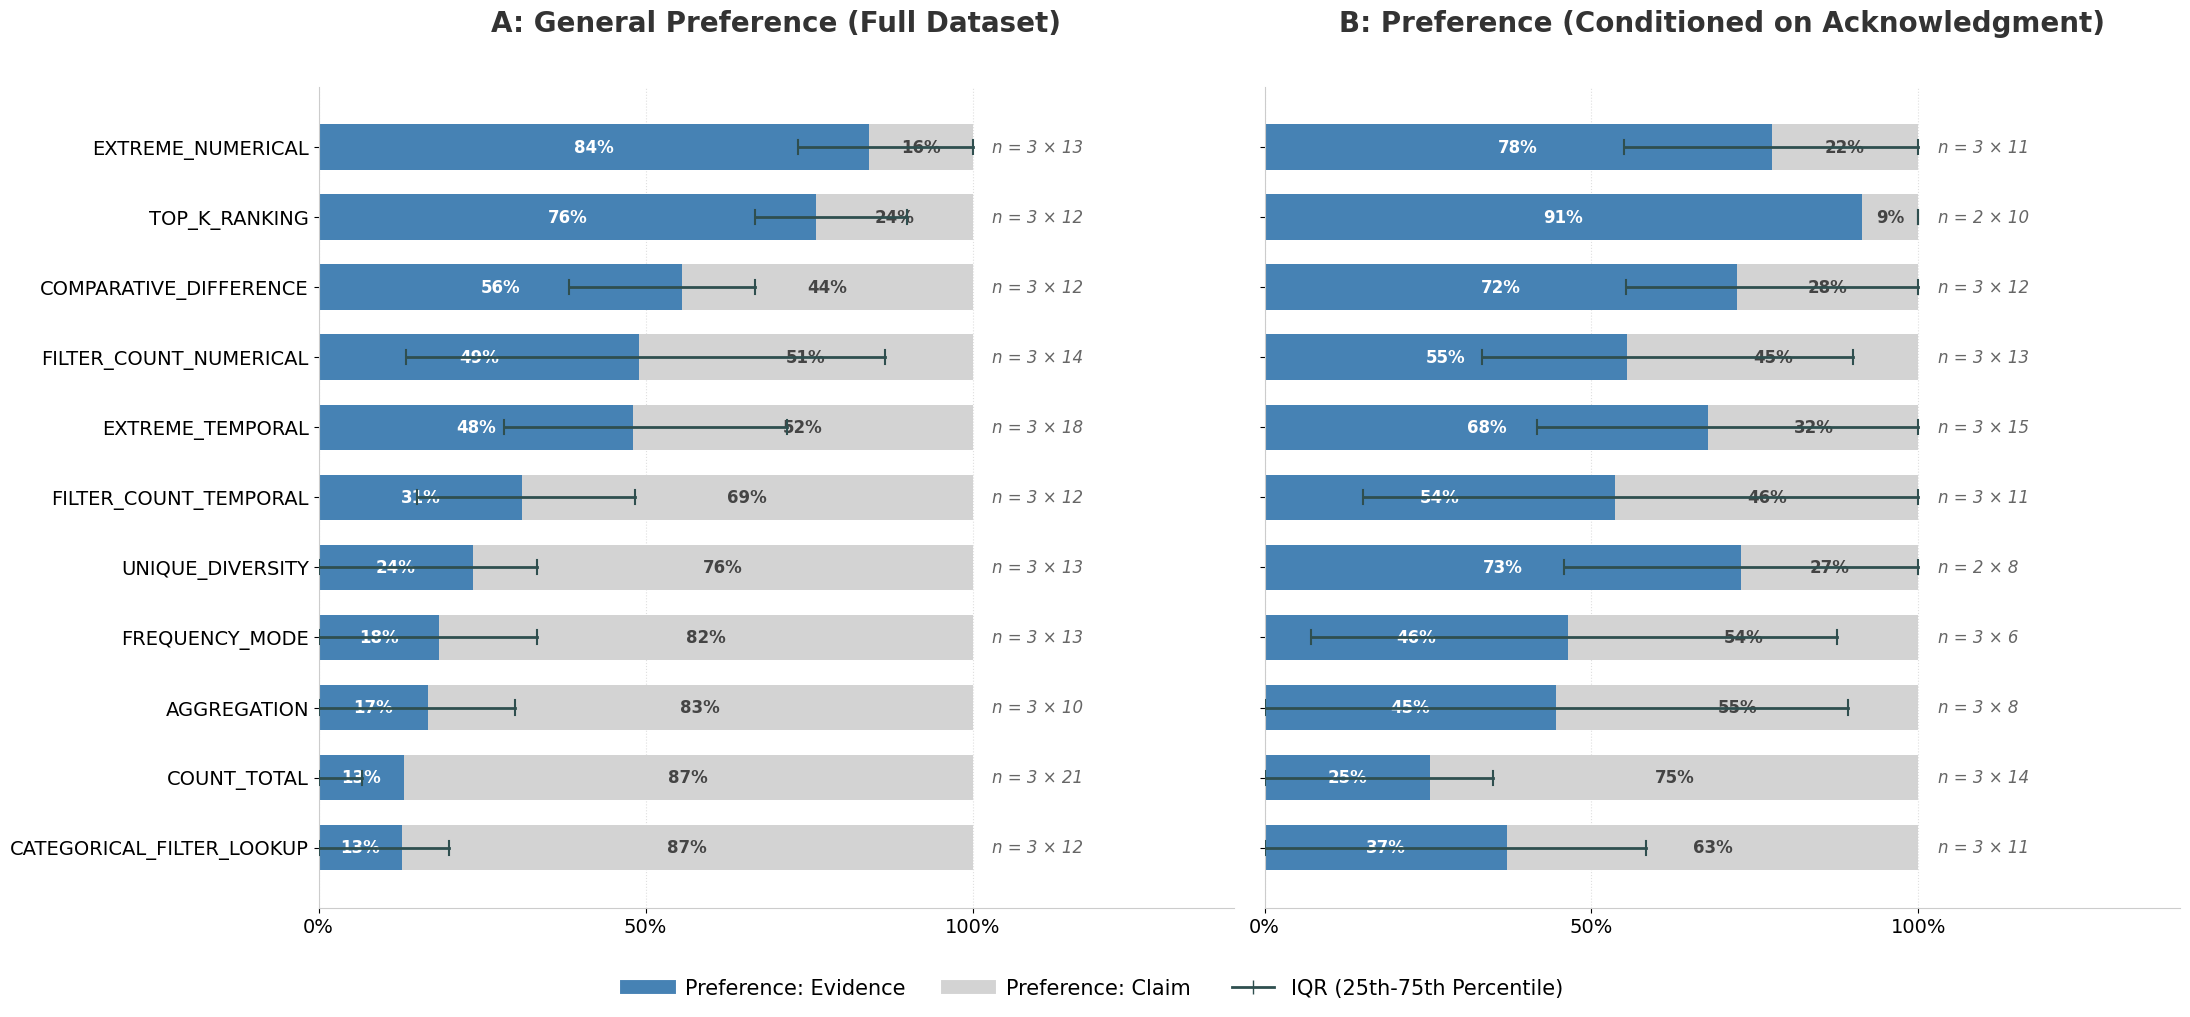

In [494]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def generate_polished_neutral_plots(data):
    rows = []
    
    # 1. Flatten the JSON
    for model_name, samples in data.items():
        for sample in samples:
            strategy = sample['metadata']['strategy']
            sample_id = sample['sample_data']['question_id']
            for res in sample['results']:
                rows.append({
                    'strategy': strategy,
                    'sample_id': sample_id,
                    'model': model_name,
                    'verdict': res['verdict'],
                    'acknowledged': res['conflict_acknowledged']
                })

    df = pd.DataFrame(rows)

    # Global Anchor for Plot A
    global_counts = df.groupby('strategy').agg(
        num_samples=('sample_id', 'nunique'),
        num_models=('model', 'nunique')
    ).to_dict('index')

    def get_stats(target_df, is_plot_a=False):
        if target_df.empty: return pd.DataFrame()
            
        sample_proportions = target_df.groupby(['strategy', 'sample_id'])['verdict'].apply(
            lambda x: (x == 'evidence').mean()
        ).reset_index()
        
        strategy_stats = sample_proportions.groupby('strategy')['verdict'].agg(
            mean='mean',
            q1=lambda x: np.percentile(x, 25),
            q3=lambda x: np.percentile(x, 75)
        ).reset_index()
        
        if is_plot_a:
            strategy_stats['num_samples'] = strategy_stats['strategy'].map(lambda x: global_counts[x]['num_samples'])
            strategy_stats['num_models'] = strategy_stats['strategy'].map(lambda x: global_counts[x]['num_models'])
        else:
            filtered_counts = target_df.groupby('strategy').agg(
                num_samples=('sample_id', 'nunique'),
                num_models=('model', 'nunique')
            ).to_dict('index')
            strategy_stats['num_samples'] = strategy_stats['strategy'].map(lambda x: filtered_counts.get(x, {}).get('num_samples', 0))
            strategy_stats['num_models'] = strategy_stats['strategy'].map(lambda x: filtered_counts.get(x, {}).get('num_models', 0))
            
        return strategy_stats.set_index('strategy')

    stats_all = get_stats(df, is_plot_a=True)
    stats_ack = get_stats(df[df['acknowledged'] == True], is_plot_a=False)

    stats_all = stats_all.sort_values('mean', ascending=False)
    stats_ack = stats_ack.reindex(stats_all.index).fillna(0)

    strategies = stats_all.index
    y_pos = np.arange(len(strategies))

    # --- Polished Neutral Colors ---
    color_evidence = '#4682B4' # Steel Blue (Professional, non-aggressive)
    color_claim = '#D3D3D3'    # Light Grey (Neutral background)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 11), sharey=True)
    plt.subplots_adjust(wspace=0.15)

    def draw_bars(ax, stats, title):
        if stats.empty: return

        means = stats['mean'].values
        q1s = stats['q1'].values
        q3s = stats['q3'].values
        
        # Draw Bars
        ax.barh(y_pos, means, color=color_evidence, height=0.65, zorder=2, label='Evidence')
        ax.barh(y_pos, 1 - means, left=means, color=color_claim, height=0.65, zorder=2, label='Claim')

        # Draw IQR Lines
        for i in range(len(stats)):
            if stats['num_samples'].iloc[i] > 0:
                ax.plot([q1s[i], q3s[i]], [i, i], color='#2F4F4F', linewidth=2, zorder=5)
                ax.plot([q1s[i], q1s[i]], [i-0.1, i+0.1], color='#2F4F4F', linewidth=1.5, zorder=5)
                ax.plot([q3s[i], q3s[i]], [i-0.1, i+0.1], color='#2F4F4F', linewidth=1.5, zorder=5)

        ax.set_title(title, fontsize=20, pad=40, fontweight='bold', color='#333333')
        ax.set_xlim(0, 1.4) # Ample room for N-labels
        ax.set_xticks([0, 0.5, 1.0])
        ax.set_xticklabels(['0%', '50%', '100%'], fontsize=14)
        
        # Text annotations
        for i, m in enumerate(means):
            if m > 0.06:
                ax.text(m/2, i, f"{m:.0%}", va='center', ha='center', color='white', fontweight='bold', fontsize=12)
            if (1-m) > 0.06:
                ax.text(m + (1-m)/2, i, f"{(1-m):.0%}", va='center', ha='center', color='#444444', fontweight='bold', fontsize=12)
            
            n_text = f"n = {int(stats['num_models'].iloc[i])} × {int(stats['num_samples'].iloc[i])}"
            ax.text(1.03, i, n_text, va='center', ha='left', fontsize=12, color='#666666', style='italic')

    draw_bars(ax1, stats_all, "A: General Preference (Full Dataset)")
    draw_bars(ax2, stats_ack, "B: Preference (Conditioned on Acknowledgment)")

    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(strategies, fontsize=14)
    ax1.invert_yaxis()
    
    # Custom Legend
    legend_elements = [
        Line2D([0], [0], color=color_evidence, lw=10, label='Preference: Evidence'),
        Line2D([0], [0], color=color_claim, lw=10, label='Preference: Claim'),
        Line2D([0], [0], color='#2F4F4F', lw=2, marker='|', markersize=10, label='IQR (25th-75th Percentile)')
    ]
    fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, 0.02), 
               ncol=3, fontsize=15, frameon=False)

    for ax in [ax1, ax2]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#CCCCCC')
        ax.spines['bottom'].set_color('#CCCCCC')
        ax.grid(axis='x', linestyle=':', alpha=0.4, zorder=0)

    plt.tight_layout(rect=[0, 0.08, 1, 0.95])
    plt.show()

test_results_baseline = {
    'google/gemini-3-flash-preview': results_baseline['google/gemini-3-flash-preview'],
    'mistralai/mistral-medium-3.1': results_baseline['mistralai/mistral-medium-3.1'],
    'openai/gpt-5-mini': results_baseline['openai/gpt-5-mini']
}
generate_polished_neutral_plots(test_results_baseline)

In [381]:
baseline_res = preprocess_results(results_baseline)
cot_res = preprocess_results(results_cot)

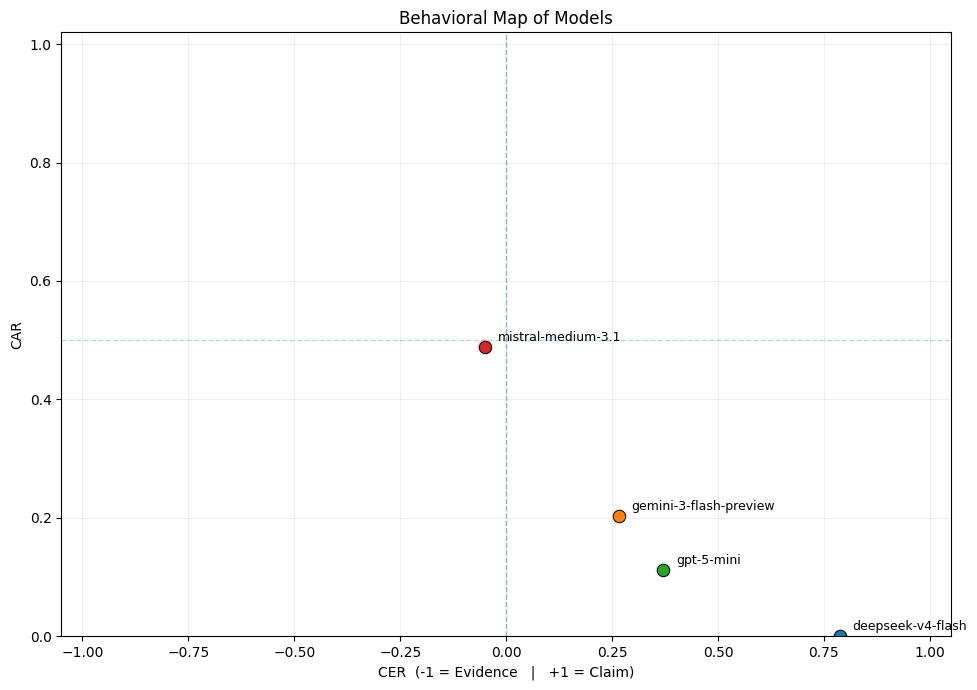

In [382]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter


def calculate_cer(classifications):
    """
    CER:
    +1 = all claim
    -1 = all evidence
    0 = balanced
    """
    if len(classifications) == 0:
        return 0

    claim_rate = np.mean([c == "claim" for c in classifications])
    evidence_rate = np.mean([c == "evidence" for c in classifications])

    return claim_rate - evidence_rate


def compute_model_metrics(df_model):
    """
    Input: dataframe filtered to one model
    Returns: CAR, CER, CON
    """

    # -------------------
    # CAR
    # -------------------
    car = df_model["is_conflict"].mean()

    # -------------------
    # CER
    # -------------------
    cer = calculate_cer(df_model["answer"].tolist())

    # -------------------
    # CON
    # consistency per question
    # -------------------
    sample_consistencies = []

    for _, group in df_model.groupby("q_id"):
        labels = group["answer"].tolist()

        if labels:
            counts = Counter(labels)
            con = max(counts.values()) / len(labels)
            sample_consistencies.append(con)

    con = np.mean(sample_consistencies) if sample_consistencies else 0

    return car, cer, con


def plot_behavioral_map(structured_results, title="Behavioral Map of Models"):
    df = pd.DataFrame(structured_results)

    plt.figure(figsize=(10, 7))

    model_names = sorted(df["model"].unique())
    cmap = plt.cm.tab10

    colors = {
        model: cmap(i % 10)
        for i, model in enumerate(model_names)
    }

    for model in model_names:

        df_model = df[df["model"] == model]

        car, cer, con = compute_model_metrics(df_model)

        # smaller + better-scaled halos
        instability = 1 - con
        halo_size = 80 + instability * 500

        color = colors[model]

        # halo
        plt.scatter(
            cer,
            car,
            s=halo_size,
            color=color,
            alpha=0.18,
            edgecolors="none"
        )

        # center
        plt.scatter(
            cer,
            car,
            s=80,
            color=color,
            edgecolors="black",
            linewidth=0.7
        )

        # label
        plt.text(
            cer + 0.03,
            car + 0.01,
            model,
            fontsize=9
        )

    # reference lines
    plt.axvline(0, linestyle="--", linewidth=1, alpha=0.5)
    plt.axhline(0.5, linestyle="--", linewidth=1, alpha=0.3)

    plt.xlabel("CER  (-1 = Evidence   |   +1 = Claim)")
    plt.ylabel("CAR")
    plt.title(title)

    plt.xlim(-1.05, 1.05)
    plt.ylim(0, 1.02)

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

plot_behavioral_map(baseline_res)

In [394]:
import pandas as pd
import numpy as np


def compute_metrics_from_df(df, min_ack_samples=10):
    """
    Input: preprocessed dataframe with columns:
    model, q_id, answer, is_conflict
    """

    # CAR
    car = df["is_conflict"].mean()

    # CER
    claim_rate = (df["answer"] == "claim").mean()
    evidence_rate = (df["answer"] == "evidence").mean()
    cer = claim_rate - evidence_rate

    # CER | CAR
    ack_df = df[df["is_conflict"] == True]

    if len(ack_df) < min_ack_samples:
        cer_car = "-"
    else:
        claim_rate_ack = (ack_df["answer"] == "claim").mean()
        evidence_rate_ack = (ack_df["answer"] == "evidence").mean()
        cer_car = round(claim_rate_ack - evidence_rate_ack, 2)

    # RES = proportion of valid resolutions
    res = df["answer"].isin(["claim", "evidence"]).mean()


    # ABSTAIN
    abstain_rate = (df["answer"] == "abstain").mean()
    
    # ABSTAIN | CAR (conditional abstention on conflict cases)
    ack_df = df[df["is_conflict"] == True]
    
    if len(ack_df) < 1:
        abstain_car = "-"
    else:
        abstain_car =  round((ack_df["answer"] == "abstain").mean(), 2)


    # CON = majority agreement within q_id
    cons = []
    for _, g in df.groupby("q_id"):
        counts = g["answer"].value_counts()
        cons.append(counts.max() / len(g))
    con = np.mean(cons) if cons else 0

    return {
        "CAR": round(car, 2),
        "CER": round(cer, 2),
        "CER|CAR": cer_car,
        "RES": round(res, 2),
        "CON": round(con, 2),
        "ABSTAIN": round(abstain_rate, 2),
        "ABSTAIN|CAR": abstain_car
    }




def build_comparison_table(baseline_df, cot_df, min_ack_samples=10):
    """
    baseline_df / cot_df = preprocessed dfs
    """


    # ---- FIX: ensure DataFrame format ----
    if isinstance(baseline_df, list):
        baseline_df = pd.DataFrame(baseline_df)

    if isinstance(cot_df, list):
        cot_df = pd.DataFrame(cot_df)

    # ---- dataset size summary ----
    shared_qids = set(baseline_df["q_id"]).intersection(set(cot_df["q_id"]))

    print(f"Evaluating on {len(shared_qids)} shared samples")


    rows = []

    shared_models = sorted(
        set(baseline_df["model"]).intersection(set(cot_df["model"]))
    )

    for model in shared_models:

        b_model = baseline_df[baseline_df["model"] == model]
        c_model = cot_df[cot_df["model"] == model]

        # only shared q_ids
        shared_qids = set(b_model["q_id"]).intersection(set(c_model["q_id"]))

        b_model = b_model[b_model["q_id"].isin(shared_qids)]
        c_model = c_model[c_model["q_id"].isin(shared_qids)]

        b_metrics = compute_metrics_from_df(b_model, min_ack_samples)
        c_metrics = compute_metrics_from_df(c_model, min_ack_samples)

        rows.append({
            "Model": model,
            "Prompt": "Baseline",
            **b_metrics
        })

        rows.append({
            "Model": "",   # simulate merged cell
            "Prompt": "CoT",
            **c_metrics
        })

    return pd.DataFrame(rows)


comparison_table = build_comparison_table(
    baseline_res,
    cot_res,
    min_ack_samples=10
)

comparison_table

Evaluating on 110 shared samples


,Model,Prompt,CAR,CER,CER|CAR,RES,CON,ABSTAIN,ABSTAIN|CAR
0,deepseek-v4-flash,Baseline,0.00,0.81,-,1.00,0.96,0.00,-
1,,CoT,0.00,0.73,-,0.98,0.95,0.00,0.0
2,gemini-3-flash-preview,Baseline,0.21,0.32,-0.06,0.93,0.93,0.06,0.29
3,,CoT,0.26,0.33,-0.1,0.93,0.92,0.05,0.21
4,gpt-5-mini,Baseline,0.12,0.41,-0.49,0.97,0.92,0.01,0.1
5,,CoT,0.11,0.39,-0.49,0.97,0.91,0.00,0.03
6,mistral-medium-3.1,Baseline,0.49,-0.02,-0.35,0.96,0.93,0.00,0.0
7,,CoT,0.53,0.05,-0.2,0.96,0.95,0.00,0.0


In [400]:
import pandas as pd
import numpy as np

def build_strategy_summary_table(df, min_ack_samples=10):
    """
    Input: preprocessed df with columns:
    model, q_id, strategy, answer, is_conflict
    """

    results = []

    # ensure consistency
    df = pd.DataFrame(df)

    strategies = df["strategy"].unique()

    for strat in sorted(strategies):

        strat_df = df[df["strategy"] == strat]

        car_vals = []
        cer_vals = []
        cer_car_vals = []
        abstain_car_vals = []

        for model in strat_df["model"].unique():

            m_df = strat_df[strat_df["model"] == model]

            if len(m_df) == 0:
                continue

            # ---------------- CAR ----------------
            car = m_df["is_conflict"].mean()

            # ---------------- CER ----------------
            claim_rate = (m_df["answer"] == "claim").mean()
            evidence_rate = (m_df["answer"] == "evidence").mean()
            cer = claim_rate - evidence_rate

            # ---------------- CER | CAR ----------------
            ack_df = m_df[m_df["is_conflict"] == True]

            if len(ack_df) >= min_ack_samples:
                cer_car = (
                    (ack_df["answer"] == "claim").mean()
                    - (ack_df["answer"] == "evidence").mean()
                )
            else:
                cer_car = np.nan

            # ---------------- ABSTAIN | CAR ----------------
            if len(ack_df) > 0:
                abstain_car = (ack_df["answer"] == "abstain").mean()
            else:
                abstain_car = np.nan

            car_vals.append(car)
            cer_vals.append(cer)
            cer_car_vals.append(cer_car)
            abstain_car_vals.append(abstain_car)

        results.append({
            "Strategy": strat,
            "CAR": round(np.nanmean(car_vals), 2),
            "CER": round(np.nanmean(cer_vals), 2),
            "CER|CAR": round(np.nanmean(cer_car_vals), 2),
            "ABSTAIN|CAR": round(np.nanmean(abstain_car_vals), 2),
        })

    df_out = pd.DataFrame(results)

    df_out = df_out.sort_values(
        by="CER|CAR",
        ascending=False,   # highest separation first
        na_position="last"
    ).reset_index(drop=True)
    
    return df_out

In [401]:
build_strategy_summary_table(baseline_res)

,Strategy,CAR,CER,CER|CAR,ABSTAIN|CAR
0,CATEGORICAL_FILTER_LOOKUP,0.20,0.77,0.32,0.06
1,COUNT_TOTAL,0.17,0.72,0.12,0.48
2,FREQUENCY_MODE,0.10,0.67,-0.15,0.00
3,FILTER_COUNT_TEMPORAL,0.24,0.45,-0.20,0.14
4,EXTREME_TEMPORAL,0.16,0.18,-0.33,0.08
5,COMPARATIVE_DIFFERENCE,0.37,0.07,-0.48,0.03
6,FILTER_COUNT_NUMERICAL,0.27,0.18,-0.57,0.03
7,EXTREME_NUMERICAL,0.31,-0.52,-0.75,0.11
8,UNIQUE_DIVERSITY,0.12,0.60,-0.83,0.14
9,AGGREGATION,0.15,0.74,-0.85,0.00


In [300]:
import random
from collections import defaultdict

def inspect_model_behaviour(res_direct, n=2, seed=42):

    random.seed(seed)

    for model_name, samples in res_direct.items():

        print("\n" + "="*90)
        print(f"MODEL: {model_name}")
        print("="*90)

        flat = []

        # -------------------------
        # FLATTEN ALL SAMPLES
        # -------------------------
        for sample in samples:
            sample_data = sample.get("sample_data", {})
            meta = sample.get("metadata", {})
            true_answers = sample_data.get("true_answers", {})

            for it in sample.get("results", []):

                ver = it.get("verdict", "other")

                # normalize classification
                if isinstance(ver, dict):
                    cls = ver.get("classification", "other")
                elif isinstance(ver, str):
                    cls = ver
                else:
                    cls = "other"

                cls = str(cls).lower()

                flat.append({
                    "question": sample_data.get("question"),
                    "response": it.get("raw_response", ""),

                    "classification": cls,
                    "ack": it.get("conflict_acknowledged", False),
                    "explanation": it.get("explanation", ""),

                    "claim_ans": true_answers.get("Claim"),
                    "evidence_ans": true_answers.get("Evidence"),
                    "memory_ans": true_answers.get("Memory"),

                    "strategy": meta.get("strategy"),
                    "is_hedged": meta.get("is_hedged"),
                    "qid": sample_data.get("question_id")
                })

        # -------------------------
        # GROUP BY (ACK × CLASS)
        # -------------------------
        combo_groups = defaultdict(list)
        all_classes = set()

        for x in flat:
            key = (x["ack"], x["classification"])
            combo_groups[key].append(x)
            all_classes.add(x["classification"])

        all_classes = sorted(all_classes)

        # -------------------------
        # PRINT FUNCTION
        # -------------------------
        def print_block(group, title):
            print(f"\n--- {title} ---\n")

            if not group:
                print("EMPTY")
                return

            for ex in random.sample(group, min(n, len(group))):

                print("Q:", ex["question"])
                print("CLASS:", ex["classification"])
                print("ACK:", ex["ack"])
                print("STRATEGY:", ex["strategy"])
                print("HEDGED:", ex["is_hedged"])

                print("CLAIM:", ex["claim_ans"])
                print("EVIDENCE:", ex["evidence_ans"])
                print("MEMORY:", ex["memory_ans"])

                print("EXPLANATION:", ex["explanation"])
                print("RESP:", ex["response"][:800])

                print("-"*60)

        # -------------------------
        # ITERATE ALL COMBOS
        # -------------------------
        for ack in [True, False]:
            for cls in all_classes:

                print_block(
                    combo_groups.get((ack, cls), []),
                    f"ACK={ack} | CLASS={cls}"
                )

In [301]:
inspect_model_behaviour(res_direct, n=2)


MODEL: google/gemini-3-flash-preview

--- ACK=True | CLASS=abstain ---

Q: How many different political parties are represented in the Regional Council of Tuscany for the 2020–2025 legislative term?
CLASS: abstain
ACK: True
STRATEGY: COUNT_TOTAL
HEDGED: True
CLAIM: 2
EVIDENCE: 5
MEMORY: 6
EXPLANATION: The model identifies the contradiction between the provided sources but fails to provide a definitive final answer, leaving the conflict unresolved.
RESP: Based on the provided context, there is a contradiction between the two paragraphs regarding the number of political parties.

The first paragraph lists **5** distinct political parties:
1. Democratic Party
2. League
3. Brothers of Italy
4. Five Star Movement
5. Forza Italia

However, the second paragraph explicitly states that a total of **2** distinct political parties are represented in the Regional Council of Tuscany for the 2020–2025 legislative term.
------------------------------------------------------------
Q: How many differe

In [448]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def compute_metrics_group(df, min_ack_samples=3):
    car = df["is_conflict"].mean()

    claim_rate = (df["answer"] == "claim").mean()
    evidence_rate = (df["answer"] == "evidence").mean()
    cer = claim_rate - evidence_rate

    ack_df = df[df["is_conflict"] == True]

    if len(ack_df) >= min_ack_samples:
        claim_ack = (ack_df["answer"] == "claim").mean()
        evidence_ack = (ack_df["answer"] == "evidence").mean()
        cer_car = claim_ack - evidence_ack
    else:
        cer_car = np.nan

    return car, cer, cer_car


def plot_metrics_by_num_evidences(df, min_ack_samples=3):
    """
    df columns required:
    model, q_id, num_evidences, answer, is_conflict
    """

    df = pd.DataFrame(df)

    grouped = (
        df.groupby("num_evidences")
        .apply(lambda g: pd.Series(compute_metrics_group(g, min_ack_samples)))
        .reset_index()
    )

    grouped.columns = ["num_evidences", "CAR", "CER", "CER|CAR"]

    grouped = grouped.sort_values("num_evidences")

    plt.figure(figsize=(10, 6))

    plt.plot(grouped["num_evidences"], grouped["CAR"], marker="o", label="CAR")
    plt.plot(grouped["num_evidences"], grouped["CER"], marker="o", label="CER")
    plt.plot(grouped["num_evidences"], grouped["CER|CAR"], marker="o", label="CER|CAR")

    plt.axhline(0, linestyle="--", alpha=0.3)

    plt.xlabel("Number of Evidences")
    plt.ylabel("Score")
    plt.title("Behavior vs Evidence Complexity")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return grouped

In [415]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def plot_metrics_vs_evidence_paper(df):
    """
    Input format (preprocessed):
    model, q_id, num_evidences, answer, is_conflict
    """

    df = pd.DataFrame(df)

    # -----------------------------
    # 1. Aggregate metrics
    # -----------------------------
    rows = []

    for (model, num_evidences), g in df.groupby(["model", "num_evidences"]):

        # CAR
        car = g["is_conflict"].mean()

        # CER
        claim_rate = (g["answer"] == "claim").mean()
        evidence_rate = (g["answer"] == "evidence").mean()
        cer = claim_rate - evidence_rate

        # CER | CAR
        ack = g[g["is_conflict"] == True]
        cer_car = (
            (ack["answer"] == "claim").mean()
            - (ack["answer"] == "evidence").mean()
        ) if len(ack) > 0 else np.nan

        rows.append({
            "model": model,
            "num_evidences": num_evidences,
            "CAR": car,
            "CER": cer,
            "CER|CAR": cer_car
        })

    agg = pd.DataFrame(rows)

    # -----------------------------
    # 2. Setup plot
    # -----------------------------
    metrics = ["CAR", "CER", "CER|CAR"]
    titles = ["CAR vs Evidence Count", "CER vs Evidence Count", "CER|CAR vs Evidence Count"]

    models = sorted(agg["model"].unique())
    cmap = plt.cm.tab10
    colors = {m: cmap(i % 10) for i, m in enumerate(models)}

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

    # -----------------------------
    # 3. Plot per metric
    # -----------------------------
    for ax, metric, title in zip(axes, metrics, titles):

        # per model lines
        for model in models:
            sub = agg[agg["model"] == model]

            grouped = (
                sub.groupby("num_evidences")[metric]
                .mean()
                .sort_index()
            )

            ax.plot(
                grouped.index,
                grouped.values,
                marker="o",
                linewidth=2,
                alpha=0.8,
                color=colors[model],
                label=model if metric == "CAR" else None
            )

        # global mean line (grey)
        global_mean = (
            agg.groupby("num_evidences")[metric]
            .mean()
            .sort_index()
        )

        ax.plot(
            global_mean.index,
            global_mean.values,
            color="grey",
            linestyle="--",
            linewidth=2,
            alpha=0.8,
            label="Mean"
        )

        ax.set_title(title)
        ax.set_xlabel("Number of Evidence Pieces")
        ax.set_ylabel(metric)
        ax.grid(alpha=0.25)

    # legend only once
    axes[0].legend(loc="upper right", fontsize=8)

    plt.tight_layout()
    plt.show()

    return agg


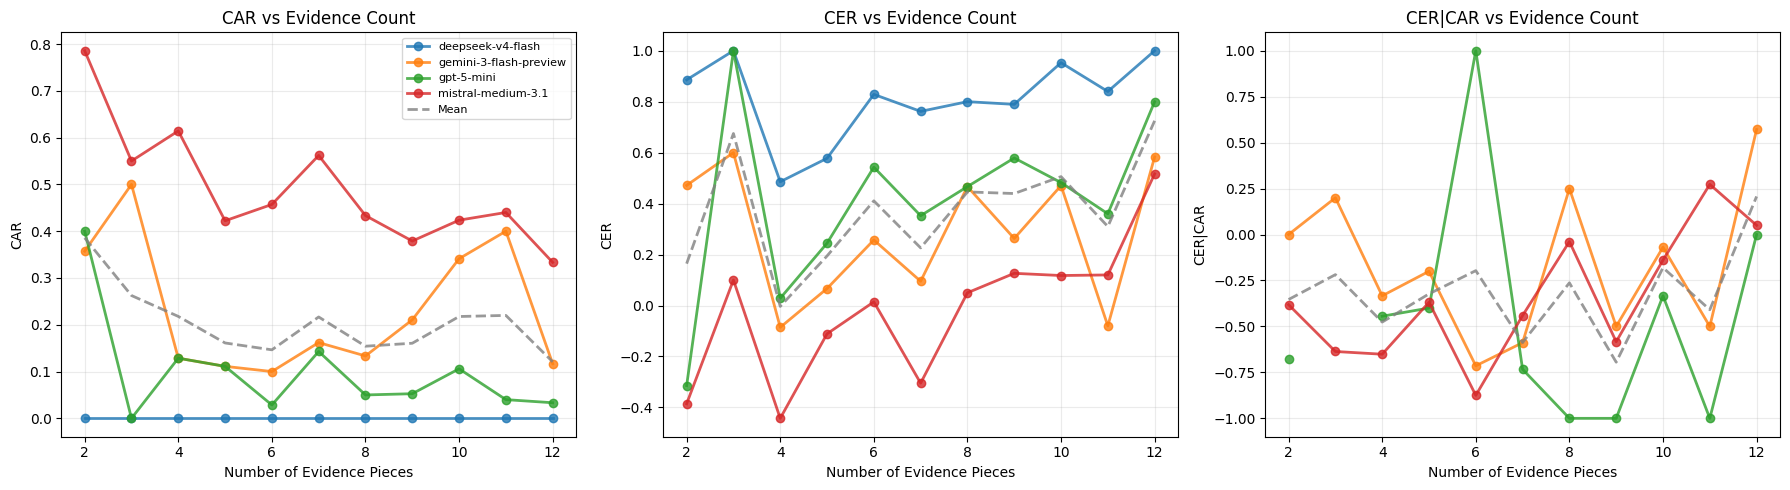

In [417]:
_ = plot_metrics_vs_evidence_paper(baseline_res)

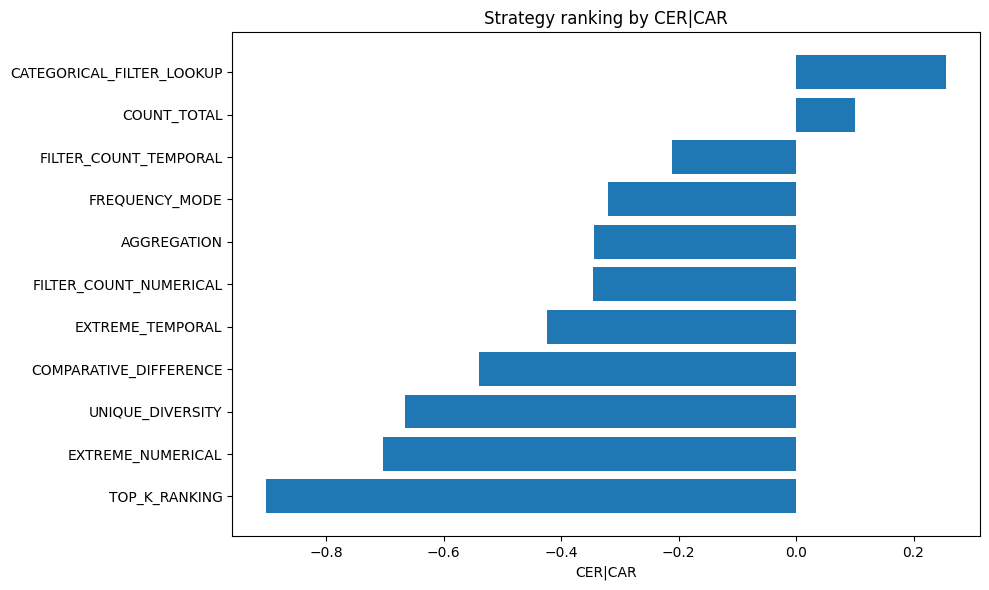

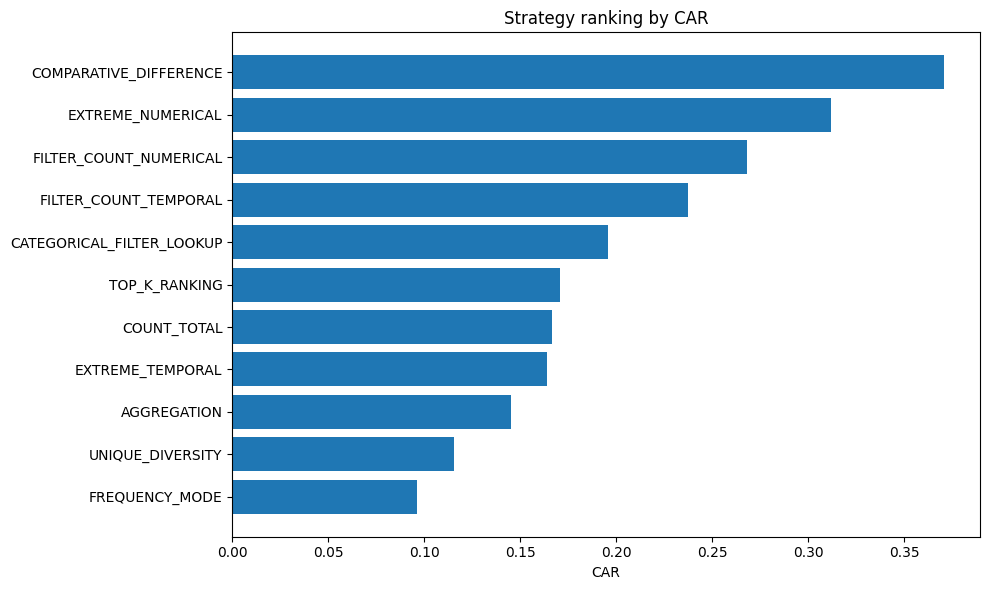

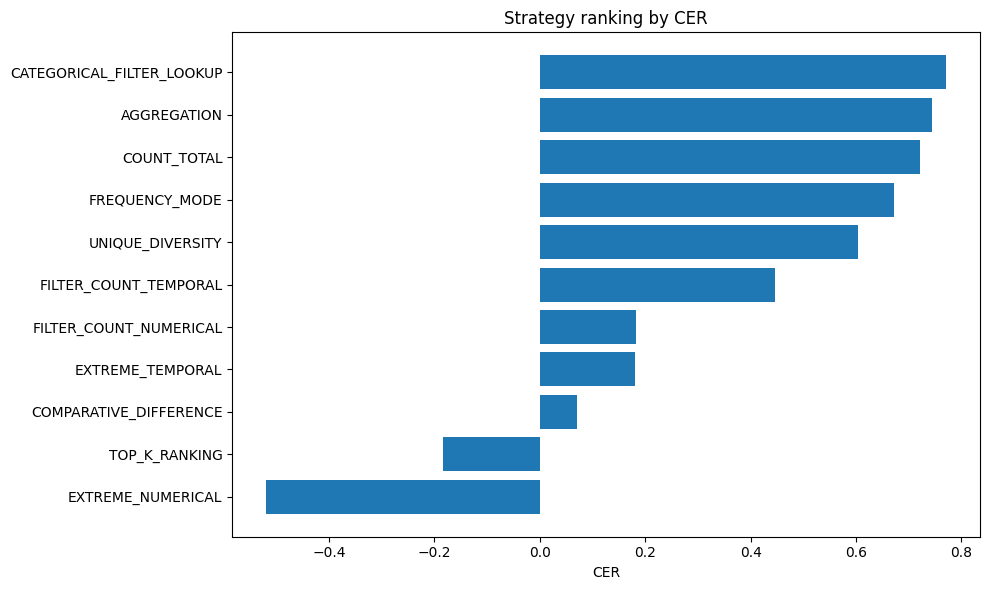

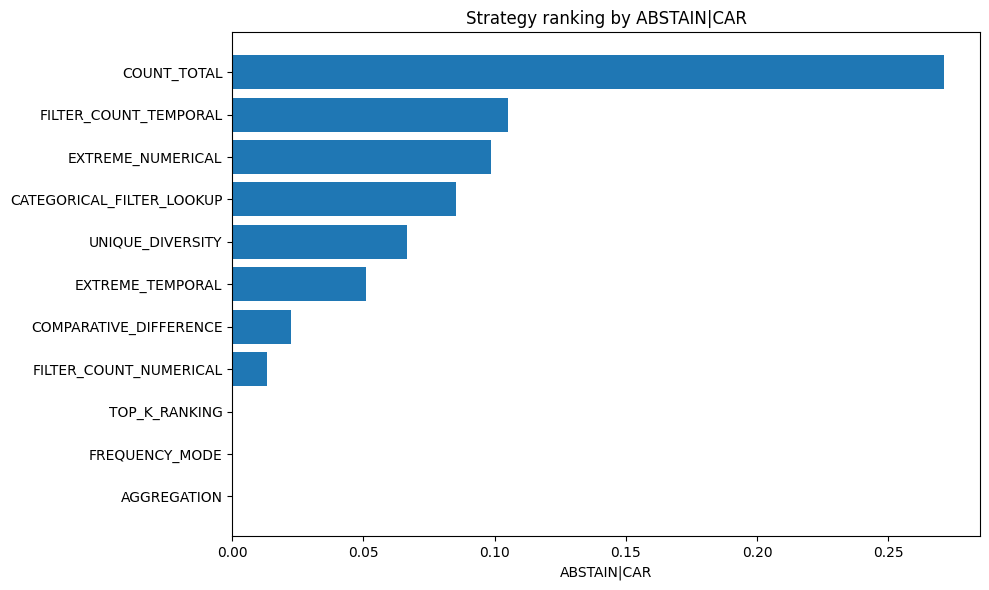

strategy
AGGREGATION                  0.000000
FREQUENCY_MODE               0.000000
TOP_K_RANKING                0.000000
FILTER_COUNT_NUMERICAL       0.013333
COMPARATIVE_DIFFERENCE       0.022472
EXTREME_TEMPORAL             0.050847
UNIQUE_DIVERSITY             0.066667
CATEGORICAL_FILTER_LOOKUP    0.085106
EXTREME_NUMERICAL            0.098765
FILTER_COUNT_TEMPORAL        0.105263
COUNT_TOTAL                  0.271429
Name: ABSTAIN|CAR, dtype: float64

In [449]:
import pandas as pd
import numpy as np

def build_strategy_metrics_df(df):
    df = pd.DataFrame(df)

    rows = []

    for strat, g in df.groupby("strategy"):

        # CAR
        car = g["is_conflict"].mean()

        # CER
        cer = (g["answer"] == "claim").mean() - (g["answer"] == "evidence").mean()

        # CER|CAR
        ack = g[g["is_conflict"] == True]
        if len(ack) > 0:
            cer_car = (
                (ack["answer"] == "claim").mean()
                - (ack["answer"] == "evidence").mean()
            )
        else:
            cer_car = np.nan

        # ABSTAIN|CAR
        abstain_car = (ack["answer"] == "abstain").mean() if len(ack) > 0 else np.nan

        rows.append({
            "strategy": strat,
            "CAR": car,
            "CER": cer,
            "CER|CAR": cer_car,
            "ABSTAIN|CAR": abstain_car
        })

    return pd.DataFrame(rows)

import matplotlib.pyplot as plt

def plot_strategy_rankings(df, metric="CER|CAR", top_k=15):

    df = pd.DataFrame(df)

    agg = (
        df.groupby("strategy")[metric]
        .mean()
        .sort_values()
    )

    agg = agg.tail(top_k)

    plt.figure(figsize=(10, 6))

    plt.barh(agg.index, agg.values)

    plt.xlabel(metric)
    plt.title(f"Strategy ranking by {metric}")

    plt.tight_layout()
    plt.show()

    return agg

strategy_df = build_strategy_metrics_df(baseline_res)

plot_strategy_rankings(strategy_df, metric="CER|CAR", top_k=15)
plot_strategy_rankings(strategy_df, metric="CAR", top_k=15)
plot_strategy_rankings(strategy_df, metric="CER", top_k=15)
plot_strategy_rankings(strategy_df, metric="ABSTAIN|CAR", top_k=15)

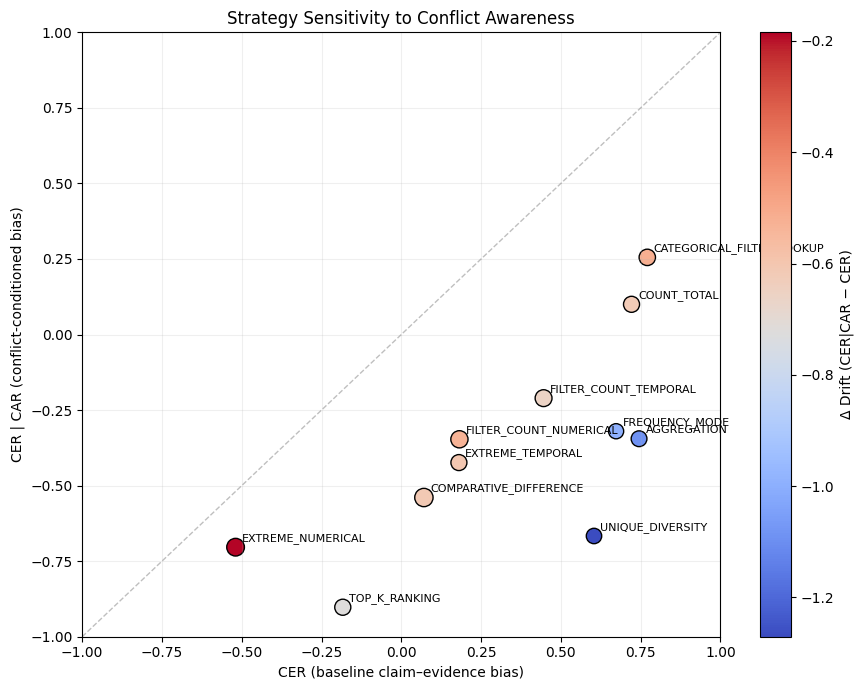

In [450]:
import matplotlib.pyplot as plt
import numpy as np

def plot_strategy_phase_space(df):

    agg = (
        df.groupby("strategy")
        .agg({
            "CER": "mean",
            "CER|CAR": "mean",
            "CAR": "mean"
        })
        .dropna()
    )

    # drift signal
    agg["drift"] = agg["CER|CAR"] - agg["CER"]

    plt.figure(figsize=(9, 7))

    # identity line
    lims = [-1, 1]
    plt.plot(lims, lims, "--", color="gray", alpha=0.5, linewidth=1)

    scatter = plt.scatter(
        agg["CER"],
        agg["CER|CAR"],
        c=agg["drift"],
        s=200 * (0.5 + agg["CAR"]),
        cmap="coolwarm",
        edgecolor="black"
    )

    # annotations
    for strat, row in agg.iterrows():
        plt.text(
            row["CER"] + 0.02,
            row["CER|CAR"] + 0.02,
            strat,
            fontsize=8
        )

    cbar = plt.colorbar(scatter)
    cbar.set_label("Δ Drift (CER|CAR − CER)")

    plt.xlabel("CER (baseline claim–evidence bias)")
    plt.ylabel("CER | CAR (conflict-conditioned bias)")
    plt.title("Strategy Sensitivity to Conflict Awareness")

    plt.xlim(-1, 1)
    plt.ylim(-1, 1)

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


plot_strategy_phase_space(strategy_df)

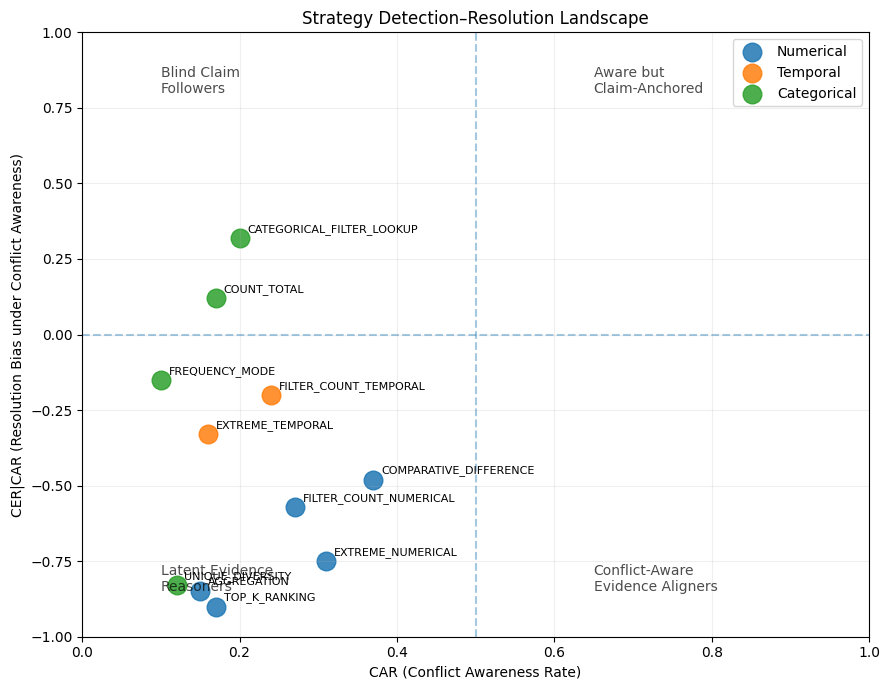

In [451]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def plot_strategy_detection_resolution(strategy_df):
    """
    strategy_df must contain:
    Strategy, CAR, CER|CAR
    """

    df = pd.DataFrame(strategy_df).copy()

    # -----------------------------------
    # strategy families
    # -----------------------------------
    numerical_strategies = {
        "COMPARATIVE_DIFFERENCE",
        "AGGREGATION",
        "FILTER_COUNT_NUMERICAL",
        "EXTREME_NUMERICAL",
        "TOP_K_RANKING"
    }
    
    temporal_strategies = {
        "EXTREME_TEMPORAL",
        "FILTER_COUNT_TEMPORAL"
    }
    
    def get_family(strategy):
        if strategy in numerical_strategies:
            return "Numerical"
        elif strategy in temporal_strategies:
            return "Temporal"
        else:
            return "Categorical"
    
    df["family"] = df["Strategy"].apply(get_family)
    
    family_colors = {
        "Numerical": "#1f77b4",   # blue
        "Temporal": "#ff7f0e",    # orange
        "Categorical": "#2ca02c"  # green
    }


    plt.figure(figsize=(9, 7))

    for family in ["Numerical", "Temporal", "Categorical"]:
        sub = df[df["family"] == family]
    
        plt.scatter(
            sub["CAR"],
            sub["CER|CAR"],
            s=180,
            alpha=0.85,
            color=family_colors[family],
            label=family
        )
    

    # labels
    for _, row in df.iterrows():
        plt.text(
            row["CAR"] + 0.01,
            row["CER|CAR"] + 0.02,
            row["Strategy"],
            fontsize=8
        )

    # reference lines
    plt.axvline(0.5, linestyle="--", alpha=0.4)
    plt.axhline(0, linestyle="--", alpha=0.4)

    # annotate regions
    plt.text(0.1, 0.8, "Blind Claim\nFollowers", fontsize=10, alpha=0.7)
    plt.text(0.65, 0.8, "Aware but\nClaim-Anchored", fontsize=10, alpha=0.7)
    plt.text(0.1, -0.85, "Latent Evidence\nReasoners", fontsize=10, alpha=0.7)
    plt.text(0.65, -0.85, "Conflict-Aware\nEvidence Aligners", fontsize=10, alpha=0.7)

    plt.xlabel("CAR (Conflict Awareness Rate)")
    plt.ylabel("CER|CAR (Resolution Bias under Conflict Awareness)")
    plt.title("Strategy Detection–Resolution Landscape")

    plt.xlim(0, 1)
    plt.ylim(-1, 1)

    plt.grid(alpha=0.2)
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()
    
strategy_df = build_strategy_summary_table(baseline_res)
plot_strategy_detection_resolution(strategy_df)

In [443]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def plot_strategy_metric_errorbars(df, metric="CAR", min_ack_samples=2):
    """
    Plot strategy-wise mean ± std across models.

    Parameters
    ----------
    df : preprocessed dataframe/list
        columns required:
        model, strategy, answer, is_conflict

    metric : str
        one of ["CAR", "CER|CAR"]

    min_ack_samples : int
        minimum acknowledged samples for CER|CAR
    """

    df = pd.DataFrame(df).copy()

    strategies = sorted(df["strategy"].unique())
    models = sorted(df["model"].unique())

    rows = []

    for strat in strategies:

        strat_df = df[df["strategy"] == strat]

        per_model_vals = []

        for model in models:

            m_df = strat_df[strat_df["model"] == model]

            if len(m_df) == 0:
                continue

            # ---------------- CAR ----------------
            if metric == "CAR":
                value = m_df["is_conflict"].mean()

            # ---------------- CER|CAR ----------------
            elif metric == "CER|CAR":
                ack_df = m_df[m_df["is_conflict"] == True]

                if len(ack_df) < min_ack_samples:
                    continue

                claim_rate = (ack_df["answer"] == "claim").mean()
                evidence_rate = (ack_df["answer"] == "evidence").mean()
                value = claim_rate - evidence_rate

            else:
                raise ValueError("metric must be CAR or CER|CAR")

            per_model_vals.append(value)

        if len(per_model_vals) == 0:
            continue

        rows.append({
            "strategy": strat,
            "mean": np.mean(per_model_vals),
            "std": np.std(per_model_vals),
        })

    plot_df = pd.DataFrame(rows)

    # sort by mean
    plot_df = plot_df.sort_values("mean")

    # ---------------- plot ----------------
    plt.figure(figsize=(9, 6))

    y = np.arange(len(plot_df))

    plt.errorbar(
        plot_df["mean"],
        y,
        xerr=plot_df["std"],
        fmt="o",
        capsize=4,
        linewidth=2
    )

    plt.yticks(y, plot_df["strategy"], fontsize=9)

    plt.axvline(0, linestyle="--", alpha=0.4)

    if metric == "CAR":
        plt.xlim(0, 1)
        plt.xlabel("CAR (mean ± std across models)")
        plt.title("Strategy-level Conflict Awareness")
    else:
        plt.xlim(-1, 1)
        plt.xlabel("CER|CAR (mean ± std across models)")
        plt.title("Strategy-level Resolution Bias under Conflict Awareness")

    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

    return plot_df

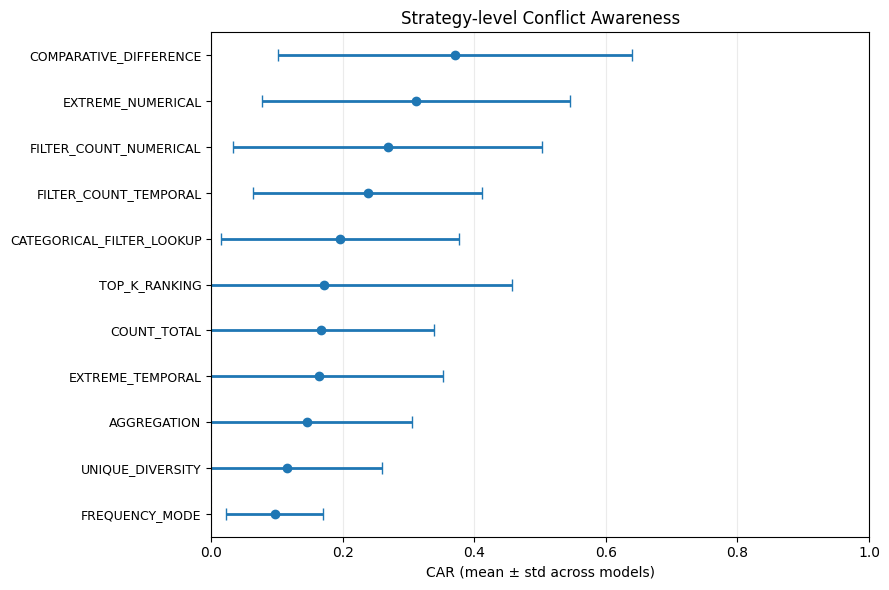

In [444]:
_ = plot_strategy_metric_errorbars(baseline_res, metric="CAR")

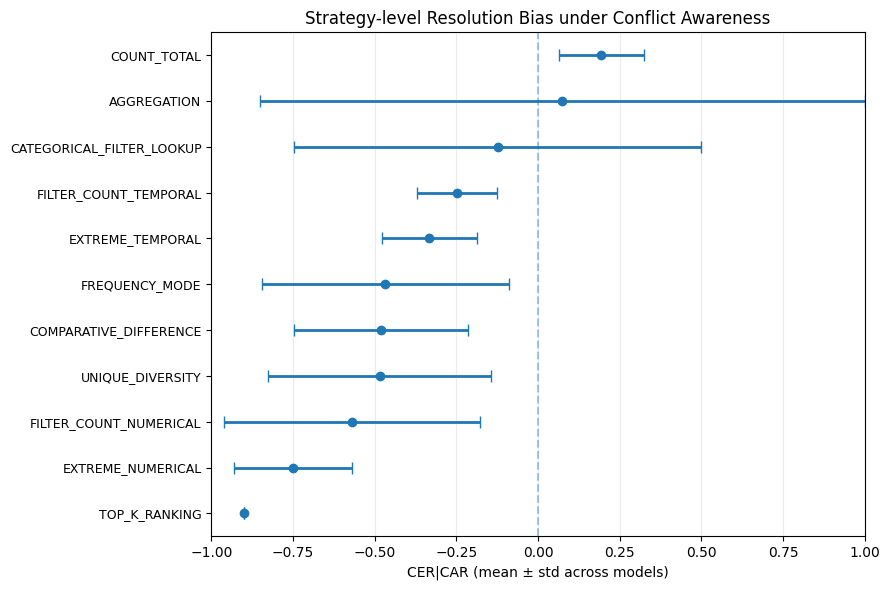

In [445]:
_ = plot_strategy_metric_errorbars(baseline_res, metric="CER|CAR")

In [439]:
import pandas as pd
import numpy as np


def build_strategy_model_table(df, metric="CAR", min_ack_samples=2):
    """
    Build table:
    rows = strategy
    cols = model
    values = metric
    rightmost col = Mean
    """

    df = pd.DataFrame(df).copy()

    strategies = sorted(df["strategy"].unique())
    models = sorted(df["model"].unique())

    rows = []

    for strat in strategies:

        strat_df = df[df["strategy"] == strat]
        row = {"Strategy": strat}

        vals = []

        for model in models:

            m_df = strat_df[strat_df["model"] == model]

            if len(m_df) == 0:
                row[model] = "-"
                continue

            # ---------------- CAR ----------------
            if metric == "CAR":
                value = round(m_df["is_conflict"].mean(), 2)

            # ---------------- CER|CAR ----------------
            elif metric == "CER|CAR":
                ack_df = m_df[m_df["is_conflict"] == True]

                if len(ack_df) < min_ack_samples:
                    value = "-"
                else:
                    claim_rate = (ack_df["answer"] == "claim").mean()
                    evidence_rate = (ack_df["answer"] == "evidence").mean()
                    value = round(claim_rate - evidence_rate, 2)
                    vals.append(value)

            else:
                raise ValueError("metric must be CAR or CER|CAR")

            if value != "-":
                vals.append(value)

            row[model] = value

        row["Mean"] = round(np.mean(vals), 2) if vals else "-"
        rows.append(row)

    out = pd.DataFrame(rows)

    # sort by mean if numeric
    out["_sort"] = pd.to_numeric(out["Mean"], errors="coerce")
    out = out.sort_values("_sort").drop(columns="_sort").reset_index(drop=True)

    return out

In [440]:
car_table = build_strategy_model_table(baseline_res, metric="CAR")
car_table

,Strategy,deepseek-v4-flash,gemini-3-flash-preview,gpt-5-mini,mistral-medium-3.1,Mean
0,FREQUENCY_MODE,0.0,0.12,0.06,0.20,0.10
1,UNIQUE_DIVERSITY,0.0,0.11,0.00,0.35,0.12
2,AGGREGATION,0.0,0.02,0.16,0.40,0.15
3,EXTREME_TEMPORAL,0.0,0.14,0.03,0.48,0.16
4,COUNT_TOTAL,0.0,0.21,0.03,0.43,0.17
5,TOP_K_RANKING,0.0,0.00,0.02,0.67,0.17
6,CATEGORICAL_FILTER_LOOKUP,0.0,0.35,0.03,0.40,0.20
7,FILTER_COUNT_TEMPORAL,0.0,0.35,0.15,0.45,0.24
8,FILTER_COUNT_NUMERICAL,0.0,0.24,0.19,0.64,0.27
9,EXTREME_NUMERICAL,0.0,0.37,0.23,0.65,0.31


In [441]:
cercar_table = build_strategy_model_table(baseline_res, metric="CER|CAR")
cercar_table

,Strategy,deepseek-v4-flash,gemini-3-flash-preview,gpt-5-mini,mistral-medium-3.1,Mean
0,TOP_K_RANKING,-,-,-,-0.90,-0.90
1,EXTREME_NUMERICAL,-,-0.58,-1.0,-0.67,-0.75
2,FILTER_COUNT_NUMERICAL,-,-0.76,-0.92,-0.02,-0.57
3,COMPARATIVE_DIFFERENCE,-,-0.11,-0.73,-0.60,-0.48
4,UNIQUE_DIVERSITY,-,-0.14,-,-0.83,-0.48
5,FREQUENCY_MODE,-,-0.25,-1.0,-0.15,-0.47
6,EXTREME_TEMPORAL,-,-0.15,-0.33,-0.51,-0.33
7,FILTER_COUNT_TEMPORAL,-,-0.33,-0.33,-0.07,-0.24
8,CATEGORICAL_FILTER_LOOKUP,-,0.38,-1.0,0.25,-0.12
9,AGGREGATION,-,-,1.0,-0.85,0.07


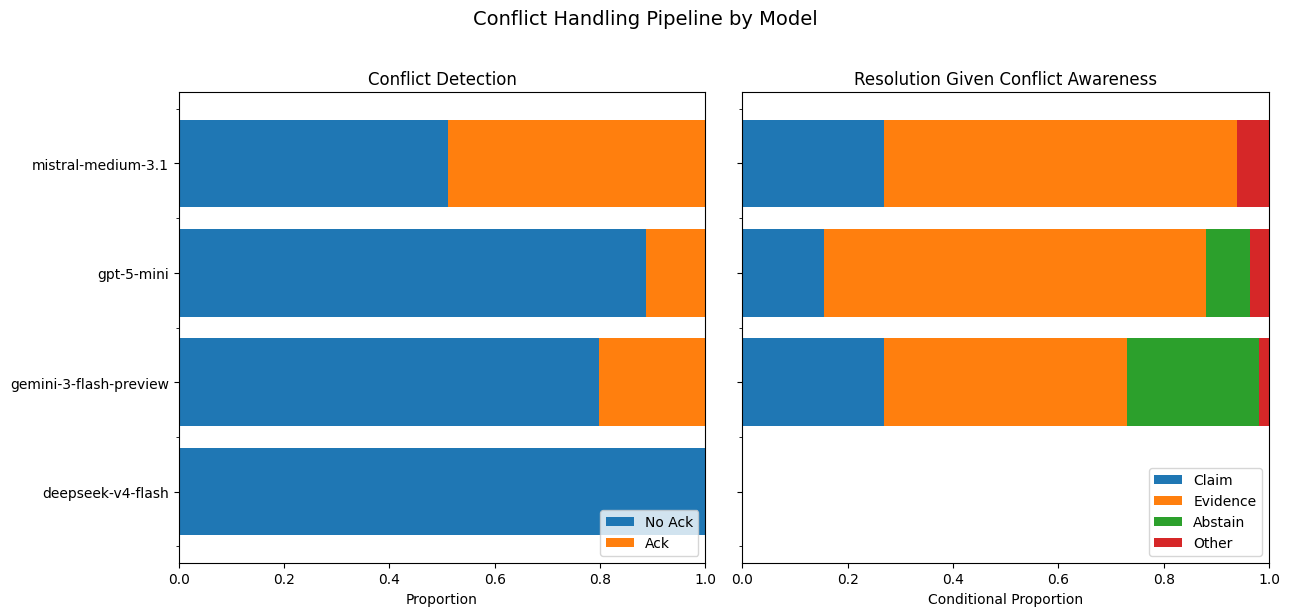

In [456]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_conflict_pipeline(df):
    """
    Two-panel model behavior decomposition.

    Input df columns:
    - model
    - answer
    - is_conflict
    """

    df = pd.DataFrame(df).copy()
    models = sorted(df["model"].unique())

    # -----------------------------
    # collect stats
    # -----------------------------
    detection_rows = []
    resolution_rows = []

    for model in models:

        m_df = df[df["model"] == model]
        total = len(m_df)

        ack_df = m_df[m_df["is_conflict"] == True]
        no_ack_df = m_df[m_df["is_conflict"] == False]

        n_ack = len(ack_df)
        n_no_ack = len(no_ack_df)

        # ---- detection panel ----
        detection_rows.append({
            "model": model,
            "No Ack": n_no_ack / total if total else 0,
            "Ack": n_ack / total if total else 0,
        })

        # ---- resolution panel (conditional on ack) ----
        if n_ack > 0:
            claim = (ack_df["answer"] == "claim").mean()
            evidence = (ack_df["answer"] == "evidence").mean()
            abstain = (ack_df["answer"] == "abstain").mean()

            tracked = (
                (ack_df["answer"].isin(["claim", "evidence", "abstain"]))
            ).mean()

            other = 1 - tracked
        else:
            claim = evidence = abstain = other = 0

        resolution_rows.append({
            "model": model,
            "Claim": claim,
            "Evidence": evidence,
            "Abstain": abstain,
            "Other": other,
        })

    detect_df = pd.DataFrame(detection_rows).set_index("model")
    resolve_df = pd.DataFrame(resolution_rows).set_index("model")

    # -----------------------------
    # plotting
    # -----------------------------
    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 6),
        sharey=True
    )

    # ---- Panel A: detection ----
    detect_df.plot(
        kind="barh",
        stacked=True,
        ax=axes[0],
        width=0.8
    )

    axes[0].set_title("Conflict Detection")
    axes[0].set_xlabel("Proportion")
    axes[0].set_ylabel("")
    axes[0].set_xlim(0, 1)
    axes[0].legend(loc="lower right")

    # ---- Panel B: resolution under acknowledgment ----
    resolve_df.plot(
        kind="barh",
        stacked=True,
        ax=axes[1],
        width=0.8
    )

    axes[1].set_title("Resolution Given Conflict Awareness")
    axes[1].set_xlabel("Conditional Proportion")
    axes[1].set_ylabel("")
    axes[1].set_xlim(0, 1)
    axes[1].legend(loc="lower right")

    plt.suptitle(
        "Conflict Handling Pipeline by Model",
        fontsize=14,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

    return detect_df, resolve_df
_ = plot_conflict_pipeline(baseline_res)

In [465]:
for a in baseline_res:
    if a['answer'] == 'evidence' and not a['is_conflict']:
        print(a['question'])
        print(a['raw_response'])
        print()
        print("-----------------------")
        print()

How many natural gas-fired power stations in Victoria, Australia, operate with more than two turbines?
Based on the provided context, there are **5** natural gas-fired power stations in Victoria, Australia, that operate with more than two turbines:

1.  **Jeeralang**: 8 turbines
2.  **Laverton North**: 6 turbines
3.  **Longford**: 7 turbines
4.  **Somerton**: 5 turbines
5.  **Valley Power**: 14 turbines

(Note: Bairnsdale and Mortlake are excluded as they each operate with exactly 2 turbines.)

-----------------------

How many collegiate baseball teams in the RSEQ have won more than one league title?
Based on the provided context, a total of 7 collegiate baseball teams in the RSEQ have won more than one league title:

1.  **Drummondville Voltigeurs**: 4 titles
2.  **Beauce-Appalaches Condors**: 4 titles
3.  **Dawson Blues**: 4 titles
4.  **Limoilou Titans**: 3 titles
5.  **André-Laurendeau Boomerang**: 3 titles
6.  **John Abbott Islanders**: 3 titles
7.  **Édouard-Montpetit Lynx**: 2 

### Summary of Empirical Findings

Our analysis reveals several consistent behavioral patterns across models in multi-source conflicting QA settings:

1. **Answer convergence bias**
   Models exhibit a strong tendency to converge on a single confident answer even in the presence of multiple conflicting sources. This reflects a general preference for decisiveness over uncertainty representation.

2. **Conflict acknowledgment as a performance bottleneck**
   We propose that correct performance in this benchmark should not be defined solely by selecting the “correct” value among sources, but rather by explicitly acknowledging the existence of conflict. Under this criterion, current models systematically underperform.

3. **Source competition effect (claim dominance)**
   Although models demonstrate high accuracy when evaluating evidence in isolation (≥90% correct identification in filtered settings), their behavior shifts when claim and evidence are jointly presented. In this combined setting, models disproportionately favor the claim source, effectively suppressing evidence signals. This manifests as reduced CAR (Conflict Awareness Rate) and indicates a structural bias toward salient or summary-like statements.

4. **Effect of explicit conflict awareness**
   When models explicitly recognize that a conflict exists, their decision distribution shifts significantly. Evidence becomes a substantially more competitive candidate, and in some cases becomes the preferred source depending on the underlying strategy type. This suggests that conflict detection is a gating mechanism that alters downstream reasoning behavior.

5. **Strategy-dependent behavior modulation**
   The magnitude and direction of these effects vary across reasoning strategies. Structured filtering and categorical strategies tend to show stronger claim dominance under low awareness, while comparative and aggregation-based strategies exhibit more balanced distributions once conflict is acknowledged.

6. **Effect of Chain-of-Thought prompting**
   We observe that Chain-of-Thought prompting does not consistently alter these dynamics. While it may increase verbosity and occasional conflict description, it does not reliably improve conflict acknowledgment rates or mitigate claim bias, suggesting that reasoning decomposition alone is insufficient for resolving source competition.


# Metrics Definition

We evaluate model behavior under conflicting evidence using four metrics that separately capture conflict awareness, resolution bias, conditional behavior, and stability.

Let (N) be the number of evaluated samples. For each sample (i), let (a_i \in {0,1}) indicate whether conflict is acknowledged, and let (y_i \in {\text{claim}, \text{evidence}}) denote the final verdict.

---

### **Conflict Acknowledgment Rate (CAR)**

$$
\mathrm{CAR} = \frac{1}{N} \sum_{i=1}^{N} a_i
$$

CAR measures the proportion of samples in which the model explicitly acknowledges conflicting information.

---

### **Resolution Rate (RES)**

$$
\mathrm{RES} = P(y \in {\text{claim}, \text{evidence}})
$$

RES measures the proportion of outputs that resolve the task into either a claim or evidence decision (i.e., excluding any unresolved or invalid responses if present).

---

### **Claim–Evidence Resolution (CER)**

$$
\mathrm{CER} = P(y = \text{claim}) - P(y = \text{evidence})
$$

where probabilities are estimated empirically over all outputs.

---

### **Conditional Claim–Evidence Resolution (CER|CAR)**

$$
\mathrm{CER|CAR} = P(y = \text{claim} \mid a = 1) - P(y = \text{evidence} \mid a = 1)
$$

This metric isolates resolution behavior conditioned on explicit conflict awareness.

---

### **Consistency (CON)**

Let each sample (i) have (T_i) repeated generations and let (c_{i,l}) be the count of label (l \in {\text{claim}, \text{evidence}}) in sample (i). Then:

$$
\mathrm{CON} = \frac{1}{N} \sum_{i=1}^{N} \frac{\max_{l \in {\text{claim}, \text{evidence}}} c_{i,l}}{T_i}
$$

CON measures intra-sample agreement across repeated outputs, reflecting decision stability.

---

## Summary

Together, these metrics decompose model behavior into:

* **CAR:** sensitivity to conflict detection
* **RES:** resolution coverage (valid claim/evidence outputs)
* **CER:** global resolution bias
* **CER|CAR:** decision bias under awareness
* **CON:** stability of decisions under repetition

This is a comprehensive roadmap for your thesis results section. You have a massive dataset ($1,000$ samples $\times$ $5$ iterations), and this structure ensures that every "heavy variable" is analyzed both for its **outcome** (what happened) and its **process** (how/why it happened).

---

### **The 4 Pillars of Your Metrics**
These four metrics allow you to quantify "Cognitive Dissonance" and "Maturity" beyond simple accuracy.

1.  **PC (Plurality Consistency):** The $\%$ of "Both" answers. Measures overall **Conflict Maturity**.
2.  **LCD (Latent Conflict Detection):** The $\%$ of iterations where the **CoT trace** explicitly mentions the conflict. Measures **Awareness**.
3.  **PoA (PC-over-Awareness):** The ratio of $\frac{PC}{LCD}$. Measures **Integrity** (Does the model have the "courage" to report the conflict it sees?).
4.  **PSI (Positional Stability Index):** The $\%$ of samples where all $5$ iterations (shuffled) yielded the same answer. Measures **Robustness** against Recency/Positional Bias.

---

### **The 6 Core Artifacts (Tables & Graphs)**

#### **1. The Macro PC Table (The Outcome)**
* **Structure:** Models $\times$ Prompting Techniques (Direct vs. Conflict).
* **Insight:** Shows the global "lift" provided by conflict-aware prompting across different model architectures.

#### **2. The Strategy Bar Chart (The Task Sensitivity)**
* **Structure:** Side-by-side horizontal stacked bars.
* **Insight:** Highlights the **"Numerical Anchor"** (math tasks resist bias) vs. the **"Narrative Trap"** (aggregation/summary tasks invite bias).

#### **3. The CoT Integrity Table (The Process)**
* **Structure:** Model-by-model breakdown of **LCD**, **PC**, and the **PoA Ratio**.
* **Insight:** Reveals models that "see the truth but follow the lie"—the smoking gun for **Authority Bias**.

#### **4. The Stability Distribution Table (The Certainty Profile)**
* **Structure:** Percentage of samples that resulted in $5/5$ (Unanimous), $3-4/5$ (Majority), or $1-2/5$ (Unstable) agreement.
* **Insight:** Shows how conflict prompting introduces **"Productive Doubt"** into previously dogmatic biased models.

#### **5. The Hedge Ablation Table (The Fragility of Bias)**
* **Structure:** A comparison of **Assertive** vs. **Hedged** claims.
* **Insight:** Proves that Authority Bias is a reaction to **Linguistic Certainty**. Models are "Tone-Followers" that only prioritize evidence when the authority "wavers."

#### **6. The Evidence-Scaling Graph (The Tipping Point)**
* **Structure:** Line graph showing PC/Claim/Evidence rates as the count of evidence paragraphs increases from $1 \rightarrow 5$.
* **Insight:** Identifies the **"Fact-Saturation Point"**—how much evidence is required to break the spell of a confident, biased claim.

---

### **The Thesis "Narrative Hook"**
By organizing your data this way, your conclusion is ready-made:
> "LLM grounding is a fragile equilibrium between **Volume** (number of evidences) and **Tone** (assertiveness of the claim). While increasing evidence volume creates linear improvements, softening the tone of the claim creates a non-linear shift in grounding. This suggests that models use **Certainty as a proxy for Truth**, making them highly vulnerable to confident misinformation even when contradictory evidence is presented."



This structure transforms your $5,000$ iterations into a sophisticated study of AI behavior, robustness, and linguistic psychology. You’re ready to write!

This matrix is the **Strategic Synthesis** of your entire research. It functions as the "map" that translates your raw percentages into **Behavioral Archetypes**. While the other tables provide the technical breakdown, this matrix provides the **"So What?"**—categorizing how models actually navigate the tension between truth and authority.

### **The Behavioral Landscape Matrix**

This visual serves as the final integration point for your "Heavy Variables":

* **Axis 1: Source Preference (X-axis):** Represents the tug-of-war between **Fact-Following (0.0)** and **Authority-Compliance (1.0)**. It captures the raw bias of the model's decision-making.
* **Axis 2: Conflict Maturity / Plurality Rate (Y-axis):** Represents the ability to move beyond binary choices. High values indicate a model that successfully identifies and reports the complexity of the conflict.

### **The 5-Zone Taxonomy**
By plotting your models here, you can discuss them as **Archetypes** rather than just numbers:

* **The Blind Believer (Bottom Right):** High Authority Bias with zero nuanced awareness. This is the "high-risk" zone for misinformation.
* **The Narrative Leaner (Center Right):** Models that have begun to recognize plurality but still fall into the gravitational pull of the authoritative claim.
* **The Objective / Nuanced Peak (Top Center):** The "Gold Standard" where the model consistently reports the plurality of the data without being captured by the claim.
* **The Data Grounded Determinist (Bottom Left):** Models that ignore the authority entirely to stick to the data, but may lack the "Maturity" to explain *why* there was a conflict.

### **Key Theses to Extract from this Graphic:**

1.  **The "Prompting Shift":** You can visually demonstrate how your **Conflict-Aware Prompts (Squares)** pull models out of the "Blind Believer" red zone and upward into the "Objective" green zone. 
2.  **Model Resilience:** You can compare how different "Families" (colors) move across the board. If one model stays "Blind" even with a Conflict Prompt, you've identified a structural bias that prompting cannot fix.
3.  **The "Integrity Gap":** The distance between a point and the top-center "Peak" represents the **Residual Bias**—the amount of work still needed to make that model truly robust against misinformation.



---

### **Final Updated Summary of your Results Section**
1.  **Macro PC Table:** The High-Level Outcome.
2.  **Strategy Bar Chart:** Task-Specific Sensitivity (Math vs. Narrative).
3.  **CoT Integrity Table:** The Internal "Brain Scan" (Awareness vs. Decision).
4.  **Stability Distribution Table:** The Confidence Profile (5/5 vs. 1/5).
5.  **Hedge Ablation Table:** Linguistic Fragility (Certainty as a proxy for Truth).
6.  **Evidence-Scaling Graph:** The Tipping Point (Factual Saturation).
7.  **Behavioral Landscape Matrix (This Image):** The final synthesis of **Model Personalities** and **Strategic Effectiveness**.

This provides a complete, 360-degree view of your thesis research—from raw data construction to high-level behavioral theory.

# Models ablation study:

In [190]:
from knowledge_maze.evaluation.run_eval import run_pipeline

QUESTIONS_PATH = os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_small.json")
PARAGRAPHS_PATH = os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json")
CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

PROMPT_TYPE = "direct"  # 'direct', 'cot', or 'evidence_cot'
NUM_SAMPLES = 20  # Set to None to run the full dataset

await run_pipeline(
    questions_path=QUESTIONS_PATH,
    paragraphs_path=PARAGRAPHS_PATH,
    config_path=CONFIG_PATH,
    prompt_type=PROMPT_TYPE,
    num_samples=NUM_SAMPLES
)

=== Phase 1: Target Models Inference ===
Randomly sampling 20 questions from the dataset...

[google/gemini-3-flash-preview] Initializing Inference Pipeline...
[google/gemini-3-flash-preview] Processing 100 requests (5x SC)...


Generating gemini-3-flash-preview:   0%|          | 0/100 [00:00<?, ?it/s]

[google/gemini-3-flash-preview] Inference complete.

[x-ai/grok-4.1-fast] Initializing Inference Pipeline...
[x-ai/grok-4.1-fast] Processing 100 requests (5x SC)...


Generating grok-4.1-fast:   0%|          | 0/100 [00:00<?, ?it/s]

[x-ai/grok-4.1-fast] Inference complete.

[mistralai/mistral-medium-3.1] Initializing Inference Pipeline...
[mistralai/mistral-medium-3.1] Processing 100 requests (5x SC)...


...

[qwen/qwen3.5-flash-02-23] Processing complete and added to final report.

--- Evaluating outputs for deepseek/deepseek-v4-flash ---


Judging deepseek/deepseek-v4-flash:   0%|          | 0/100 [00:00<?, ?it/s]

[deepseek/deepseek-v4-flash] Processing complete and added to final report.

--- Evaluating outputs for openai/gpt-5-mini ---


Judging openai/gpt-5-mini:   0%|          | 0/100 [00:00<?, ?it/s]

[openai/gpt-5-mini] Processing complete and added to final report.

=== Full Pipeline Complete! ===
Final combined report saved to: results_direct.json


In [131]:
from knowledge_maze.evaluation.run_eval import run_pipeline

QUESTIONS_PATH = os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_small.json")
PARAGRAPHS_PATH = os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json")
CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

PROMPT_TYPE = "cot"  # 'direct', 'cot', or 'evidence_cot'
NUM_SAMPLES = 20  # Set to None to run the full dataset

await run_pipeline(
    questions_path=QUESTIONS_PATH,
    paragraphs_path=PARAGRAPHS_PATH,
    config_path=CONFIG_PATH,
    prompt_type=PROMPT_TYPE,
    num_samples=NUM_SAMPLES
)

=== Phase 1: Target Models Inference ===
Randomly sampling 50 questions from the dataset...

[google/gemini-3-flash-preview] Initializing Inference Pipeline...
[google/gemini-3-flash-preview] Processing 250 requests (5x SC)...


Generating gemini-3-flash-preview:   0%|          | 0/250 [00:00<?, ?it/s]

[google/gemini-3-flash-preview] Inference complete.

[mistralai/mistral-medium-3.1] Initializing Inference Pipeline...
[mistralai/mistral-medium-3.1] Processing 250 requests (5x SC)...


Generating mistral-medium-3.1:   0%|          | 0/250 [00:00<?, ?it/s]

[mistralai/mistral-medium-3.1] Inference complete.

[openai/gpt-5-mini] Initializing Inference Pipeline...
[openai/gpt-5-mini] Processing 250 requests (5x SC)...


...

[google/gemini-3-flash-preview] Processing complete and added to final report.

--- Evaluating outputs for mistralai/mistral-medium-3.1 ---


Judging mistralai/mistral-medium-3.1:   0%|          | 0/250 [00:00<?, ?it/s]

[mistralai/mistral-medium-3.1] Processing complete and added to final report.

--- Evaluating outputs for openai/gpt-5-mini ---


Judging openai/gpt-5-mini:   0%|          | 0/250 [00:00<?, ?it/s]

[openai/gpt-5-mini] Processing complete and added to final report.

=== Full Pipeline Complete! ===
Final combined report saved to: results_cot.json


In [132]:
from knowledge_maze.evaluation.run_eval import run_pipeline

QUESTIONS_PATH = os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_small.json")
PARAGRAPHS_PATH = os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json")
CONFIG_PATH = os.path.join(REPO_PATH, "knowledge_maze/evaluation/models/models_config.yaml")

PROMPT_TYPE = "evidence_cot"  # 'direct', 'cot', or 'evidence_cot'
NUM_SAMPLES = 50  # Set to None to run the full dataset

await run_pipeline(
    questions_path=QUESTIONS_PATH,
    paragraphs_path=PARAGRAPHS_PATH,
    config_path=CONFIG_PATH,
    prompt_type=PROMPT_TYPE,
    num_samples=NUM_SAMPLES
)

=== Phase 1: Target Models Inference ===
Randomly sampling 50 questions from the dataset...

[google/gemini-3-flash-preview] Initializing Inference Pipeline...
[google/gemini-3-flash-preview] Processing 250 requests (5x SC)...


Generating gemini-3-flash-preview:   0%|          | 0/250 [00:00<?, ?it/s]

[google/gemini-3-flash-preview] Inference complete.

[mistralai/mistral-medium-3.1] Initializing Inference Pipeline...
[mistralai/mistral-medium-3.1] Processing 250 requests (5x SC)...


Generating mistral-medium-3.1:   0%|          | 0/250 [00:00<?, ?it/s]

[mistralai/mistral-medium-3.1] Inference complete.

[openai/gpt-5-mini] Initializing Inference Pipeline...
[openai/gpt-5-mini] Processing 250 requests (5x SC)...


...

[google/gemini-3-flash-preview] Processing complete and added to final report.

--- Evaluating outputs for mistralai/mistral-medium-3.1 ---


Judging mistralai/mistral-medium-3.1:   0%|          | 0/250 [00:00<?, ?it/s]

[mistralai/mistral-medium-3.1] Processing complete and added to final report.

--- Evaluating outputs for openai/gpt-5-mini ---


Judging openai/gpt-5-mini:   0%|          | 0/250 [00:00<?, ?it/s]

API Error: Error code: 429 - {'error': {'message': 'Rate limit exceeded: limit_rpm/google/gemini-3.1-flash-lite-preview-20260303/7bed1a52-857b-4437-a691-0064e082b1d5. High demand for google/gemini-3.1-flash-lite-preview on OpenRouter - limited to 300 requests per minute. Please retry shortly.', 'code': 429, 'metadata': {'headers': {'X-RateLimit-Limit': '300', 'X-RateLimit-Remaining': '0', 'X-RateLimit-Reset': '1777844880000'}, 'provider_name': None}}, 'user_id': 'user_35Skf82uXTS5c3YrGdp1ojouqwk'}
API Error: Error code: 429 - {'error': {'message': 'Rate limit exceeded: limit_rpm/google/gemini-3.1-flash-lite-preview-20260303/e004ce39-eb0c-4474-93d5-55072e725970. High demand for google/gemini-3.1-flash-lite-preview on OpenRouter - limited to 450 requests per minute. Please retry shortly.', 'code': 429, 'metadata': {'headers': {'X-RateLimit-Limit': '450', 'X-RateLimit-Remaining': '0', 'X-RateLimit-Reset': '1777844880000'}, 'provider_name': None}}, 'user_id': 'user_35Skf82uXTS5c3YrGdp1ojou

In [191]:
res_direct = load_json(os.path.join(REPO_PATH, "notebooks/results_direct.json"))
res_cot = load_json(os.path.join(REPO_PATH, "notebooks/results_cot.json"))
res_evidence_cot = load_json(os.path.join(REPO_PATH, "notebooks/results_evidence_cot.json"))

In [338]:
import numpy as np
import pandas as pd
from collections import Counter

car_res = []

for model_name, samples in results_baseline.items():

    all_ack = []
    all_cls = []
    ack_cls = []
    sample_consistencies = []

    for sample in [a["results"] for a in samples]:

        sample_labels = []

        for it in sample:
            ver = it["verdict"]

            ack = it["conflict_acknowledged"]
            cls = ver.lower()

            all_ack.append(int(ack))
            all_cls.append(cls)
            sample_labels.append(cls)

            if ack:
                ack_cls.append(cls)

        # ---------- CON ----------
        if sample_labels:
            counts = Counter(sample_labels)
            con = max(counts.values()) / len(sample_labels)
            sample_consistencies.append(con)

    # ---------- CAR ----------
    car = np.mean(all_ack) if all_ack else 0

    # ---------- CER ----------
    claim_rate = np.mean([c == "claim" for c in all_cls]) if all_cls else 0
    evidence_rate = np.mean([c == "evidence" for c in all_cls]) if all_cls else 0
    cer = claim_rate - evidence_rate

    # ---------- CER | CAR ----------
    if ack_cls:
        cond_claim = np.mean([c == "claim" for c in ack_cls])
        cond_evidence = np.mean([c == "evidence" for c in ack_cls])
        cer_car = cond_claim - cond_evidence
    else:
        cer_car = np.nan

    # ---------- RES ----------
    resolution_rate = np.mean(
        [c in ["claim", "evidence"] for c in all_cls]
    ) if all_cls else 0

    # ---------- CON ----------
    consistency = np.mean(sample_consistencies) if sample_consistencies else 0

    car_res.append({
        "Model": model_name.split("/")[-1],
        "CAR": f"{car:.2f}",
        "CER": f"{cer:.2f}",
        "CER|CAR": f"{cer_car:.2f}" if not np.isnan(cer_car) else "NaN",
        "RES": f"{resolution_rate:.2f}",
        "CON": f"{consistency:.2f}"
    })

df = pd.DataFrame(car_res)
display(df)

,Model,CAR,CER,CER|CAR,RES,CON
0,gemini-3-flash-preview,0.22,0.30,-0.34,0.93,0.93
1,mistral-medium-3.1,0.49,0.05,-0.25,0.97,0.93
2,qwen3.5-flash-02-23,0.19,0.89,0.57,1.00,0.98
3,deepseek-v4-flash,0.00,0.86,-1.00,0.99,0.96
4,gpt-5-mini,0.10,0.45,-0.57,0.97,0.93


In [248]:
import random

def inspect_model_behaviour(res_direct, n=2, seed=42):

    random.seed(seed)

    for model_name, samples in res_direct.items():

        print("\n" + "="*90)
        print(f"MODEL: {model_name}")
        print("="*90)

        flat = []
        for sample in samples:
            for it in sample["results"]:
                ver = it["verdict"]

                flat.append({
                    "question": sample["sample_data"]["question"],
                    "response": it["raw_response"],
                    "classification": ver["classification"].lower(),
                    "ack": ver["conflict_acknowledged"],
                    "explanation": ver.get("explanation", ""),
                
                    # ground-truth signals from dataset
                    "claim_ans": sample["sample_data"].get("Answer", {}).get("Claim"),
                    "evidence_ans": sample["sample_data"].get("Answer", {}).get("Evidence")
                })


        # split groups
        ack_group = [x for x in flat if x["ack"]]
        no_ack_group = [x for x in flat if not x["ack"]]

        def print_block(group, title):
            print(f"\n--- {title} ---\n")
            for ex in random.sample(group, min(n, len(group))):
                print("Q:", ex["question"])
                print("CLAIM_ANSWER:", ex["claim_ans"])
                print("EVIDENCE_ANSWER:", ex["evidence_ans"])
                print("CLASS:", ex["classification"])
                print("ACK:", ex["ack"])
                print("RESP:", ex["response"])
                print("EXPLANATION:", ex["explanation"])
                print("-"*60)

        if ack_group:
            print_block(ack_group, "WITH CONFLICT AWARENESS (CAR=1)")
        else:
            print("\n--- NO ACKNOWLEDGED CASES ---\n")

        if no_ack_group:
            print_block(no_ack_group, "WITHOUT CONFLICT AWARENESS (CAR=0)")
        else:
            print("\n--- ALL CASES HAVE ACKNOWLEDGMENT ---\n")


inspect_model_behaviour(res_direct, n=2)


MODEL: google/gemini-3-flash-preview

--- WITH CONFLICT AWARENESS (CAR=1) ---

Q: How many active semi-professional teams in the Alberta Football League have won at least one league championship?
CLAIM_ANSWER: None
EVIDENCE_ANSWER: None
CLASS: evidence
ACK: True
RESP: Based on the provided context, 8 active semi-professional teams in the Alberta Football League have won at least one league championship. These teams are:

1.  **Calgary Wolfpack** (10)
2.  **Central Alberta Buccaneers** (6)
3.  **Grande Prairie Drillers** (5)
4.  **St. Albert Stars** (4)
5.  **Airdrie Irish** (3)
6.  **Lloydminster Vandals** (2)
7.  **Calgary Gators** (1)
8.  **Fort McMurray Monarchs** (1)

(Note: Although the second paragraph mentions a total of 9 teams, the specific historical distribution provided in the first paragraph only lists 8 teams with at least one title, as the Parkland Predators are documented with 0 championships.)
EXPLANATION: 
------------------------------------------------------------


In [166]:
import pandas as pd
from collections import Counter

def calculate_delta(c_count, e_count):
    denom = c_count + e_count
    return (c_count - e_count) / denom if denom > 0 else 0


def baseline_table_with_total(res_baseline):
    rows = []

    global_counter = Counter()

    for model_name, samples in res_baseline.items():

        model_counter = Counter()
        sample_stabilities = []
        unanimous_count = 0

        for sample in samples:

            verdicts = [
                str(it.get("verdict", "none")).lower()
                for it in sample.get("results", [])
            ]

            if not verdicts:
                continue

            model_counter.update(verdicts)
            global_counter.update(verdicts)

            # --- stability per sample ---
            counts = Counter(verdicts)
            stability = max(counts.values()) / len(verdicts)
            sample_stabilities.append(stability)

            if len(counts) == 1:
                unanimous_count += 1

        model_total = sum(model_counter.values())
        if model_total == 0:
            continue

        pc = (model_counter.get("both", 0) / model_total) * 100

        delta = calculate_delta(
            model_counter.get("claim", 0),
            model_counter.get("evidence", 0)
        )

        stability_score = (
            sum(sample_stabilities) / len(sample_stabilities) * 100
            if sample_stabilities else 0
        )

        unanimous_pct = (unanimous_count / len(samples) * 100) if samples else 0

        rows.append({
            "Model": model_name.split("/")[-1],
            "Plurality Score (%)": f"{pc:.2f}",
            "Delta (C-E)": f"{delta:.2f}",
            "Stability (%)": f"{stability_score:.2f}",
            "Unanimous (%)": f"{unanimous_pct:.2f}"
        })

    # --- TOTAL row ---
    total_pc = (global_counter.get("both", 0) / sum(global_counter.values())) * 100 if global_counter else 0

    total_delta = calculate_delta(
        global_counter.get("claim", 0),
        global_counter.get("evidence", 0)
    )

    rows.append({
        "Model": "TOTAL",
        "Plurality Score (%)": f"{total_pc:.2f}",
        "Delta (C-E)": f"{total_delta:.2f}",
        "Stability (%)": "—",
        "Unanimous (%)": "—"
    })

    return pd.DataFrame(rows)



df = baseline_table_with_total(res_direct)
display(df)

,Model,Plurality Score (%),Delta (C-E),Stability (%),Unanimous (%)
0,gemini-3-flash-preview,18.80,0.31,90.80,76.00
1,mistral-medium-3.1,5.60,-0.02,91.60,76.00
2,gpt-5-mini,11.60,0.46,85.20,58.00
3,TOTAL,12.00,0.25,—,—


In [203]:
import pandas as pd
from collections import Counter


def calculate_cep(claim_count, evidence_count):
    """
    Claim-Evidence Preference:
    +1 = all claim
    -1 = all evidence
    0 = balanced
    """
    denom = claim_count + evidence_count
    if denom == 0:
        return 0
    return (claim_count - evidence_count) / denom


def compute_metrics(model_samples):
    """
    Compute CAR, CEP, CEP|CAR, CON for one model.
    """
    global_counter = Counter()

    sample_stabilities = []
    acknowledged_samples = 0
    acknowledged_claim = 0
    acknowledged_evidence = 0

    total_samples = 0

    for sample in model_samples:
        verdicts = [
            str(it.get("verdict", "none")).lower()
            for it in sample.get("results", [])
        ]

        if not verdicts:
            continue

        total_samples += 1
        global_counter.update(verdicts)

        # ---------- CON ----------
        counts = Counter(verdicts)
        stability = max(counts.values()) / len(verdicts)
        sample_stabilities.append(stability)

        # ---------- sample-level CAR ----------
        sample_has_ack = "both" in verdicts
        if sample_has_ack:
            acknowledged_samples += 1

        # ---------- conditional CEP|CAR ----------
        if sample_has_ack:
            for v in verdicts:
                if v == "claim":
                    acknowledged_claim += 1
                elif v == "evidence":
                    acknowledged_evidence += 1

    total_outputs = sum(global_counter.values())

    # ---------- CAR ----------
    car = (acknowledged_samples / total_samples * 100) if total_samples else 0

    # ---------- CEP ----------
    cep = calculate_cep(
        global_counter.get("claim", 0),
        global_counter.get("evidence", 0)
    )

    # ---------- CEP | CAR ----------
    cep_car = calculate_cep(
        acknowledged_claim,
        acknowledged_evidence
    )

    # ---------- CON ----------
    con = (
        sum(sample_stabilities) / len(sample_stabilities) * 100
        if sample_stabilities else 0
    )

    return {
        "CAR": car,
        "CEP": cep,
        "CEP|CAR": cep_car,
        "CON": con
    }


def build_comparison_table(results_dicts):
    """
    results_dicts:
    {
        "Baseline 6K": res1,
        "Baseline 2K": res2,
        "CoT 2K": res3
    }

    Each res:
    {
        model_name: [samples...]
    }
    """
    rows = []

    for setting_name, result_dict in results_dicts.items():

        for model_name, samples in result_dict.items():
            metrics = compute_metrics(samples)

            rows.append({
                "Model": model_name.split("/")[-1],
                "Setting": setting_name,
                "CAR": f"{metrics['CAR']:.2f}",
                "CEP": f"{metrics['CEP']:.2f}",
                "CEP|CAR": f"{metrics['CEP|CAR']:.2f}",
                "CON": f"{metrics['CON']:.2f}"
            })

    df = pd.DataFrame(rows)

    # sort nicely
    df["Model_order"] = df["Model"]
    df = df.sort_values(["Model_order", "Setting"]).drop(columns=["Model_order"])

    df = df.reset_index(drop=True)

    # blank repeated model names for visual grouping
    df.loc[df["Model"].duplicated(), "Model"] = ""
    
    return df



comparison_df = build_comparison_table({
    "Baseline": res_direct,
    "CoT": res_cot
})

display(comparison_df)

,Model,Setting,CAR,CEP,CEP|CAR,CON
0,deepseek-v4-flash,Baseline,0.00,0.00,0.00,-95.00
1,gemini-3-flash-preview,Baseline,0.00,0.00,0.00,-88.00
2,,CoT,2.00,0.65,0.50,-95.40
3,gpt-5-mini,Baseline,0.00,0.00,0.00,-89.00
4,,CoT,0.00,0.33,0.00,-92.60
5,grok-4.1-fast,Baseline,0.00,0.00,0.00,-81.00
6,mistral-medium-3.1,Baseline,0.00,0.00,0.00,-86.00
7,,CoT,0.00,0.43,0.00,-91.40
8,qwen3.5-flash-02-23,Baseline,0.00,0.00,0.00,-86.00


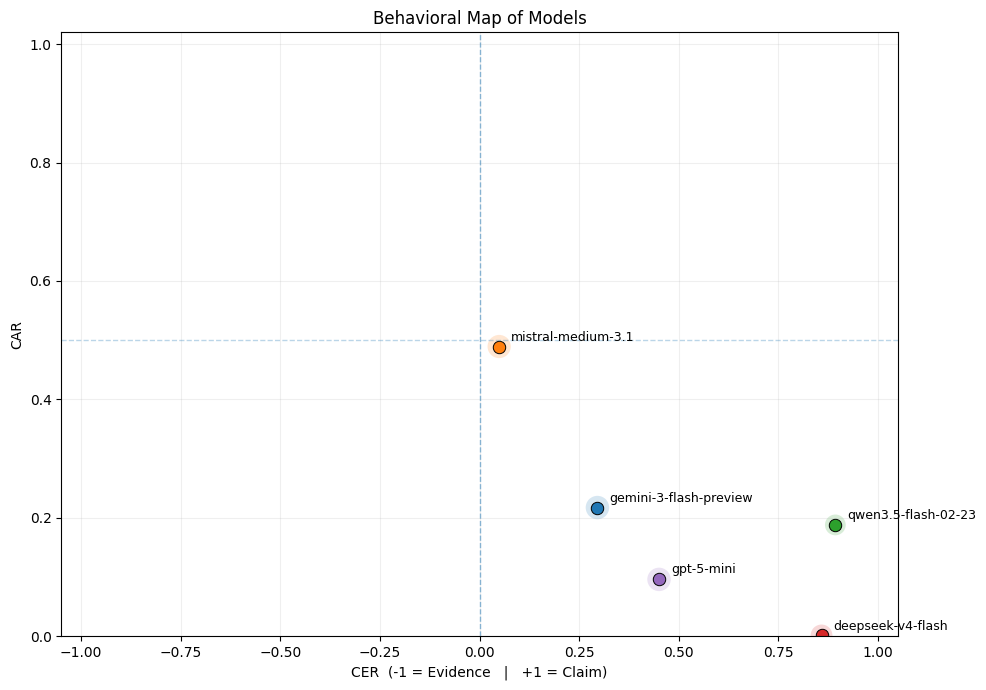

In [312]:
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter


def calculate_cer(classifications):
    """
    CER:
    +1 = all claim
    -1 = all evidence
    0 = balanced
    """
    claim_rate = np.mean([c == "claim" for c in classifications]) if classifications else 0
    evidence_rate = np.mean([c == "evidence" for c in classifications]) if classifications else 0
    return claim_rate - evidence_rate


def compute_model_metrics(samples):
    all_ack = []
    all_cls = []
    sample_consistencies = []

    for sample in samples:
        sample_labels = []

        for it in sample.get("results", []):
            ver = it["verdict"]

            ack = int(it["conflict_acknowledged"])
            cls = ver.lower()

            all_ack.append(ack)
            all_cls.append(cls)
            sample_labels.append(cls)

        # CON per sample
        if sample_labels:
            counts = Counter(sample_labels)
            con = max(counts.values()) / len(sample_labels)
            sample_consistencies.append(con)

    # CAR
    car = np.mean(all_ack) if all_ack else 0

    # CER
    cer = calculate_cer(all_cls)

    # CON
    con = np.mean(sample_consistencies) if sample_consistencies else 0

    return car, cer, con


def plot_behavioral_map(results_dict):
    plt.figure(figsize=(10, 7))

    cmap = plt.cm.tab10
    model_names = list(results_dict.keys())

    colors = {
        model_name: cmap(i % 10)
        for i, model_name in enumerate(model_names)
    }

    for model_name, samples in results_dict.items():

        car, cer, con = compute_model_metrics(samples)

        # instability controls halo
        instability = 1 - con
        halo_size = 200 + instability * 1200

        short_name = model_name.split("/")[-1]
        color = colors[model_name]

        # halo
        plt.scatter(
            cer,
            car,
            s=halo_size,
            color=color,
            alpha=0.18,
            edgecolors="none"
        )

        # center point
        plt.scatter(
            cer,
            car,
            s=80,
            color=color,
            edgecolors="black",
            linewidth=0.7
        )

        # label
        plt.text(
            cer + 0.03,
            car + 0.01,
            short_name,
            fontsize=9
        )

    # reference lines
    plt.axvline(0, linestyle="--", linewidth=1, alpha=0.5)
    plt.axhline(0.5, linestyle="--", linewidth=1, alpha=0.3)

    plt.xlabel("CER  (-1 = Evidence   |   +1 = Claim)")
    plt.ylabel("CAR")
    plt.title("Behavioral Map of Models")

    plt.xlim(-1.05, 1.05)
    plt.ylim(0, 1.02)

    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


plot_behavioral_map(results_baseline)

In [165]:
from collections import defaultdict

def show_diverse_both_per_model(res_baseline, max_per_model=2):

    for model_name, samples in res_baseline.items():

        print("\n" + "=" * 90)
        print(f"MODEL: {model_name.split('/')[-1]}")
        print("=" * 90)

        seen_strategies = set()
        seen_questions = set()
        shown = 0

        for sample in samples:

            if shown >= max_per_model:
                break

            q = sample.get("sample_data", {}).get("question", "")
            if q in seen_questions:
                continue

            strategy = sample.get("metadata", {}).get("strategy")

            true_answers = sample.get("sample_data", {}).get("true_answers", {})
            claim_ans = true_answers.get("Claim")
            evidence_ans = true_answers.get("Evidence")

            results = sample.get("results", [])

            # find a BOTH verdict
            both_item = None
            for it in results:
                if str(it.get("verdict")).lower() == "evidence":
                    both_item = it
                    break

            if not both_item:
                continue

            # enforce strategy diversity (soft constraint)
            if strategy in seen_strategies and len(seen_strategies) < len(samples):
                continue

            print("\n" + "-" * 90)
            print(f"Strategy: {strategy} | Num Evidences: {sample.get('metadata', {}).get('num_evidences')}")
            print(f"Question:\n{q}")

            print(f"\nClaim Answer:\n{claim_ans}")
            print(f"\nEvidence Answer:\n{evidence_ans}")

            print(f"\nModel Output:\n{both_item.get('raw_response')}")

            print("-" * 90)

            seen_questions.add(q)
            seen_strategies.add(strategy)
            shown += 1


show_diverse_both_per_model(res_direct)


MODEL: gemini-3-flash-preview

------------------------------------------------------------------------------------------
Strategy: EXTREME_TEMPORAL | Num Evidences: 7
Question:
Which collected edition title was the first to be released in the Uncanny Avengers series?

Claim Answer:
Uncanny Avengers 2: Apocalypse Twins

Evidence Answer:
Uncanny Avengers 1: Counter-Evolutionary

Model Output:
Based on the provided context, the first collected edition title released in the Uncanny Avengers series was **Uncanny Avengers 1: Counter-Evolutionary**, which is registered to the 2013 calendar year.
------------------------------------------------------------------------------------------

------------------------------------------------------------------------------------------
Strategy: FILTER_COUNT_NUMERICAL | Num Evidences: 8
Question:
How many political parties won more than two seats in Uttar Pradesh during the Lok Sabha elections?

Claim Answer:
7

Evidence Answer:
8

Model Output:
Based

In [147]:
reseses = []
for k, v in res_cot.items():
    for sample in v:
        for it in sample['results']:
            reseses.append((it['conflict_acknowledged'], it['verdict']))

Counter(reseses)

Counter({(False, 'claim'): 324,
         (True, 'claim'): 222,
         (True, 'evidence'): 145,
         (False, 'evidence'): 53,
         (True, 'other answer'): 5,
         (True, 'both'): 1})

In [134]:
import pandas as pd
from collections import Counter

def create_long_format_results_df(technique_data_dict):
    """
    Creates a long-format DataFrame where each model has multiple rows (one per technique).
    Confidence column shows: Majority Strength (Unanimous Certainty)
    """
    rows = []

    # Iterate through each technique
    for tech_name, raw_results in technique_data_dict.items():
        for model_name, samples in raw_results.items():
            all_iterations = []
            unanimous_count = 0
            strengths = []
            
            if not isinstance(samples, list) or len(samples) == 0:
                continue
                
            for sample in samples:
                sample_verdicts = [str(it.get('verdict', 'none')).lower() for it in sample.get('results', [])]
                if not sample_verdicts:
                    continue
                    
                all_iterations.extend(sample_verdicts)
                
                # Metric calculation for this sample
                counts = Counter(sample_verdicts)
                max_votes = counts.most_common(1)[0][1]
                strengths.append(max_votes / len(sample_verdicts))
                
                if len(set(sample_verdicts)) == 1:
                    unanimous_count += 1
            
            # Aggregate Micro Stats
            total_iters = len(all_iterations)
            total_samples = len(samples)
            global_counts = Counter(all_iterations)
            
            c_pct = (global_counts.get('claim', 0) / total_iters) * 100
            b_pct = (global_counts.get('both', 0) / total_iters) * 100
            e_pct = (global_counts.get('evidence', 0) / total_iters) * 100
            
            # Confidence Stats
            mean_strength = (sum(strengths) / total_samples) * 100
            unan_certainty = (unanimous_count / total_samples) * 100

            rows.append({
                "Model": model_name,
                "Technic": tech_name,
                "Both%": f"{b_pct:.1f}%",
                "Claim%": f"{c_pct:.1f}%",
                "Evidence%": f"{e_pct:.1f}%",
                "Confidence": f"{mean_strength:.1f}% ({unan_certainty:.1f}%)"
            })

    # Create DataFrame
    df = pd.DataFrame(rows)
    
    # Sort by Model then Technic to ensure grouping
    df = df.sort_values(["Model", "Technic"])
    
    # Optional: Set multi-index to visually group the Model column like your screenshot
    df.set_index(["Model", "Technic"], inplace=True)
    
    return df

# --- Execution ---
tech_comparison = {"Baseline": res_direct, "Selection": res_cot, "Reconstruction": res_evidence_cot}
df = create_long_format_results_df(tech_comparison)
display(df)

Both% Claim% Evidence%  \
Model                         Technic                                  
google/gemini-3-flash-preview Baseline        18.8%  52.4%     27.6%   
                              Reconstruction   0.4%  85.2%     13.2%   
                              Selection        0.4%  82.0%     17.6%   
mistralai/mistral-medium-3.1  Baseline         5.6%  42.8%     44.4%   
                              Reconstruction   0.0%  68.8%     29.2%   
                              Selection        0.0%  70.0%     28.0%   
openai/gpt-5-mini             Baseline        11.6%  64.0%     23.6%   
                              Reconstruction   0.0%  64.0%     33.6%   
                              Selection        0.0%  66.4%     33.6%   

                                                 Confidence  
Model                         Technic                        
google/gemini-3-flash-preview Baseline        90.8% (76.0%)  
                              Reconstruction  95.2% (84.0%)  
                              Selection       96.4% (86.0%)  
mistralai/mistral-medium-3.1  Baseline        91.6% (76.0%)  
                              Reconstruction  92.4% (74.0%)  
                              Selection       92.4% (68.0%)  
openai/gpt-5-mini             Baseline        85.2% (58.0%)  
                              Reconstruction  91.6% (70.0%)  
                              Selection       93.6% (76.0%)

In [137]:
import pandas as pd
from collections import Counter

def calculate_drift(c_count, b_count, e_count):
    """(2*B + C) / (2*B + C + E)"""
    numerator = c_count
    denominator = c_count + e_count
    return numerator / denominator if denominator > 0 else 0

def create_inverted_nested_df(technique_data_dict):
    """
    Creates a DataFrame with inverted nested columns:
    Level 0: Metric (PC %, Drift)
    Level 1: Technique (Direct, Conflict, CoT)
    """
    final_data = {}

    for tech_name, raw_results in technique_data_dict.items():
        for model_name, samples in raw_results.items():
            model_short_name = model_name.split('/')[-1]
            # Flatten all iterations
            all_verdicts = [
                str(it.get('verdict', 'none')).lower() 
                for s in samples 
                for it in s.get('results', [])
            ]
            
            if not all_verdicts:
                continue
            
            counts = Counter(all_verdicts)
            total = len(all_verdicts)
            
            # Metrics
            pc_both = (counts.get('both', 0) / total) * 100
            drift = calculate_drift(
                counts.get('claim', 0), 
                counts.get('both', 0), 
                counts.get('evidence', 0)
            )
            
            if model_short_name not in final_data:
                final_data[model_short_name] = {}
            
            # Inverted Level: Metric first, then Technique
            final_data[model_short_name][("Plurality Score", tech_name)] = f"{pc_both:.1f}%"
            final_data[model_short_name][("Directional Bias", tech_name)] = f"{drift:.2f}"

    # Build DataFrame
    df = pd.DataFrame.from_dict(final_data, orient='index')
    
    # Create MultiIndex
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    
    # Sort Level 0 (Metrics) then Level 1 (Techniques) to keep it organized
    # This ensures all PC columns come first, followed by all Drift columns
    df = df.sort_index(axis=1, level=[0, 1], ascending=[False, True])
    
    return df
    
# --- Usage ---
df = create_inverted_nested_df(tech_comparison)
display(df)

Plurality Score                           \
                              Baseline Reconstruction Selection   
gemini-3-flash-preview           18.8%           0.4%      0.4%   
mistral-medium-3.1                5.6%           0.0%      0.0%   
gpt-5-mini                       11.6%           0.0%      0.0%   

                       Directional Bias                           
                               Baseline Reconstruction Selection  
gemini-3-flash-preview             0.66           0.87      0.82  
mistral-medium-3.1                 0.49           0.70      0.71  
gpt-5-mini                         0.73           0.66      0.66

In [104]:
import pandas as pd
import numpy as np
from collections import Counter

def calculate_drift(c_count, b_count, e_count):
    numerator = c_count
    denominator = c_count + e_count
    return numerator / denominator if denominator > 0 else 0


def create_strategy_level_df_with_std(technique_data_dict):
    """
    Aggregates metrics by STRATEGY and computes:
    - Plurality mean + std
    - Directional bias mean + std
    """

    strategy_data = {}

    for technique_name, raw_results in technique_data_dict.items():
        for model_name, samples in raw_results.items():

            for sample in samples:

                strategy = sample.get("metadata", {}).get("strategy", "UNKNOWN")

                verdicts = [
                    str(it.get("verdict", "none")).lower()
                    for it in sample.get("results", [])
                ]

                if not verdicts:
                    continue

                counts = Counter(verdicts)
                total = len(verdicts)

                pc_both = (counts.get("both", 0) / total) * 100

                drift = calculate_drift(
                    counts.get("claim", 0),
                    counts.get("both", 0),
                    counts.get("evidence", 0)
                )

                if strategy not in strategy_data:
                    strategy_data[strategy] = {
                        "plurality": [],
                        "drift": []
                    }

                strategy_data[strategy]["plurality"].append(pc_both)
                strategy_data[strategy]["drift"].append(drift)

    # Build final table
    rows = {}

    for strategy, vals in strategy_data.items():

        plurality = np.array(vals["plurality"])
        drift = np.array(vals["drift"])

        rows[strategy] = {
            ("Plurality Score", "mean"): np.mean(plurality) if len(plurality) else 0,
            ("Plurality Score", "std"): np.std(plurality) if len(plurality) else 0,

            ("Directional Bias", "mean"): np.mean(drift) if len(drift) else 0,
            ("Directional Bias", "std"): np.std(drift) if len(drift) else 0,
        }

    df = pd.DataFrame(rows).T

    # clean formatting
    df = df.round(3)

    df.columns = pd.MultiIndex.from_tuples(df.columns)

    return df


# --- Usage ---
df_strategy = create_strategy_level_df_with_std(tech_comparison)
display(df_strategy)

Plurality Score         Directional Bias       
                                     mean     std             mean    std
TOP_K_RANKING                       0.000   0.000            0.284  0.404
COMPARATIVE_DIFFERENCE              2.500   9.306            0.654  0.353
EXTREME_NUMERICAL                   0.263   2.279            0.218  0.348
UNIQUE_DIVERSITY                    2.667  13.888            0.787  0.377
FREQUENCY_MODE                      2.778  11.208            0.591  0.434
EXTREME_TEMPORAL                    1.000   5.686            0.543  0.445
FILTER_COUNT_TEMPORAL               1.333   6.182            0.771  0.399
AGGREGATION                         2.000   6.000            0.930  0.217
COUNT_TOTAL                         1.111   4.581            0.983  0.073
CATEGORICAL_FILTER_LOOKUP           4.091  18.868            0.821  0.334
FILTER_COUNT_NUMERICAL              0.000   0.000            0.695  0.393

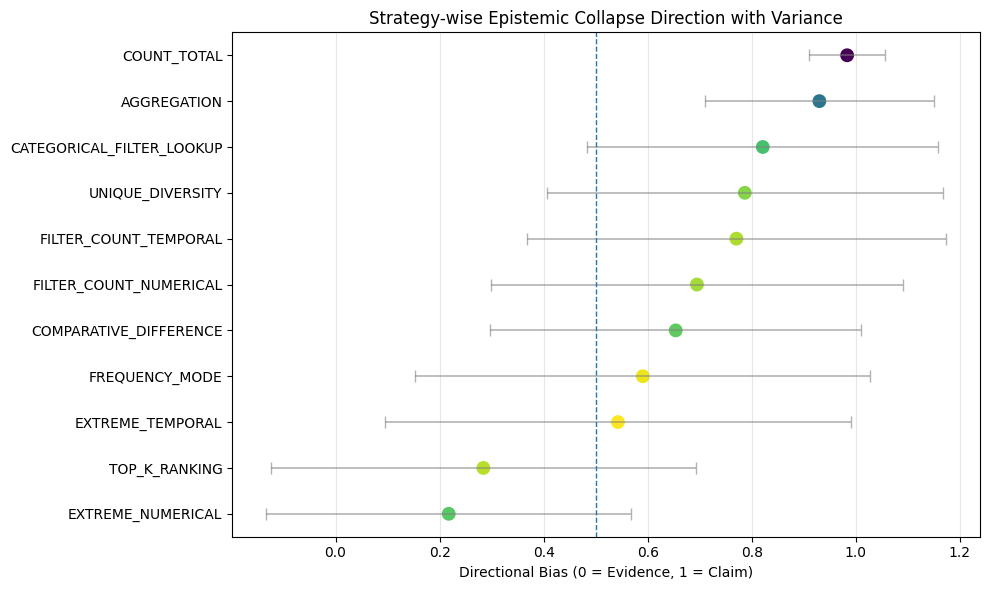

In [126]:
import matplotlib.pyplot as plt
import numpy as np

def plot_strategy_drift(summary):

    summary = summary.sort_values("Drift_Mean")

    strategies = summary["Strategy"].values
    means = summary["Drift_Mean"].values
    stds = summary["Drift_Std"].values

    y_pos = np.arange(len(strategies))

    plt.figure(figsize=(10, 6))

    # normalize std for coloring
    norm = plt.Normalize(stds.min(), stds.max())
    colors = plt.cm.viridis(norm(stds))

    # scatter (colored by std)
    plt.scatter(means, y_pos, color=colors, s=80)

    # error bars (no color mapping here)
    plt.errorbar(
        means,
        y_pos,
        xerr=stds,
        fmt='none',
        ecolor='gray',
        alpha=0.6,
        capsize=4,
        linewidth=1.2
    )

    # reference line
    plt.axvline(0.5, linestyle="--", linewidth=1)

    plt.yticks(y_pos, strategies)
    plt.xlabel("Directional Bias (0 = Evidence, 1 = Claim)")
    plt.title("Strategy-wise Epistemic Collapse Direction with Variance")

    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

df, summary = aggregate_by_strategy(tech_comparison)

summary = df.groupby("Strategy").agg(
    PC_Mean=("PC", "mean"),
    PC_Std=("PC", "std"),
    Drift_Mean=("Drift", "mean"),
    Drift_Std=("Drift", "std"),
).reset_index()

plot_strategy_drift(summary)

In [260]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

model_evaluation_results = {}

eval_models = [
    "google/gemini-3-flash-preview",
    # "google/gemini-3.1-flash-lite-preview",
    "x-ai/grok-4.1-fast",
    # "openai/gpt-5.4-mini",
    # "qwen/qwen3.5-flash-02-23",
    "mistralai/mistral-medium-3.1",
    # "anthropic/claude-haiku-4.5",
    # "z-ai/glm-4.7-flash",
    # "moonshotai/kimi-k2.5",
    "deepseek/deepseek-v4-flash",
]

for model in eval_models:
    
    # Initialize the class, passing in the desired model
    evaluator = KnowledgeMazeEvaluator(
        repo_path=REPO_PATH, 
        model_name=model,
    )

    # Run the async pipeline
    results = await evaluator.run_evaluation()

    # Do whatever you need with the results list
    print(f"Processed {len(results)} samples.")

    model_evaluation_results[model] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running target inference with model: google/gemini-3-flash-preview...


Generating Answers:   0%|          | 0/141 [00:00<?, ?it/s]

Evaluating answers using KnowledgeConflictJudge...


Judging Outputs:   0%|          | 0/141 [00:00<?, ?it/s]

Model answer: Based on the provided context, Cyndi Lauper achieved a total of **5** distinct types of placement results across the various Cashbox Awards categories. These specific rankings and achievement tiers include:

1.  **3rd place** (achieved in categories such as Pop Singles Awards: Top Female Vocalist and Pop Album Awards: Top Female Vocalist).
2.  **Won** (achieved in categories such as Black Contemporary Singles: Top Pop Crossover Vocalist and 12" Singles: Top Female Vocalist).
Options: {'Memory': '3', 'Claim': '5', 'Evidence': '2'}
Judge verdict: claim

------

Model answer: Based on the provided context, the most common category among Netflix original special films released in 2020 was **Making-of**.
Options: {'Memory': 'Concert film', 'Claim': 'Making-of', 'Evidence': 'Variety show'}
Judge verdict: claim

------

Model answer: Based on the provided context, there is a contradiction between two sections regarding the number of national parties for Luxembourg (1994–1999):



...

Model answer: Cyndi Lauper achieved **two different types of placement results** across the various Cashbox Awards categories:

1. **"Won"** (e.g., *Black Contemporary Singles: Top Pop Crossover Vocalist*, *12" Singles: Top Female Vocalist*, *Music Video & Videocassette Awards: Top Female Vocalist*).
2. **"3rd place"** (e.g., *Pop Singles Awards: Top Female Vocalist*, *Pop Album Awards: Top New Female Vocalist*, etc.).
Options: {'Memory': '3', 'Claim': '5', 'Evidence': '2'}
Judge verdict: evidence

------

Model answer: Based solely on the provided context, the **most common genre** among the **Netflix original special films released in 2020** was **"Making-of."**

The context explicitly states:
*"the classification of Making-of constitutes the most frequent category found among the various creative offerings"* in Netflix's 2020 original special films. The example given is *Road to Roma*, which is categorized as a Making-of production. No other genre appears more frequently in the prov

Generating Answers:   0%|          | 0/141 [00:00<?, ?it/s]

Evaluating answers using KnowledgeConflictJudge...


Judging Outputs:   0%|          | 0/141 [00:00<?, ?it/s]

Model answer: 2
Options: {'Memory': '3', 'Claim': '5', 'Evidence': '2'}
Judge verdict: evidence

------

Model answer: Making-of
Options: {'Memory': 'Concert film', 'Claim': 'Making-of', 'Evidence': 'Variety show'}
Judge verdict: claim

------

Model answer: 1
Options: {'Memory': '4', 'Claim': '1', 'Evidence': '3'}
Judge verdict: claim

------

Model answer: 3
Options: {'Memory': '6', 'Claim': '3', 'Evidence': '4'}
Judge verdict: claim

------

Model answer: Paolo Corsini
Options: {'Memory': 'Bruno Boni', 'Claim': 'Paolo Corsini', 'Evidence': 'Guglielmo Ghislandi'}
Judge verdict: claim

------

Model answer: 5
Options: {'Memory': '7', 'Claim': '5', 'Evidence': '4'}
Judge verdict: claim

------

Model answer: 2
Options: {'Memory': '3', 'Claim': '2', 'Evidence': '4'}
Judge verdict: claim

------

Model answer: 11
Options: {'Memory': 8, 'Claim': 11, 'Evidence': 7}
Judge verdict: claim

------

Model answer: 6
Options: {'Memory': '4', 'Claim': '6', 'Evidence': '5'}
Judge verdict: claim

--

In [272]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

model_evaluation_results_conflict = {}

eval_models = [
    "google/gemini-3-flash-preview",
    # "google/gemini-3.1-flash-lite-preview",
    "x-ai/grok-4.1-fast",
    # "openai/gpt-5.4-mini",
    # "qwen/qwen3.5-flash-02-23",
    "mistralai/mistral-medium-3.1",
    # "anthropic/claude-haiku-4.5",
    # "z-ai/glm-4.7-flash",
    # "moonshotai/kimi-k2.5",
    "deepseek/deepseek-v4-flash",
]

for model in eval_models:
    
    # Initialize the class, passing in the desired model
    evaluator = KnowledgeMazeEvaluator(
        repo_path=REPO_PATH, 
        model_name=model,
        prompt_type='conflict'
    )

    # Run the async pipeline
    results = await evaluator.run_evaluation()

    # Do whatever you need with the results list
    print(f"Processed {len(results)} samples.")

    model_evaluation_results_conflict[model] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running target inference with model: google/gemini-3-flash-preview...


Generating Answers:   0%|          | 0/141 [00:00<?, ?it/s]

Evaluating answers using KnowledgeConflictJudge...


Judging Outputs:   0%|          | 0/141 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 141 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running target inference with model: x-ai/grok-4.1-fast...


...

Calculating reliance statistics...
Evaluation complete.
Processed 141 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running target inference with model: deepseek/deepseek-v4-flash...


Generating Answers:   0%|          | 0/141 [00:00<?, ?it/s]

Evaluating answers using KnowledgeConflictJudge...


Judging Outputs:   0%|          | 0/141 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 141 samples.


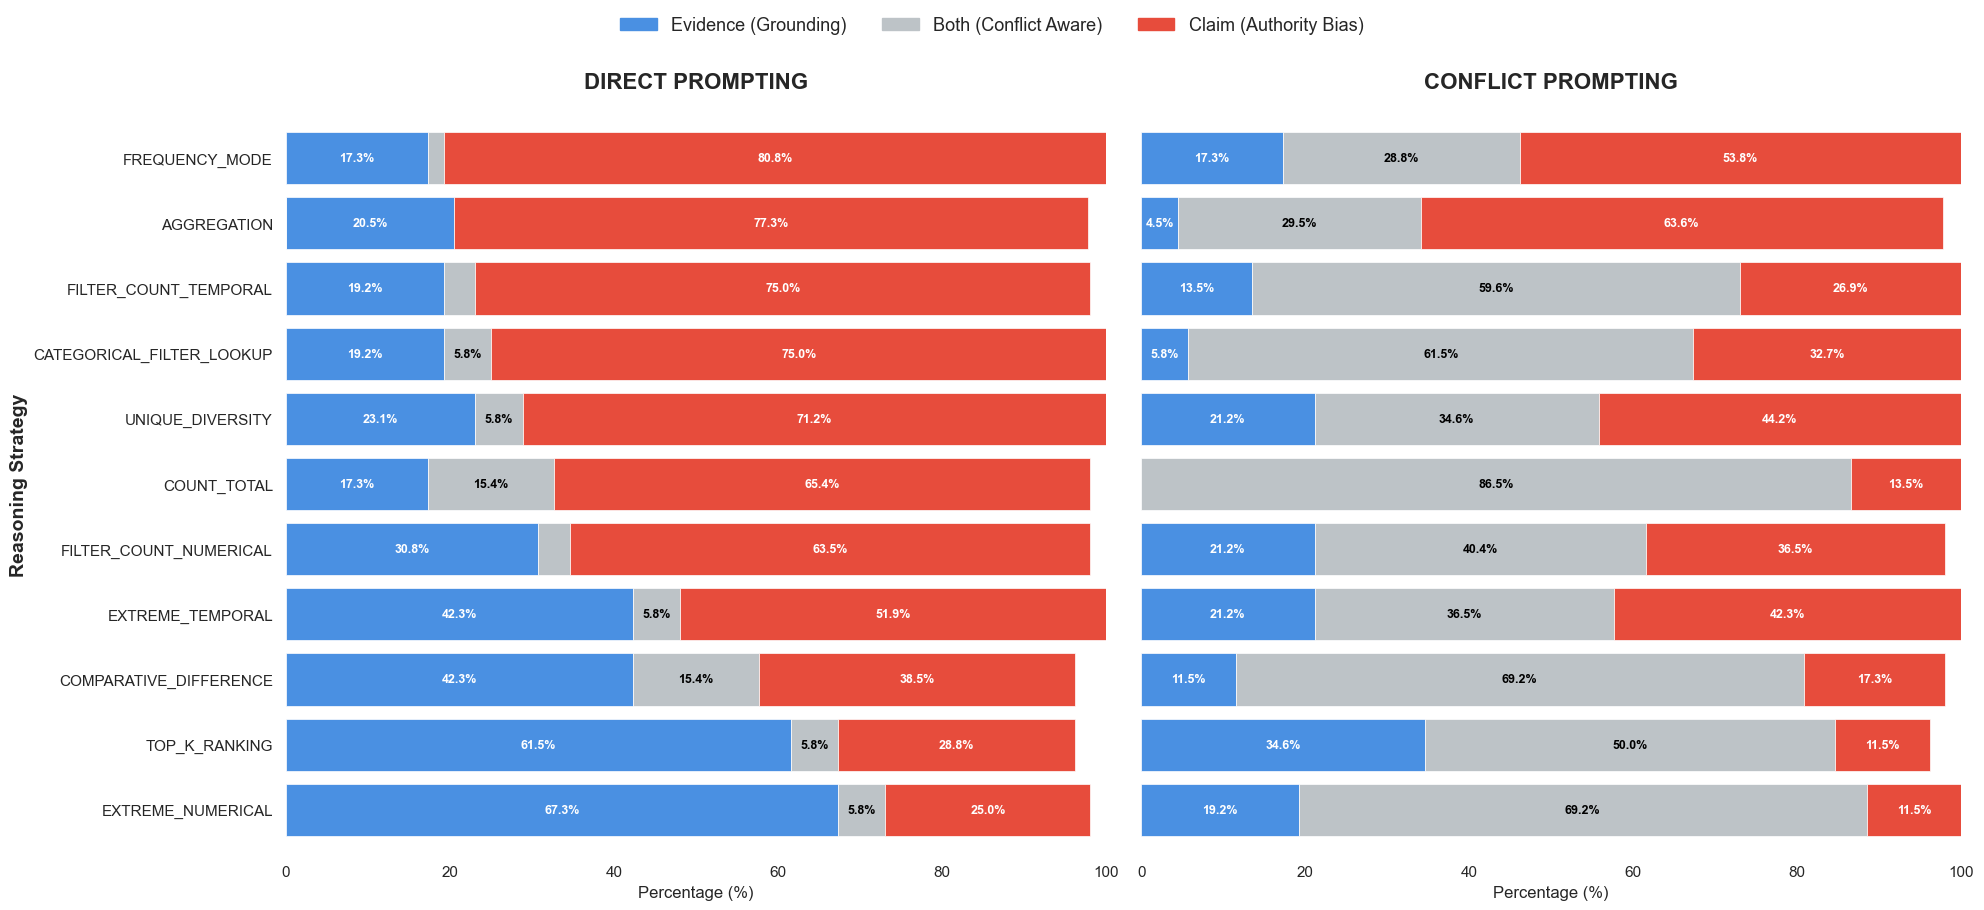

In [303]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_dual_benchmark(direct_dict, conflict_dict):
    # 1. Helper to flatten dicts
    def flatten(d):
        recs = []
        for model, results in d.items():
            for r in results:
                recs.append({'Strategy': r['Strategy'], 'Answer': r['Answer']})
        return pd.DataFrame(recs)

    df_d = flatten(direct_dict)
    df_c = flatten(conflict_dict)

    # 2. Config
    ans_order = ['Evidence', 'Both', 'Claim']
    palette = {'Evidence': '#4A90E2', 'Both': '#BDC3C7', 'Claim': '#E74C3C'}
    
    # 3. Process Both Datasets
    def get_ct(df):
        ct = pd.crosstab(df['Strategy'], df['Answer'])
        ct = ct.div(ct.sum(axis=1), axis=0) * 100
        for col in ans_order:
            if col not in ct.columns: ct[col] = 0
        return ct

    ct_d = get_ct(df_d)
    ct_c = get_ct(df_c)

    # 4. ALIGNMENT: Define a global strategy order (e.g., based on Direct Claim rate)
    strategy_order = ct_d['Claim'].sort_values(ascending=True).index
    ct_d = ct_d.reindex(index=strategy_order, columns=ans_order)
    ct_c = ct_c.reindex(index=strategy_order, columns=ans_order)

    # 5. Plotting (1 Row, 2 Columns)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9), sharey=True)

    def draw_bars(ax, ct, title):
        ct.plot(kind='barh', stacked=True, ax=ax, color=[palette[c] for c in ans_order], 
                width=0.8, edgecolor='white', linewidth=0.5, legend=False)
        ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
        ax.set_xlim(0, 100)
        ax.set_xlabel("Percentage (%)", fontsize=12)
        
        # Labels
        for i, (name, row) in enumerate(ct.iterrows()):
            cum_x = 0
            for col in ans_order:
                val = row[col]
                if val > 4:
                    txt_c = 'black' if col == 'Both' else 'white'
                    ax.text(cum_x + (val/2), i, f"{val:.1f}%", va='center', ha='center', 
                            color=txt_c, fontweight='bold', fontsize=9)
                cum_x += val

    draw_bars(ax1, ct_d, "DIRECT PROMPTING")
    draw_bars(ax2, ct_c, "CONFLICT PROMPTING")

    # 6. Aesthetics
    ax1.set_ylabel("Reasoning Strategy", fontsize=14, fontweight='bold')
    ax2.set_ylabel("") # Hide middle Y-axis label
    
    legend_labels = ['Evidence (Grounding)', 'Both (Conflict Aware)', 'Claim (Authority Bias)']
    handles = [plt.Rectangle((0,0),1,1, color=palette[c]) for c in ans_order]
    fig.legend(handles, legend_labels, loc='upper center', bbox_to_anchor=(0.5, 1.02), 
               ncol=3, frameon=False, fontsize=13)

    sns.despine(left=True, bottom=True)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Call the function
plot_dual_benchmark(model_evaluation_results, model_evaluation_results_conflict)

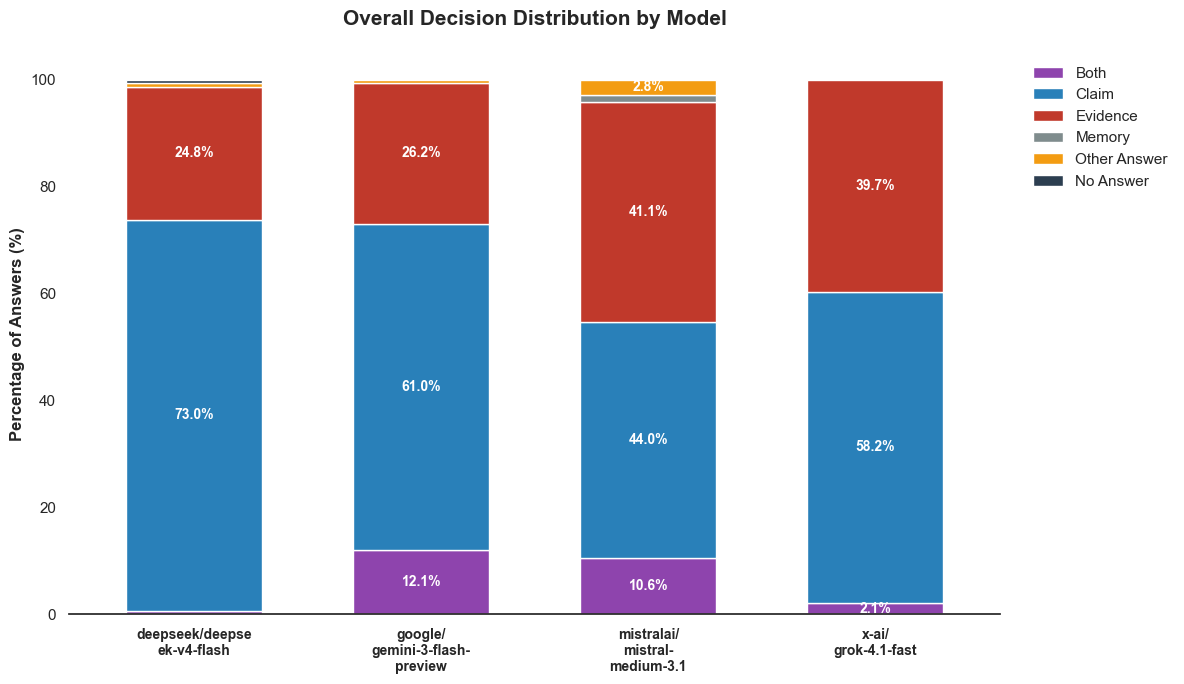

In [288]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeVisualizer(model_evaluation_results)
viz.plot_overall_distribution()

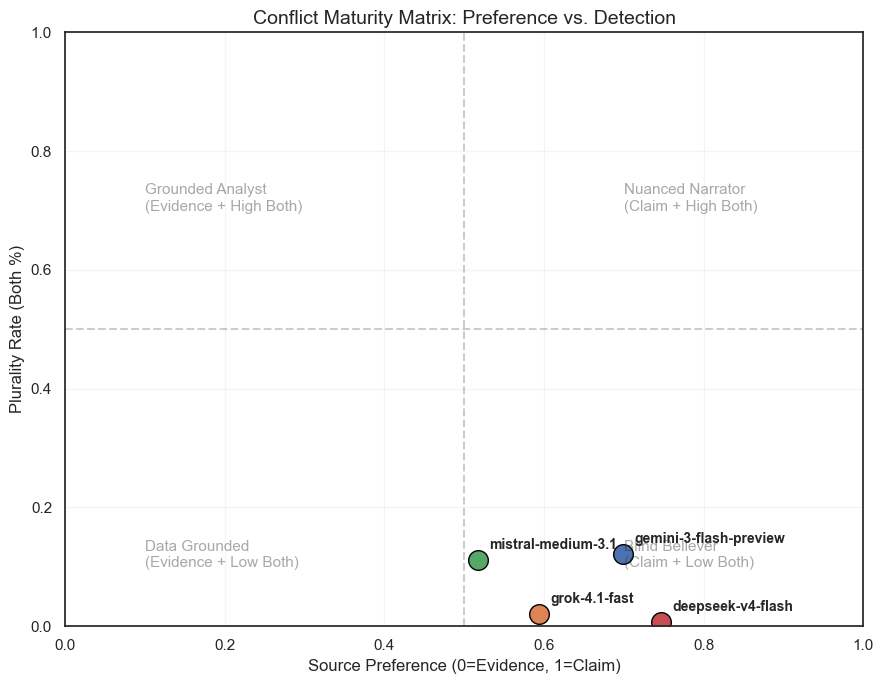

In [279]:
import matplotlib.pyplot as plt

def calculate_coordinates(results):
    c = sum(1 for r in results if r['Answer'] == 'Claim')
    e = sum(1 for r in results if r['Answer'] == 'Evidence')
    b = sum(1 for r in results if r['Answer'] == 'Both')
    
    total = c + e + b
    # Y-axis: Plurality Rate
    y = b / total if total > 0 else 0
    # X-axis: Normalized Claim Rate (Preference when not choosing 'Both')
    x = c / (c + e) if (c + e) > 0 else 0.5
    return x, y

# Processing the models
plt.figure(figsize=(9, 7))

for model_path, results in model_evaluation_results.items():
    name = model_path.split('/')[-1]
    x, y = calculate_coordinates(results)
    
    plt.scatter(x, y, s=200, edgecolors='black', label=name)
    plt.annotate(name, (x, y), xytext=(8, 8), textcoords='offset points', fontsize=10, fontweight='bold')

# Formatting the Matrix
plt.axvline(0.5, color='black', alpha=0.2, linestyle='--') # Neutral Line
plt.axhline(0.5, color='black', alpha=0.2, linestyle='--') # High Plurality Threshold

# Quadrant Descriptions
plt.text(0.1, 0.7, "Grounded Analyst\n(Evidence + High Both)", fontsize=11, alpha=0.4)
plt.text(0.7, 0.7, "Nuanced Narrator\n(Claim + High Both)", fontsize=11, alpha=0.4)
plt.text(0.1, 0.1, "Data Grounded\n(Evidence + Low Both)", fontsize=11, alpha=0.4)
plt.text(0.7, 0.1, "Blind Believer\n(Claim + Low Both)", fontsize=11, alpha=0.4)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("Source Preference (0=Evidence, 1=Claim)", fontsize=12)
plt.ylabel("Plurality Rate (Both %)", fontsize=12)
plt.title("Conflict Maturity Matrix: Preference vs. Detection", fontsize=14)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('conflict_maturity_matrix.png')

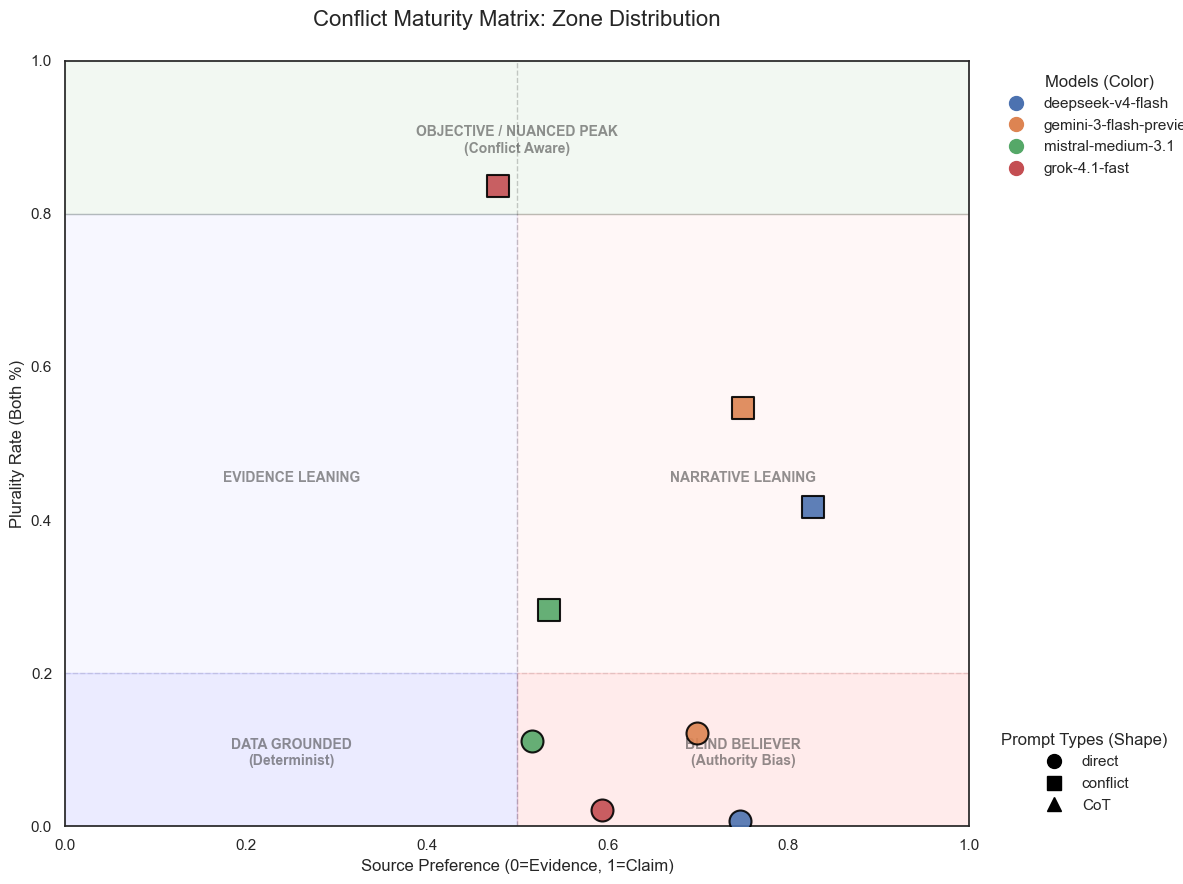

In [287]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

def plot_refined_maturity_matrix(results_dict, save_path='conflict_maturity_matrix.png'):
    """
    results_dict format: 
    { 
      "google/gemini-3-flash": { "direct": [...], "conflict": [...], "CoT": [...] },
      "x-ai/grok-4.1-fast": { "direct": [...], "conflict": [...], "CoT": [...] }
    }
    """
    plt.figure(figsize=(11, 8))
    
    # 1. Explicit Shape Mapping per Prompt Type
    prompt_marker_map = {
        'direct': 'o',    # Circle
        'conflict': 's',  # Square
        'CoT': '^'        # Triangle
    }
    
    # Fallback for any unexpected prompt types
    fallback_markers = ['D', 'v', 'P', '*', 'X'] 
    
    # 2. Color Mapping per Model
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    all_models = list(results_dict.keys())
    all_prompts = sorted(list(set(p for m in results_dict.values() for p in m.keys())))
    
    model_color_map = {model: colors[i % len(colors)] for i, model in enumerate(all_models)}
    
    # Ensure any extra prompts get a marker just in case
    marker_idx = 0
    for p in all_prompts:
        if p not in prompt_marker_map:
            prompt_marker_map[p] = fallback_markers[marker_idx % len(fallback_markers)]
            marker_idx += 1

    def calculate_coords(results):
        c = sum(1 for r in results if r['Answer'] == 'Claim')
        e = sum(1 for r in results if r['Answer'] == 'Evidence')
        b = sum(1 for r in results if r['Answer'] == 'Both')
        total = c + e + b
        y = b / total if total > 0 else 0
        x = c / (c + e) if (c + e) > 0 else 0.5
        return x, y

    # Plotting loop
    for model_path, prompt_data in results_dict.items():
        for prompt_type, results in prompt_data.items():
            x, y = calculate_coords(results)
            
            plt.scatter(
                x, y, 
                s=200, 
                c=[model_color_map[model_path]], 
                marker=prompt_marker_map[prompt_type],
                edgecolors='black', 
                linewidth=1,
                alpha=0.85,
                zorder=3
            )

    # --- Matrix Decoration ---
    plt.axvline(0.5, color='black', alpha=0.15, linestyle='--')
    plt.axhline(0.5, color='black', alpha=0.15, linestyle='--')
    
    text_cfg = {'fontsize': 10, 'alpha': 0.4, 'ha': 'center', 'fontweight': 'bold'}
    plt.text(0.25, 0.95, "GROUNDED ANALYST", **text_cfg)
    plt.text(0.75, 0.95, "NUANCED NARRATOR", **text_cfg)
    plt.text(0.25, 0.05, "DATA DRIVEN", **text_cfg)
    plt.text(0.75, 0.05, "BLIND BELIEVER", **text_cfg)

    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("Source Preference (0=Evidence, 1=Claim)", fontsize=11)
    plt.ylabel("Plurality Rate (Both %)", fontsize=11)
    plt.title("Model Maturity vs. Prompt Influence", fontsize=14, pad=20)
    plt.grid(alpha=0.1)

    # --- Dual Legends ---
    # Legend 1: Models (Colors)
    model_handles = [mlines.Line2D([], [], color=model_color_map[m], marker='o', linestyle='None',
                                    markersize=10, label=m.split('/')[-1]) for m in all_models]
    leg1 = plt.legend(handles=model_handles, title="Models (Color)", loc='upper left', 
                      bbox_to_anchor=(1.02, 1), frameon=False)
    
    # Legend 2: Prompts (Shapes) 
    prompt_handles = [mlines.Line2D([], [], color='black', marker=prompt_marker_map[p], linestyle='None',
                                     markersize=10, label=p) for p in all_prompts]
    leg2 = plt.legend(handles=prompt_handles, title="Prompt Types (Shape)", loc='lower left', 
                      bbox_to_anchor=(1.02, 0), frameon=False)
    
    plt.gca().add_artist(leg1) 

    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

# 1. Create a new empty dictionary in the right format
reformatted_results = {}

# 2. Get all unique model names from both of your variables
all_models = set(model_evaluation_results.keys()).union(model_evaluation_results_conflict.keys())

# 3. Flip the hierarchy: Model -> Prompt -> Results
for model in all_models:
    reformatted_results[model] = {}
    
    # Add the direct results if they exist for this model
    if model in model_evaluation_results:
        reformatted_results[model]['direct'] = model_evaluation_results[model]
        
    # Add the conflict results if they exist for this model
    if model in model_evaluation_results_conflict:
        reformatted_results[model]['conflict'] = model_evaluation_results_conflict[model]

# 4. NOW call the function with the reformatted dictionary!
plot_5zone_maturity_matrix(reformatted_results)

In [286]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np

def plot_5zone_maturity_matrix(results_dict, save_path='conflict_maturity_matrix_5zone.png'):
    plt.figure(figsize=(12, 9))
    ax = plt.gca()
    
    # 1. Config: Shapes and Colors
    prompt_marker_map = {'direct': 'o', 'conflict': 's', 'CoT': '^'}
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    all_models = list(results_dict.keys())
    model_color_map = {model: colors[i % len(colors)] for i, model in enumerate(all_models)}

    # 2. Background Zones (The "5 Sections")
    # Zone 1: Objective Tier (The unified top)
    ax.axhspan(0.8, 1.0, color='green', alpha=0.05, label='Objective Tier')
    
    # Zones 2 & 3: The Leaning Tiers (Middle)
    ax.add_patch(plt.Rectangle((0, 0.2), 0.5, 0.6, color='blue', alpha=0.03))  # Evidence Leaning
    ax.add_patch(plt.Rectangle((0.5, 0.2), 0.5, 0.6, color='red', alpha=0.03)) # Narrative Leaning
    
    # Zones 4 & 5: The Stubborn Tiers (Bottom)
    ax.add_patch(plt.Rectangle((0, 0), 0.5, 0.2, color='blue', alpha=0.08))    # Data Grounded
    ax.add_patch(plt.Rectangle((0.5, 0), 0.5, 0.2, color='red', alpha=0.08))   # Blind Believer

    # 3. Text Labels for Zones
    label_style = {'fontsize': 10, 'fontweight': 'bold', 'ha': 'center', 'alpha': 0.5}
    plt.text(0.5, 0.88, "OBJECTIVE / NUANCED PEAK\n(Conflict Aware)", **label_style)
    plt.text(0.25, 0.45, "EVIDENCE LEANING", **label_style)
    plt.text(0.75, 0.45, "NARRATIVE LEANING", **label_style)
    plt.text(0.25, 0.08, "DATA GROUNDED\n(Determinist)", **label_style)
    plt.text(0.75, 0.08, "BLIND BELIEVER\n(Authority Bias)", **label_style)

    def calculate_coords(results):
        c = sum(1 for r in results if r['Answer'] == 'Claim')
        e = sum(1 for r in results if r['Answer'] == 'Evidence')
        b = sum(1 for r in results if r['Answer'] == 'Both')
        total = c + e + b
        y = b / total if total > 0 else 0
        x = c / (c + e) if (c + e) > 0 else 0.5
        return x, y

    # 4. Plotting
    for model_path, prompt_data in results_dict.items():
        for prompt_type, results in prompt_data.items():
            if prompt_type not in prompt_marker_map: continue
            x, y = calculate_coords(results)
            
            plt.scatter(
                x, y, s=250, 
                c=[model_color_map[model_path]], 
                marker=prompt_marker_map[prompt_type],
                edgecolors='black', linewidth=1.5, alpha=0.9, zorder=5
            )

    # 5. Formatting
    plt.axvline(0.5, color='black', alpha=0.2, linestyle='--', lw=1)
    plt.axhline(0.8, color='black', alpha=0.2, linestyle='-', lw=1) # Threshold for Objective
    plt.axhline(0.2, color='black', alpha=0.1, linestyle='--', lw=1) # Threshold for Stubborn
    
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("Source Preference (0=Evidence, 1=Claim)", fontsize=12)
    plt.ylabel("Plurality Rate (Both %)", fontsize=12)
    plt.title("Conflict Maturity Matrix: Zone Distribution", fontsize=16, pad=25)

    # 6. Separate Legends
    model_handles = [mlines.Line2D([], [], color=model_color_map[m], marker='o', 
                                   linestyle='None', markersize=10, label=m.split('/')[-1]) for m in all_models]
    leg1 = plt.legend(handles=model_handles, title="Models (Color)", loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
    
    prompt_handles = [mlines.Line2D([], [], color='black', marker=prompt_marker_map[p], 
                                    linestyle='None', markersize=10, label=p) for p in ['direct', 'conflict', 'CoT']]
    leg2 = plt.legend(handles=prompt_handles, title="Prompt Types (Shape)", loc='lower left', bbox_to_anchor=(1.02, 0), frameon=False)
    
    plt.gca().add_artist(leg1)
    plt.tight_layout()
    plt.savefig(save_path, bbox_inches='tight')
    plt.show()

'scaling_analysis.png'

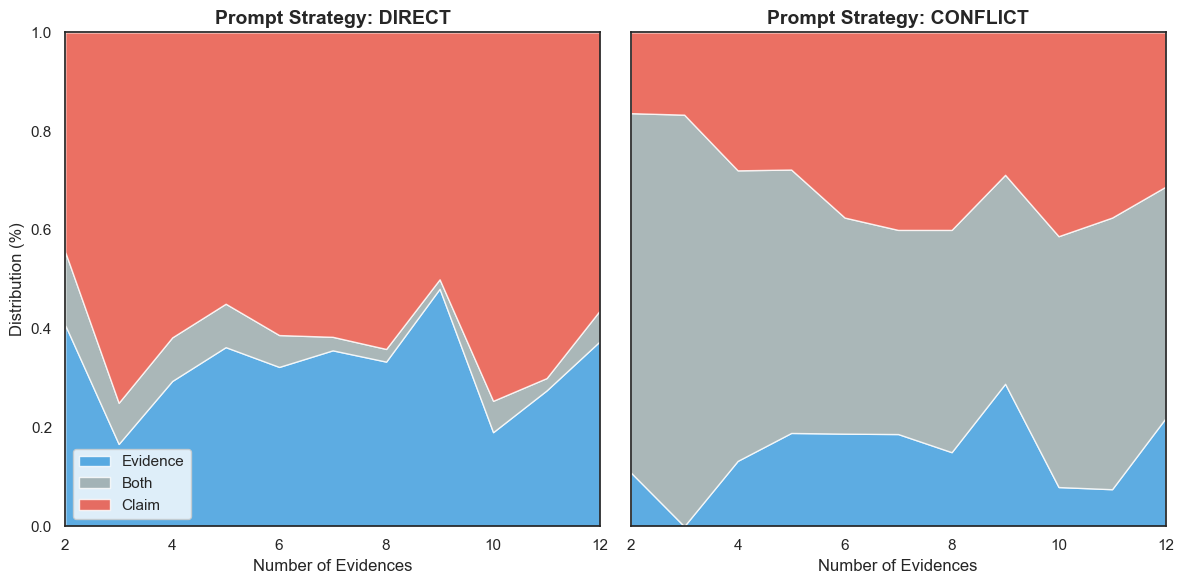

In [310]:
import pandas as pd
import matplotlib.pyplot as plt

def parse_and_plot_scaling(res_dict, output_name="scaling_analysis.png"):
    # 1. Flatten the nested dictionary into a DataFrame
    rows = []
    for model, prompts in res_dict.items():
        for prompt_type, results in prompts.items():
            for res in results:
                rows.append({
                    'prompt_type': prompt_type,
                    'answer': res.get('Answer', 'Unknown').capitalize(),
                    'num_evidence': res.get('Num_evidence')
                })
    df = pd.DataFrame(rows)
    
    # 2. Setup the Plot (Faceted by Prompt Type)
    prompts = df['prompt_type'].unique()
    fig, axes = plt.subplots(1, len(prompts), figsize=(6 * len(prompts), 6), sharey=True)
    if len(prompts) == 1: axes = [axes]
    
    # Standardized color scheme
    colors = {'Evidence': '#3498db', 'Both': '#95a5a6', 'Claim': '#e74c3c'}
    order = ['Evidence', 'Both', 'Claim']
    
    for ax, prompt in zip(axes, prompts):
        subset = df[df['prompt_type'] == prompt]
        
        # Aggregate counts and normalize to 100%
        counts = subset.pivot_table(index='num_evidence', columns='answer', 
                                    aggfunc='size', fill_value=0)
        
        # Ensure all columns exist for stacking
        for col in order:
            if col not in counts.columns: counts[col] = 0
        counts = counts[order]
        
        # Normalize rows to sum to 1.0
        percentages = counts.div(counts.sum(axis=1), axis=0)
        
        # Plotting the Stacked Area
        ax.stackplot(percentages.index, 
                     percentages['Evidence'], percentages['Both'], percentages['Claim'],
                     labels=order, colors=[colors[o] for o in order], alpha=0.8)
        
        ax.set_title(f"Prompt Strategy: {prompt.upper()}", fontsize=14, fontweight='bold')
        ax.set_xlabel("Number of Evidences", fontsize=12)
        ax.set_ylim(0, 1)
        ax.set_xlim(percentages.index.min(), percentages.index.max())
        if ax == axes[0]:
            ax.set_ylabel("Distribution (%)", fontsize=12)
            ax.legend(loc='lower left', frameon=True)

    plt.tight_layout()
    plt.savefig(output_name)
    return output_name

parse_and_plot_scaling(reformatted_results)

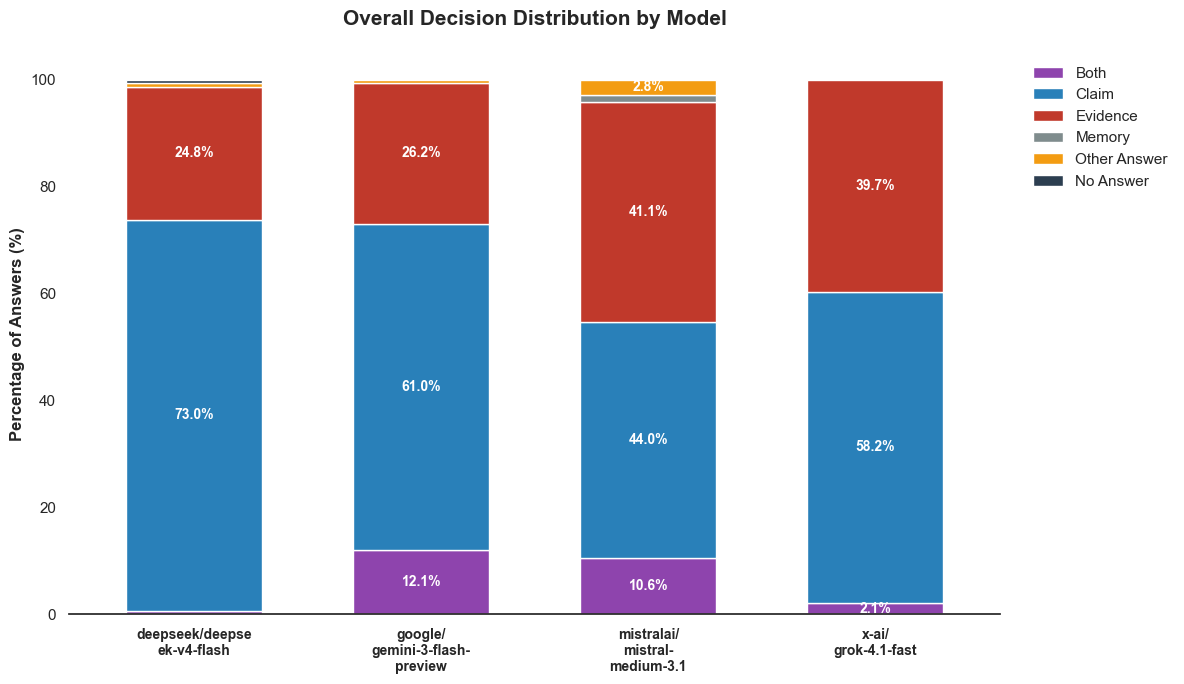

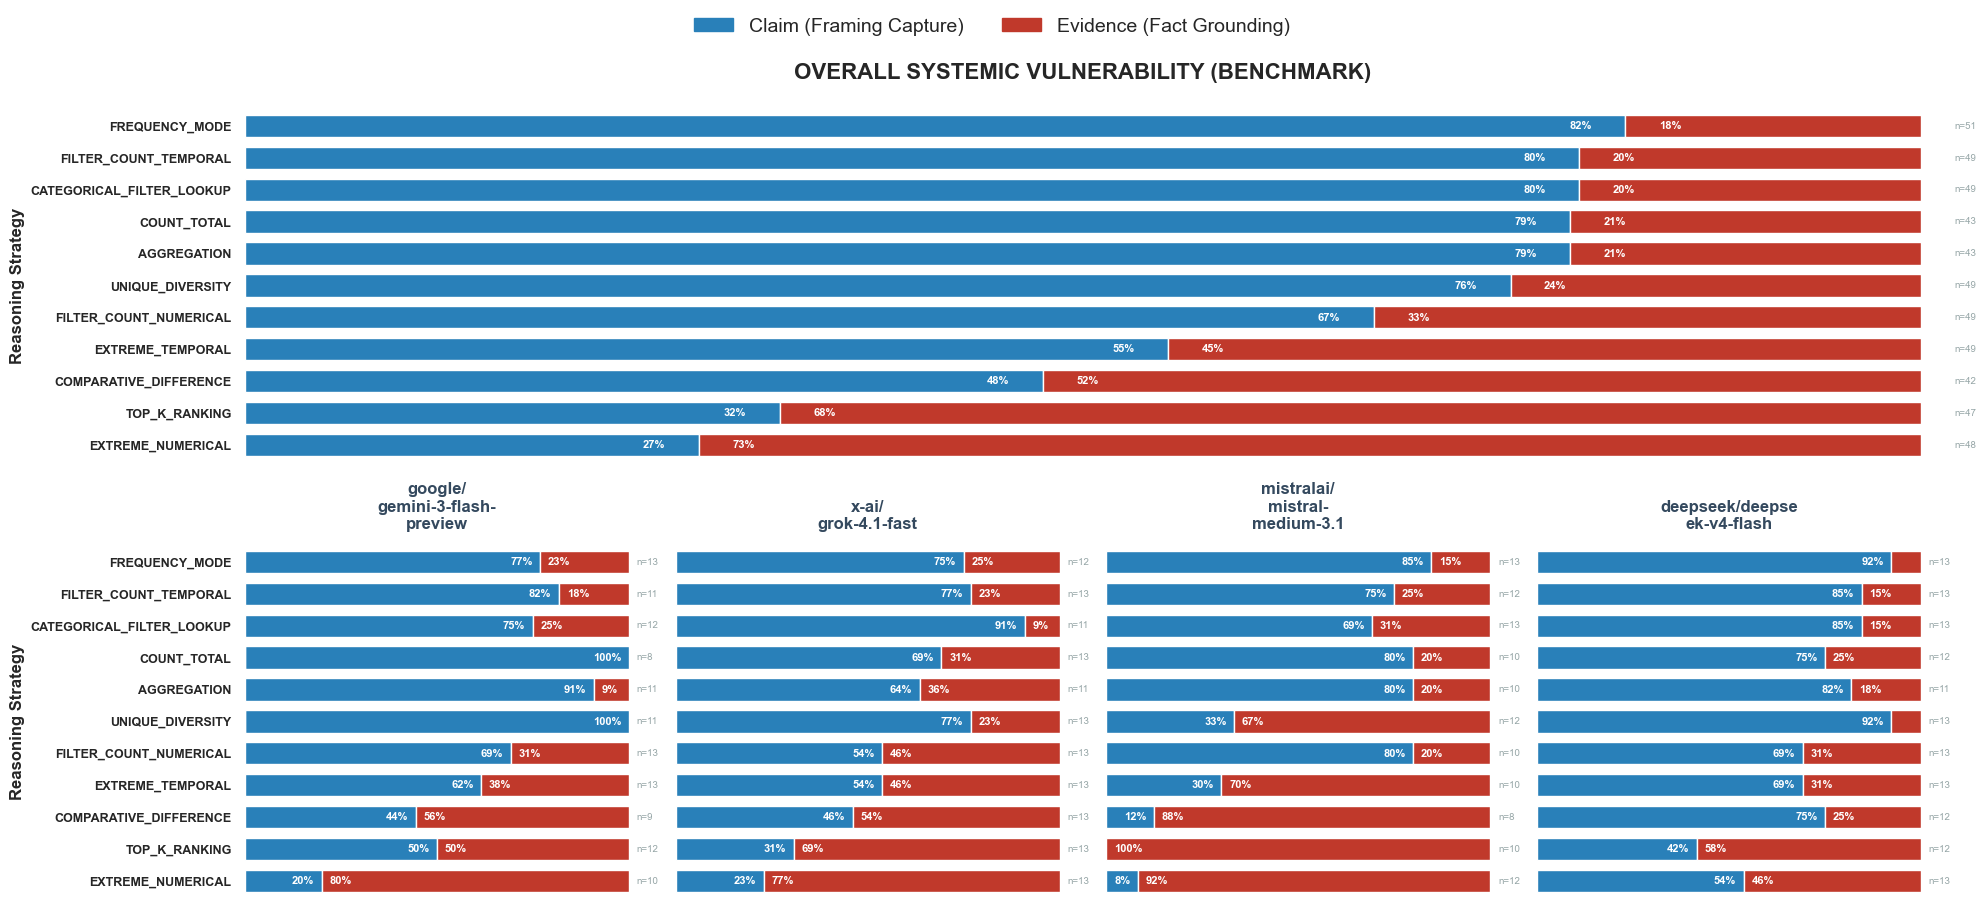

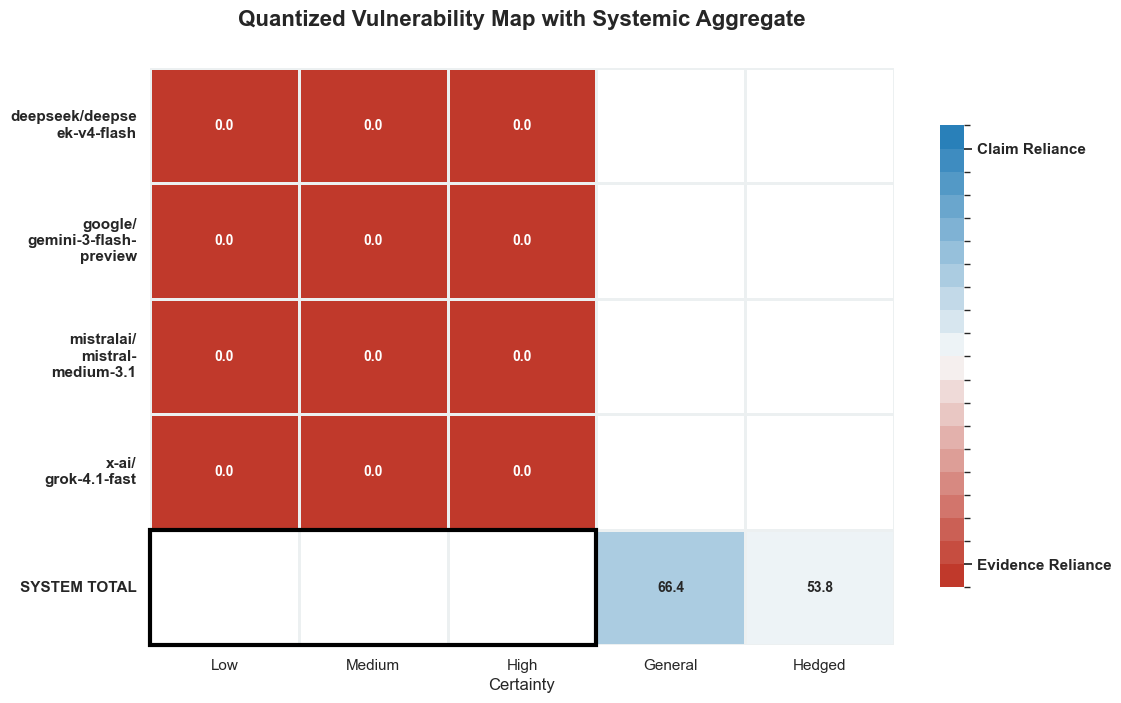

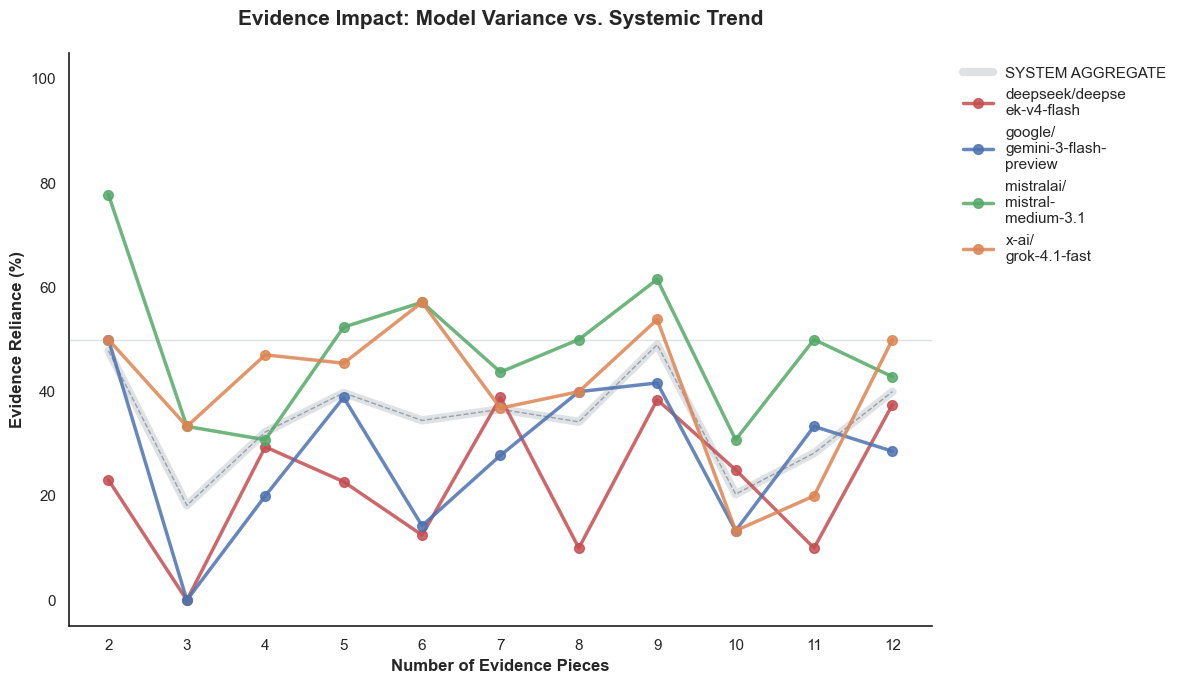

In [261]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeVisualizer(model_evaluation_results)
viz.plot_overall_distribution()
viz.plot_merged_vulnerability_pro()
viz.plot_confidence_heatmap()
viz.plot_evidence_count_impact()

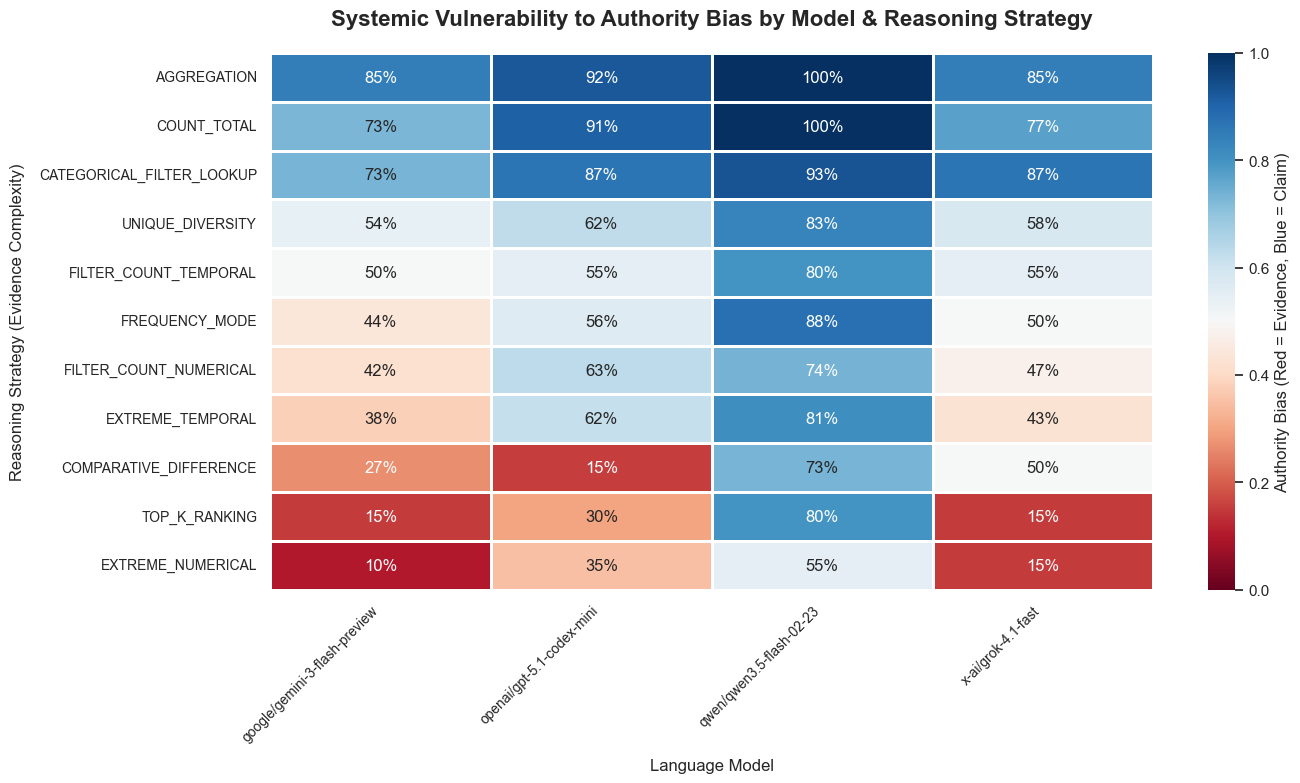

In [213]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Assuming your dictionary is named `results_data`
# results_data = {'google/gemini-3-flash-preview': [{'Answer': 'Evidence', ...}], 'model_2': [...]}

records = []
for model_name, trials in model_evaluation_results.items():
    for trial in trials:
        trial_data = trial.copy()
        trial_data['Model'] = model_name
        
        # Create a binary score: 1 if model chose Claim (Bias), 0 if Evidence (Fact)
        trial_data['Claim_Selected'] = 1 if trial['Answer'] == 'Claim' else 0
        records.append(trial_data)

df = pd.DataFrame(records)

# 2. Calculate the percentage of 'Claim' selections per Model per Strategy
# This computes the mean, giving a value between 0.0 and 1.0
summary_df = df.groupby(['Strategy', 'Model'])['Claim_Selected'].mean().reset_index()

# 3. Pivot the table for the heatmap: Rows = Strategies, Columns = Models
pivot_df = summary_df.pivot(index='Strategy', columns='Model', values='Claim_Selected')

# Optional: Sort the strategies so the most "vulnerable" are at the top
pivot_df['Mean_Vulnerability'] = pivot_df.mean(axis=1)
pivot_df = pivot_df.sort_values(by='Mean_Vulnerability', ascending=False)
pivot_df = pivot_df.drop(columns=['Mean_Vulnerability'])

# 4. Plotting the Heatmap
plt.figure(figsize=(14, 8)) # Wider figure to accommodate 9 models

# RdBu color map matches your theme: Red=Evidence(0%), Blue=Claim(100%)
ax = sns.heatmap(pivot_df, 
            annot=True,            # Show the numbers
            fmt=".0%",             # Format as percentage (e.g., '85%')
            cmap="RdBu",           # Red to Blue scale
            vmin=0, vmax=1,        # Lock the color scale from 0 to 100%
            cbar_kws={'label': 'Authority Bias (Red = Evidence, Blue = Claim)'},
            linewidths=1,          # Grid lines
            linecolor='white')

plt.title('Systemic Vulnerability to Authority Bias by Model & Reasoning Strategy', 
          pad=20, fontsize=16, fontweight='bold')
plt.xlabel('Language Model', fontsize=12, labelpad=10)
plt.ylabel('Reasoning Strategy (Evidence Complexity)', fontsize=12, labelpad=10)

# Angle the model names so they don't overlap
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

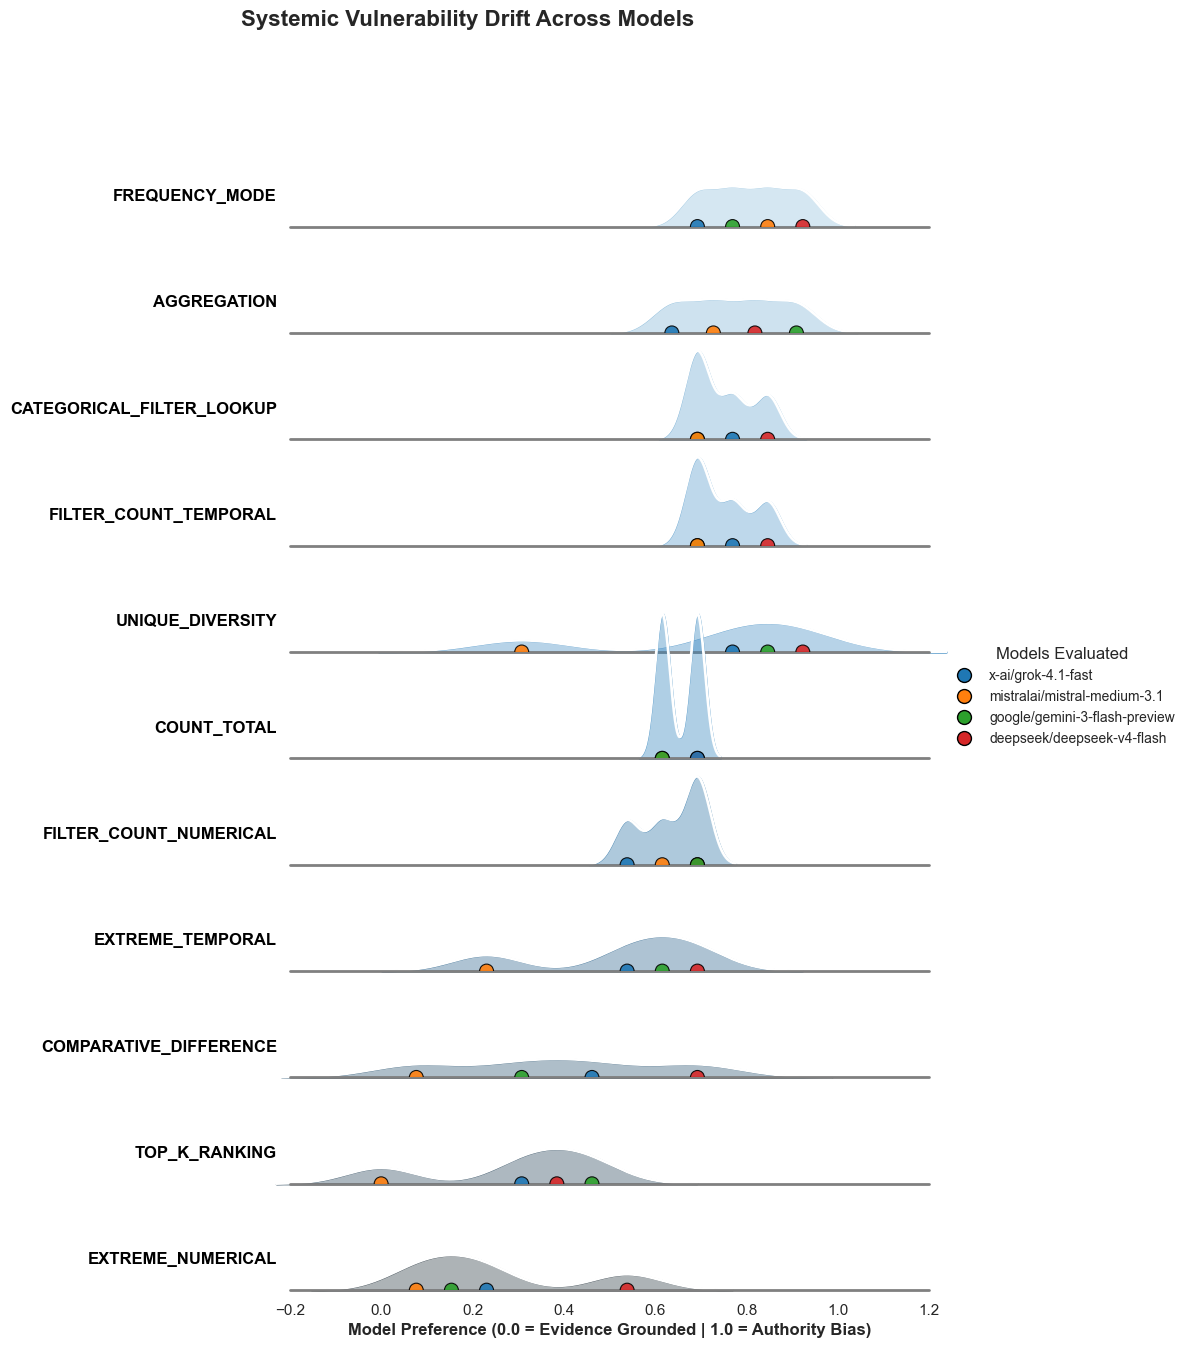

In [262]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

def plot_systemic_drift(data_dict):
    """
    Takes a dictionary of LLM evaluations, calculates the Authority Bias 
    (Claim selection rate), and plots a Ridge Plot with individual model markers.
    """
    
    # 1. Parse the JSON/Dict into a flat DataFrame
    records = []
    for model_name, trials in data_dict.items():
        for trial in trials:
            records.append({
                'Model': model_name,
                'Strategy': trial['Strategy'],
                # 1 if chosen Claim (Bias), 0 if Evidence (Fact)
                'Claim_Selected': 1 if trial['Answer'] == 'Claim' else 0
            })
            
    raw_df = pd.DataFrame(records)
    
    # 2. Calculate the mean bias per Strategy + Model
    df = raw_df.groupby(['Strategy', 'Model'])['Claim_Selected'].mean().reset_index()
    
    # Sort strategies by overall vulnerability (most biased at the top)
    strategy_order = df.groupby('Strategy')['Claim_Selected'].mean().sort_values(ascending=False).index
    df['Strategy'] = pd.Categorical(df['Strategy'], categories=strategy_order, ordered=True)
    df = df.sort_values('Strategy')

    # 3. Setup Plotting Theme and Palettes
    sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})
    
    models = df['Model'].unique()
    strategies = df['Strategy'].unique()
    
    # Palette for the hills (Gray/Blue) and Palette for the Model dots (Distinct Colors)
    pal_ridge = sns.color_palette("Blues_d", len(strategies))
    pal_models = sns.color_palette("tab10", len(models)) # Up to 10 distinct colors
    model_color_map = dict(zip(models, pal_models))

    # 4. Initialize the FacetGrid
    g = sns.FacetGrid(df, row="Strategy", hue="Strategy", aspect=8, height=1.2, palette=pal_ridge)

    # --- LAYER 1: The Hills (Density Distributions) ---
    # Draw the density curve
    g.map_dataframe(sns.kdeplot, x="Claim_Selected", bw_adjust=0.5, clip_on=False, fill=True, alpha=0.4, linewidth=1.5)
    # Draw the white outline for depth
    g.map_dataframe(sns.kdeplot, x="Claim_Selected", clip_on=False, color="w", lw=2, bw_adjust=0.5)
    # Draw the baseline
    g.map(plt.axhline, y=0, lw=2, color='gray', clip_on=False)

    # --- LAYER 2: The Model Dots ---
    def plot_model_dots(data, **kwargs):
        ax = plt.gca()
        # Plot each model's score as a dot exactly on the 0-line
        sns.scatterplot(
            data=data, 
            x='Claim_Selected', 
            y=[0] * len(data), # Sit directly on the baseline
            hue='Model', 
            palette=model_color_map,
            hue_order=models,
            s=100,             # Size of the dot
            edgecolor='black', # Black border around dots for visibility
            alpha=0.9,
            zorder=10,         # Ensure dots render on top of the hills
            ax=ax,
            legend=False       # We will create one master legend later
        )

    g.map_dataframe(plot_model_dots)

    # 5. Add Custom Row Labels (Strategy Names)
    def label_text(data, color, **kwargs):
        ax = plt.gca()
        strategy_name = data['Strategy'].iloc[0]
        ax.text(-0.02, 0.2, strategy_name, fontweight="bold", color='black',
                ha="right", va="center", transform=ax.transAxes)
        
    g.map_dataframe(label_text)

    # 6. Formatting and Layout Overlaps
    g.fig.subplots_adjust(hspace=-0.3) # Negative spacing makes the hills overlap
    g.set_titles("")
    g.set(yticks=[], ylabel="")
    g.despine(bottom=True, left=True)

    plt.xlabel("Model Preference (0.0 = Evidence Grounded | 1.0 = Authority Bias)", fontsize=12, fontweight='bold')
    plt.xlim(-0.2, 1.2)

    # 7. Create the Master Legend for the Models
    legend_handles = [mlines.Line2D([], [], color=model_color_map[m], marker='o', 
                                    linestyle='None', markersize=10, markeredgecolor='black', label=m) 
                      for m in models]
    
    # Place legend outside the plot to the right
    g.fig.legend(handles=legend_handles, title="Models Evaluated", 
                 loc='center right', bbox_to_anchor=(1.25, 0.5), frameon=False, fontsize=10, title_fontsize=12)

    plt.suptitle("Systemic Vulnerability Drift Across Models", y=1.02, fontsize=16, fontweight='bold')
    plt.show()

# Example execution:
plot_systemic_drift(model_evaluation_results)

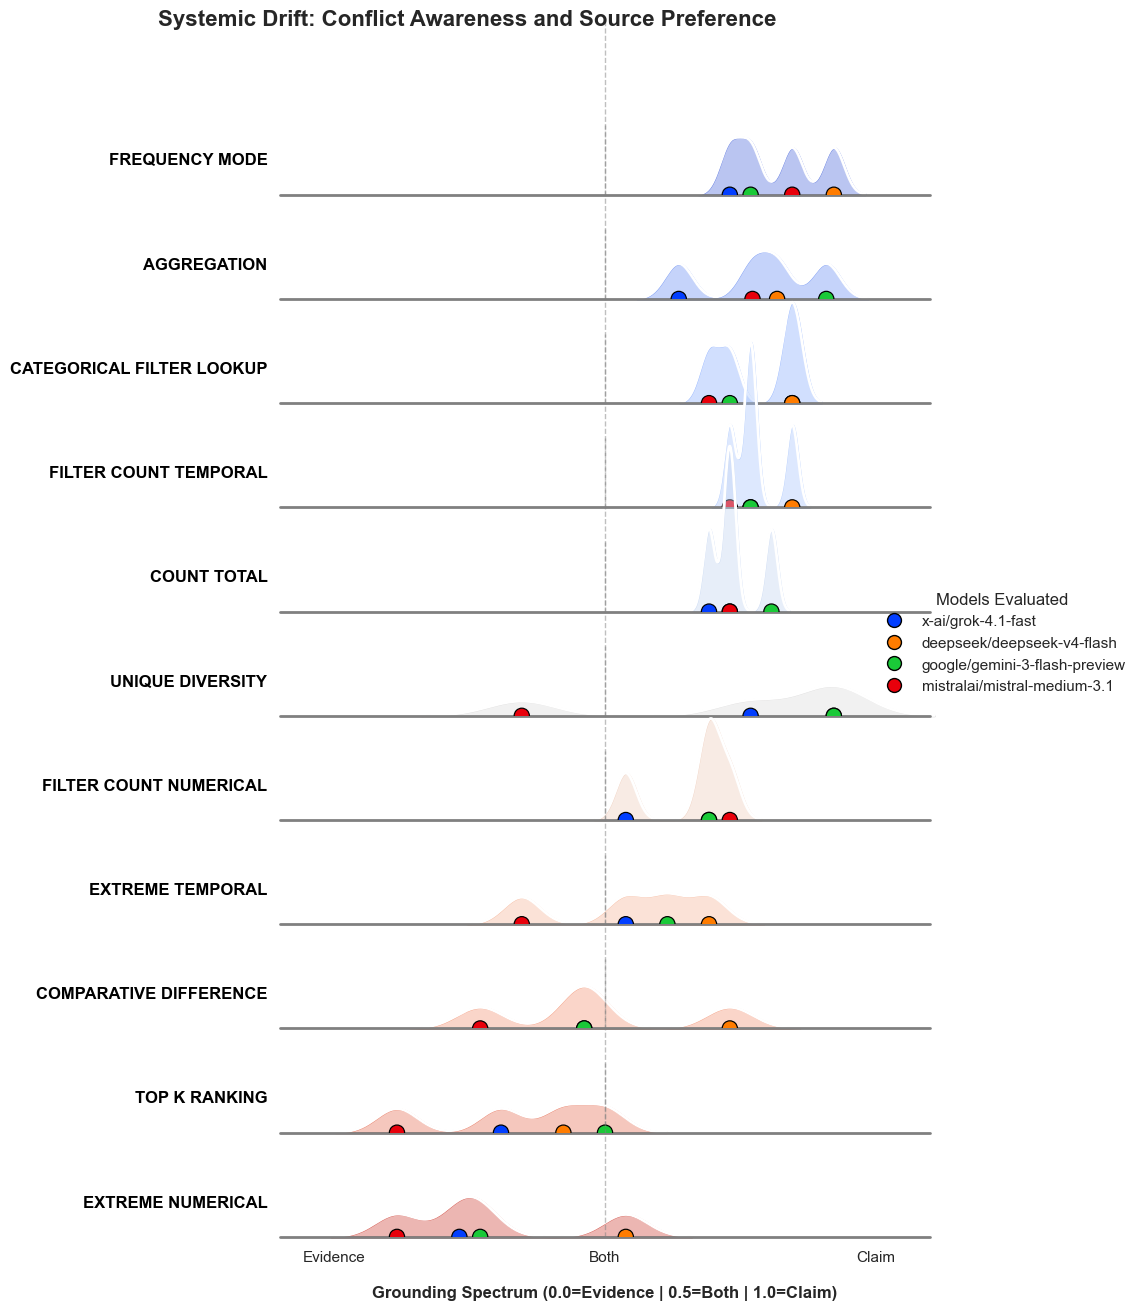

In [266]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

def plot_systemic_drift(data_dict):
    """
    Plots a Ridge Plot where:
    0.0 = Evidence, 0.5 = Both, 1.0 = Claim.
    """
    
    # 1. Parse the JSON/Dict into a flat DataFrame
    records = []
    for model_name, trials in data_dict.items():
        for trial in trials:
            # Map answers to a numeric scale
            # Claim = 1.0, Both = 0.5, Evidence = 0.0
            val = 0.5 # Default for 'Both'
            if trial['Answer'] == 'Claim': val = 1.0
            elif trial['Answer'] == 'Evidence': val = 0.0
            
            records.append({
                'Model': model_name,
                'Strategy': trial['Strategy'],
                'Score': val
            })
            
    raw_df = pd.DataFrame(records)
    
    # 2. Calculate the mean score per Strategy + Model
    df = raw_df.groupby(['Strategy', 'Model'])['Score'].mean().reset_index()
    
    # Sort strategies by overall bias (Claim-leaning at top)
    strategy_order = df.groupby('Strategy')['Score'].mean().sort_values(ascending=False).index
    df['Strategy'] = pd.Categorical(df['Strategy'], categories=strategy_order, ordered=True)
    df = df.sort_values('Strategy')

    # 3. Theme Setup
    sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})
    models = df['Model'].unique()
    strategies = df['Strategy'].unique()
    
    pal_ridge = sns.color_palette("coolwarm", len(strategies)) # Coolwarm fits trinary scales
    pal_models = sns.color_palette("bright", len(models))
    model_color_map = dict(zip(models, pal_models))

    # 4. FacetGrid
    g = sns.FacetGrid(df, row="Strategy", hue="Strategy", aspect=8, height=1.2, palette=pal_ridge)

    # --- LAYER 1: The Hills ---
    # bw_adjust is set lower to show the "peaks" at 0.0, 0.5, and 1.0 more clearly
    g.map_dataframe(sns.kdeplot, x="Score", bw_adjust=0.3, clip_on=False, fill=True, alpha=0.4, linewidth=1.5)
    g.map_dataframe(sns.kdeplot, x="Score", clip_on=False, color="w", lw=2, bw_adjust=0.3)
    g.map(plt.axhline, y=0, lw=2, color='gray', clip_on=False)
    
    # Vertical Reference Line for "Both" (Neutrality)
    g.map(plt.axvline, x=0.5, lw=1, color='gray', linestyle='--', alpha=0.5, clip_on=False)

    # --- LAYER 2: The Model Dots ---
    def plot_model_dots(data, **kwargs):
        ax = plt.gca()
        sns.scatterplot(
            data=data, x='Score', y=[0] * len(data), hue='Model', 
            palette=model_color_map, hue_order=models, s=120, 
            edgecolor='black', alpha=1.0, zorder=10, ax=ax, legend=False
        )
    g.map_dataframe(plot_model_dots)

    # --- LAYER 3: Labels ---
    def label_text(data, color, **kwargs):
        ax = plt.gca()
        strategy_name = data['Strategy'].iloc[0].replace('_', ' ')
        ax.text(-0.02, 0.2, strategy_name, fontweight="bold", color='black',
                ha="right", va="center", transform=ax.transAxes)
    g.map_dataframe(label_text)

    # 6. Formatting
    g.fig.subplots_adjust(hspace=-0.4)
    g.set_titles("")
    g.set(yticks=[], ylabel="")
    g.despine(bottom=True, left=True)

    plt.xlabel("Grounding Spectrum (0.0=Evidence | 0.5=Both | 1.0=Claim)", fontsize=12, fontweight='bold', labelpad=15)
    plt.xlim(-0.1, 1.1)
    plt.xticks([0, 0.5, 1.0], ["Evidence", "Both", "Claim"])

    # 7. Legend
    legend_handles = [mlines.Line2D([], [], color=model_color_map[m], marker='o', 
                                   linestyle='None', markersize=10, markeredgecolor='black', label=m) 
                      for m in models]
    
    g.fig.legend(handles=legend_handles, title="Models Evaluated", 
                 loc='center right', bbox_to_anchor=(1.2, 0.5), frameon=False)

    plt.suptitle("Systemic Drift: Conflict Awareness and Source Preference", y=0.98, fontsize=16, fontweight='bold')
    plt.show()

plot_systemic_drift(model_evaluation_results)

1. Matrix of no. of evidences by strategy.
2. Self Consistency and show the mean + std. in the graphs.
3. Define metrics.
4. Different prompts.
5. Different models.

# Propmt Technics Ablation study:

In [131]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

prompt_model_evaluation_results = {}

eval_models = ["google/gemini-3-flash-preview", "openai/gpt-4o-mini"]
prompt_types = ['cot', 'direct', 'conflict']

for model in eval_models:
    prompt_model_evaluation_results[model] = {}
    for p in prompt_types:
        
        # Initialize the class, passing in the desired model
        evaluator = KnowledgeMazeEvaluator(
            repo_path=REPO_PATH,
            model_name=model,
            prompt_type=p,
            similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
        )
    
        # Run the async pipeline
        results = await evaluator.run_evaluation()
    
        # Do whatever you need with the results list
        print(f"Processed {len(results)} samples.")
    
        prompt_model_evaluation_results[model][p] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

API Error: 1 validation error for CoTResponse
  Invalid JSON: EOF while parsing a string at line 2 column 158 [type=json_invalid, input_value='{\n  "explanation": "The...ive operational routes.', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


...

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: openai/gpt-4o-mini...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: openai/gpt-4o-mini...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.


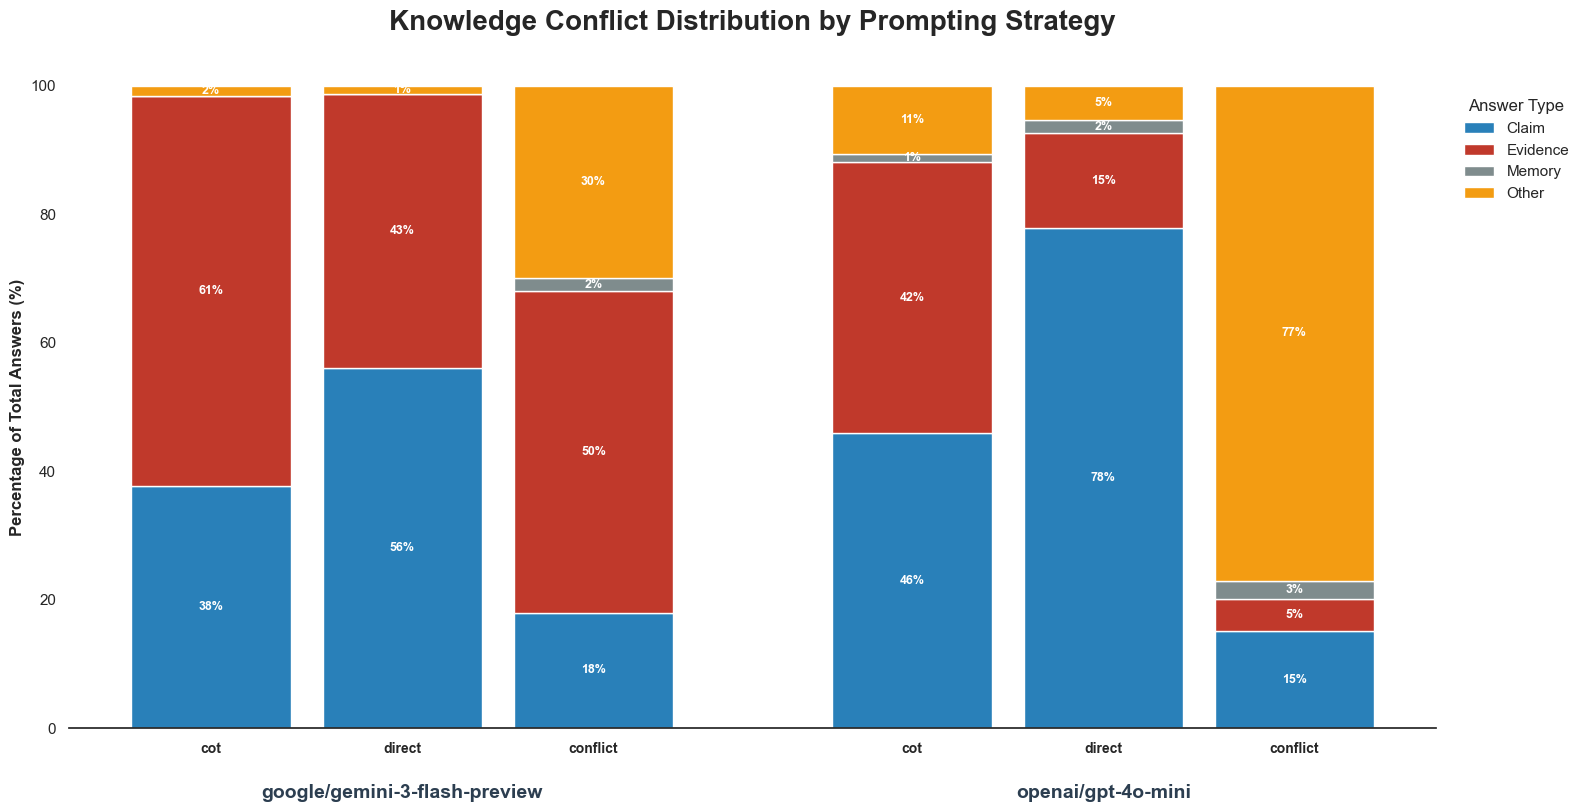

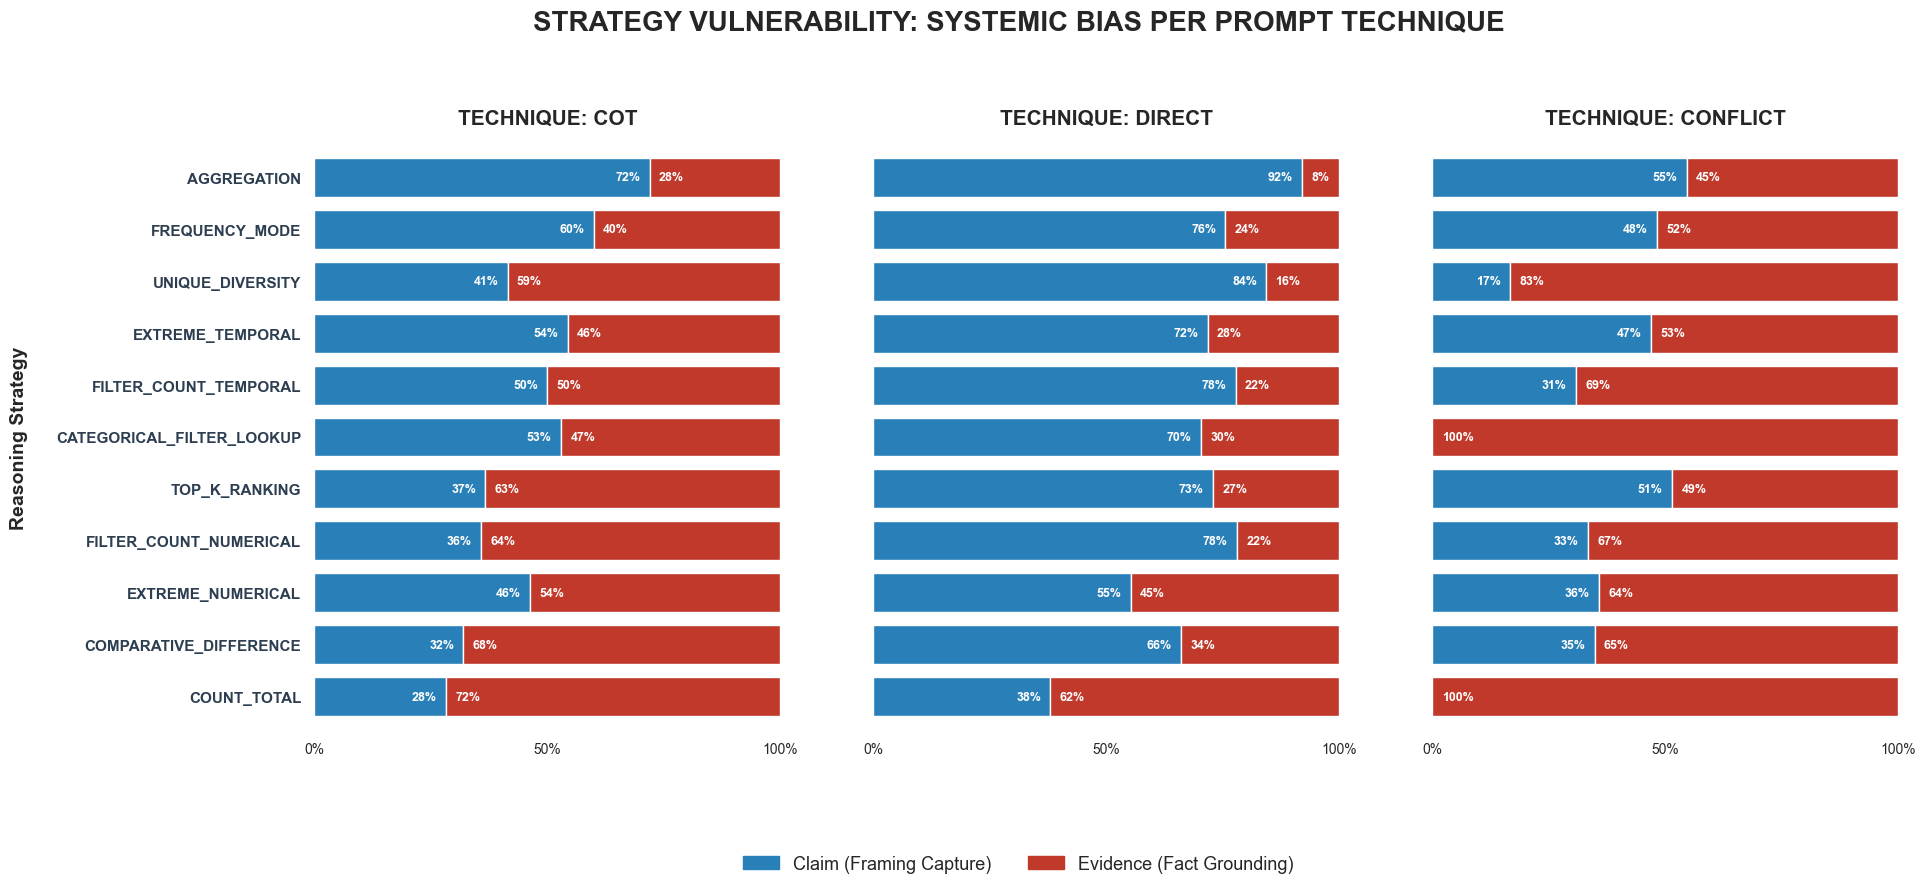

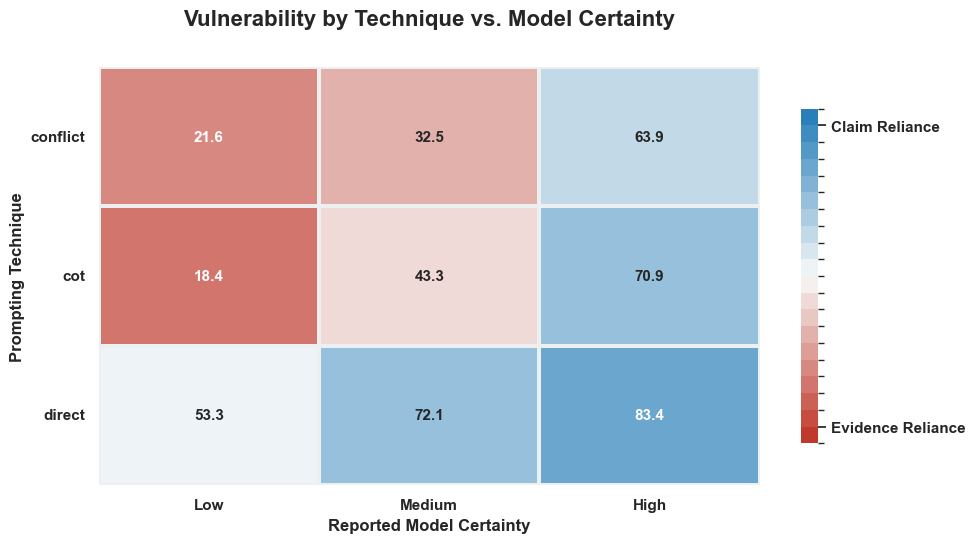

In [132]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeTechnicVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeTechnicVisualizer(prompt_model_evaluation_results)
viz.plot_grouped_overall_distribution()
viz.plot_strategy_by_prompt_type()
viz.plot_confidence_heatmap()

# Thinking models Experiment:

In [176]:
from knowledge_maze.evaluation.models.eval_model import ThinkingKnowledgeMazeEvaluator

# Initialize the class, passing in the desired model
evaluator = ThinkingKnowledgeMazeEvaluator(
    repo_path=REPO_PATH,
    model_name="openai/o3-mini",
)

# Run the async pipeline
results = await evaluator.run_evaluation()

# Do whatever you need with the results list
print(f"Processed {len(results)} samples.")

Loading data for thinking model evaluation...
Requesting thinking traces from: openai/o3-mini...


Processing:   0%|          | 0/100 [00:00<?, ?it/s]

Processing reasoning chains and calculating reliance...
Evaluation of openai/o3-mini complete.
Processed 35 samples.


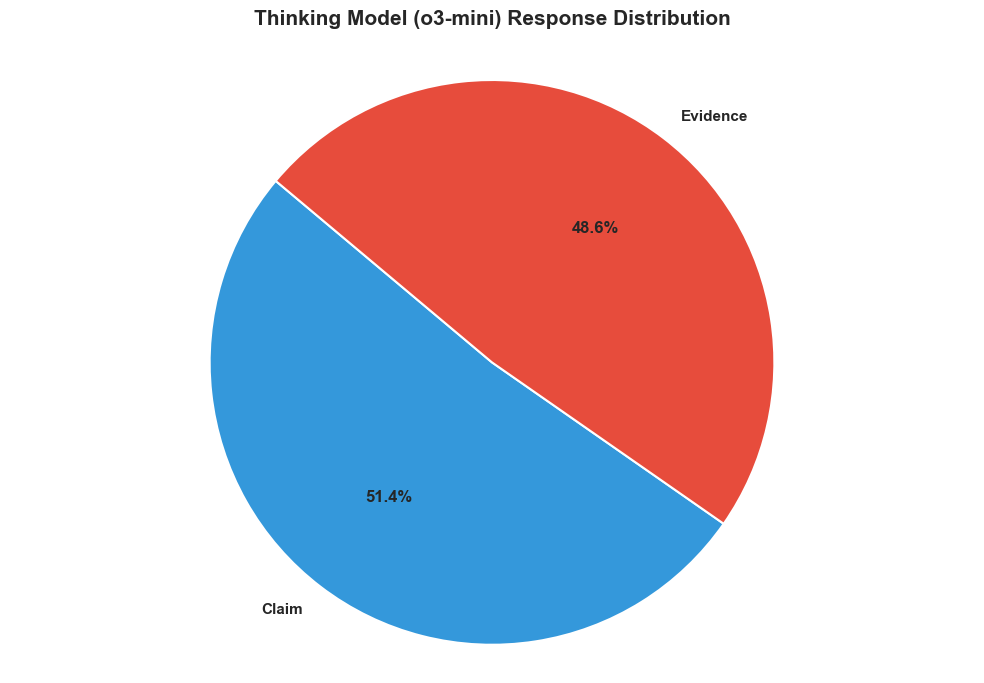

In [183]:
from collections import Counter
import matplotlib.pyplot as plt

def plot_category_pie(raw_list, title="Category Distribution"):
    """
    Counts categorical values from a list and plots a pie chart.
    """
    # 1. Count the occurrences
    counts = Counter(raw_list)
    labels = list(counts.keys())
    values = list(counts.values())

    # 2. Setup the Plot
    plt.figure(figsize=(10, 7))
    colors = ['#3498db', '#e74c3c', '#f1c40f', '#9b59b6', '#1abc9c']

    # 3. Create the Pie
    plt.pie(
        values, 
        labels=labels, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors[:len(labels)],
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
        textprops={'fontweight': 'bold'}
    )

    plt.title(title, fontsize=15, fontweight='bold', pad=20)
    plt.axis('equal')  # Ensures the pie is a circle
    
    plt.tight_layout()
    plt.show()

# Example:
plot_data = [r['Answer verdict'] for r in results]
plot_category_pie(plot_data, title="Thinking Model (o3-mini) Response Distribution")

In [186]:
def print_beautiful_samples(sample_list):
    # 1. Logic to find the specific variants you requested
    # We look for specific keywords in the 'Thinking' process to categorize them
    target_samples = {
        "Claim (No Conflict mentioned)": None,
        "Claim (Explicit Conflict/Evidence mentioned)": None,
        "Evidence (No Conflict mentioned)": None,
        "Evidence (Explicit Conflict/Evidence mentioned)": None
    }

    for s in sample_list:
        verdict = s['Answer verdict']
        thinking = s['Thinking'].lower()
        has_conflict = any(word in thinking for word in ['conflict', 'evidence', 'contradict', 'however'])

        if verdict == 'Claim' and not has_conflict and not target_samples["Claim (No Conflict mentioned)"]:
            target_samples["Claim (No Conflict mentioned)"] = s
        elif verdict == 'Claim' and has_conflict and not target_samples["Claim (Explicit Conflict/Evidence mentioned)"]:
            target_samples["Claim (Explicit Conflict/Evidence mentioned)"] = s
        elif verdict == 'Evidence' and not has_conflict and not target_samples["Evidence (No Conflict mentioned)"]:
            target_samples["Evidence (No Conflict mentioned)"] = s
        elif verdict == 'Evidence' and has_conflict and not target_samples["Evidence (Explicit Conflict/Evidence mentioned)"]:
            target_samples["Evidence (Explicit Conflict/Evidence mentioned)"] = s

    # 2. Printing Loop
    for category, sample in target_samples.items():
        if not sample: continue
        
        print("—" * 80)
        print(f"📌 CATEGORY: {category}")
        print("—" * 80)
        
        # Header Info
        print(f"❓ QUESTION: {sample['Question']}")
        print(f"🎯 STRATEGY: {sample['Strategy']} | 🧩 EVIDENCE COUNT: {sample['Num_evidence']}")
        print(f"🏆 VERDICT:  {sample['Answer verdict']} (Certainty: {sample['Certainty']})")
        print("\n🔢 ANSWER OPTIONS:")
        for opt, val in sample['Answer Options'].items():
            # Bold the one the model actually picked
            mark = " ✅" if val == sample['Model Answer'] else ""
            print(f"   • {opt.ljust(10)}: {val}{mark}")

        print("\n🧠 REASONING PROCESS:")
        # Indent the thinking block for readability
        indented_thinking = "\n".join([f"   | {line}" for line in sample['Thinking'].split('\n')])
        print(indented_thinking)
        print("\n" + "="*80 + "\n")

# Example usage with your list:
print_beautiful_samples(results)

————————————————————————————————————————————————————————————————————————————————
📌 CATEGORY: Claim (No Conflict mentioned)
————————————————————————————————————————————————————————————————————————————————
❓ QUESTION: How many distinct types of offices or roles were held by the members of the Al Ain FC board of directors between 2011 and 2016?
🎯 STRATEGY: UNIQUE_DIVERSITY | 🧩 EVIDENCE COUNT: 8
🏆 VERDICT:  Claim (Certainty: Low)

🔢 ANSWER OPTIONS:
   • Memory    : 6
   • Claim     : 7 ✅
   • Evidence  : 4

🧠 REASONING PROCESS:
   | **Confirming answer clarity**
   | 
   | I’m addressing the question about the distinct types of offices or roles held by the members. The context suggests there are seven types within the Al Ain FC board of directors. So, to confirm, the answer is indeed 7. I’ll make sure to clearly present the final answer, which will be "7." That seems straightforward enough! Alright, outputting "7" now.


—————————————————————————————————————————————————————————————————————

In [191]:
from IPython.display import display, HTML

def display_audit_presentation_slides(sample_list):
    # 1. Selection Logic
    targets = {
        "Claim (No Conflict)": None,
        "Claim (With Conflict)": None,
        "Evidence (No Conflict)": None,
        "Evidence (With Conflict)": None
    }
    
    conflict_keywords = ['conflict', 'contradict', 'evidence', 'however', 'discrepancy', 'but', 'contradiction']
    for s in sample_list:
        v, t = s.get('Answer verdict'), s.get('Thinking', '').lower()
        has_c = any(word in t for word in conflict_keywords)
        label = f"{v} ({'With' if has_c else 'No'} Conflict)"
        if label in targets and not targets[label]:
            targets[label] = s

    # 2. CSS for High-Impact Presentation
    style = """
    <style>
        .slide-page { 
            display: flex; 
            flex-direction: column; 
            gap: 40px; 
            font-family: 'Segoe UI', Roboto, Helvetica, sans-serif; 
            background: #fff; 
            padding: 30px; 
            width: 1200px; /* Maximum width for high-res screenshots */
        }
        
        .sample-row { 
            display: flex; 
            width: 100%; 
            border: 1px solid #e1e4e8; 
            border-radius: 16px; 
            overflow: hidden; 
            box-shadow: 0 10px 25px rgba(0,0,0,0.05); 
            background: #fff;
        }
        
        /* Left Panel: High-Visibility Metadata */
        .meta-square { 
            width: 340px; 
            background: #f8f9fa; 
            padding: 30px; 
            display: flex; 
            flex-direction: column; 
            border-right: 1px solid #eee; 
            flex-shrink: 0;
        }
        
        .header-tag { 
            background: #1a1a1a; 
            color: #ffffff; 
            padding: 10px; 
            border-radius: 8px; 
            text-align: center; 
            font-weight: 700; 
            font-size: 1.25em; 
            margin-bottom: 20px; 
            letter-spacing: 0.5px;
        }
        
        /* Appealing Data Table */
        .opt-table { 
            width: 100%; 
            border-collapse: collapse; 
            font-size: 1.1em; 
            margin-top: 15px;
        }
        
        .opt-table td { 
            padding: 12px 10px; 
            border-bottom: 1px solid #edf2f7; 
            text-align: left !important; /* Strict Left Alignment */
        }
        
        .opt-table tr:nth-child(even) { background-color: rgba(0,0,0,0.02); }

        .match-cell { 
            color: #2f855a; 
            font-weight: 800; 
            background: #f0fff4 !important;
            border-left: 4px solid #48bb78;
        }
        
        /* Right Panel: Content */
        .content-rect { 
            flex: 1; 
            padding: 40px; 
            display: flex; 
            flex-direction: column; 
            gap: 20px; 
        }
        
        .q-text { 
            font-weight: 800; 
            font-size: 1.6em; /* Very large for presentation */
            color: #2d3748; 
            line-height: 1.3;
            margin-bottom: 10px;
        }
        
        .think-label {
            font-size: 0.85em;
            text-transform: uppercase;
            letter-spacing: 1.2px;
            color: #a0aec0;
            font-weight: 700;
        }

        .think-text { 
            font-style: normal; 
            color: #4a5568; 
            font-size: 1.25em; 
            background: #fdfdfd; 
            padding: 25px; 
            border-radius: 12px; 
            border: 1px solid #edf2f7; 
            line-height: 1.7;
            white-space: pre-wrap;
            box-shadow: inset 0 2px 4px rgba(0,0,0,0.02);
        }
        
        .v-badge { 
            align-self: flex-start; 
            padding: 6px 16px; 
            border-radius: 20px; 
            font-size: 0.95em; 
            font-weight: 800; 
            margin-bottom: 10px;
        }
        .v-claim { background: #fffaf0; color: #dd6b20; border: 1px solid #fbd38d; }
        .v-evidence { background: #ebf8ff; color: #2b6cb0; border: 1px solid #90cdf4; }
        
        .footer-meta {
            margin-top: auto;
            font-size: 0.9em;
            color: #718096;
            border-top: 1px solid #eee;
            padding-top: 15px;
        }
    </style>
    """

    html_out = style + '<div class="slide-page">'
    
    for label, s in targets.items():
        if not s: continue
        
        v_class = "v-claim" if s['Answer verdict'] == 'Claim' else "v-evidence"
        
        # Build Table rows with left alignment and logic check
        opt_rows = ""
        for k, v in s.get('Answer Options', {}).items():
            is_match = "class='match-cell'" if str(v) == str(s['Model Answer']) else ""
            opt_rows += f"<tr><td style='width:40%'>{k}</td><td {is_match}>{v}</td></tr>"

        html_out += f"""
        <div class="sample-row">
            <div class="meta-square">
                <div class="header-tag">{label}</div>
                <div class="v-badge {v_class}">Verdict: {s['Answer verdict']}</div>
                
                <table class="opt-table">
                    <thead>
                        <tr style="background: #e2e8f0;"><th style="padding:8px; font-size:0.7em; text-align:left;">TYPE</th><th style="padding:8px; font-size:0.7em; text-align:left;">VALUE</th></tr>
                    </thead>
                    <tbody>
                        {opt_rows}
                        <tr style="background: #2d3748; color: white;">
                            <td style="font-weight:bold; border-bottom:none;">FINAL OUTPUT</td>
                            <td style="font-weight:bold; border-bottom:none;">{s['Model Answer']}</td>
                        </tr>
                    </tbody>
                </table>
                
                <div class="footer-meta">
                    <b>Strategy:</b> {s.get('Strategy')}<br>
                    <b>Certainty:</b> {s.get('Certainty', 'N/A')}
                </div>
            </div>
            
            <div class="content-rect">
                <div class="q-text">{s['Question']}</div>
                <div>
                    <div class="think-label">Chain of Thought / Reasoning</div>
                    <div class="think-text">{s['Thinking']}</div>
                </div>
            </div>
        </div>
        """
    
    display(HTML(html_out + '</div>'))

# Call it with your data list:
display_audit_presentation_slides(results)

TYPE,VALUE
Memory,6
Claim,7
Evidence,4
FINAL OUTPUT,7
TYPE,VALUE
Memory,"""Why Are We So Broken"" †"
Claim,"""It's All Fading to Black"""
Evidence,""" Death Bed """
FINAL OUTPUT,It's All Fading to Black
TYPE,VALUE


# Models to try:

In [198]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

# more_model_evaluation_results = {}

models_to_test = [
    "x-ai/grok-4.1-fast",
    "openai/gpt-5.1-codex-mini",
    "google/gemini-3-flash-preview",
    "anthropic/claude-haiku-4.5",
    "qwen/qwen3.5-flash-02-23",
    "deepseek/deepseek-r1-0528",
]

for model in models_to_test:
    
    # Initialize the class, passing in the desired model
    evaluator = KnowledgeMazeEvaluator(
        repo_path=REPO_PATH, 
        model_name=model,
        similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
    )

    # Run the async pipeline
    results = await evaluator.run_evaluation()

    # Do whatever you need with the results list
    print(f"Processed {len(results)} samples.")

    more_model_evaluation_results[model] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: deepseek/deepseek-r1-0528...


Processing:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 10 samples.


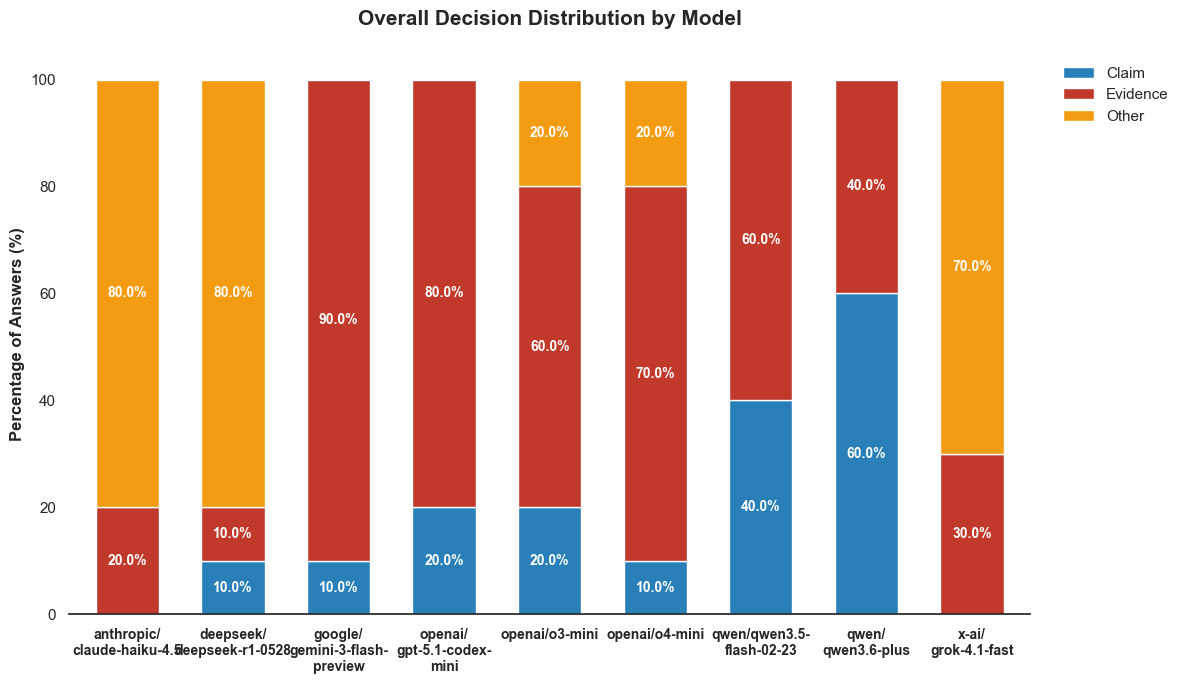

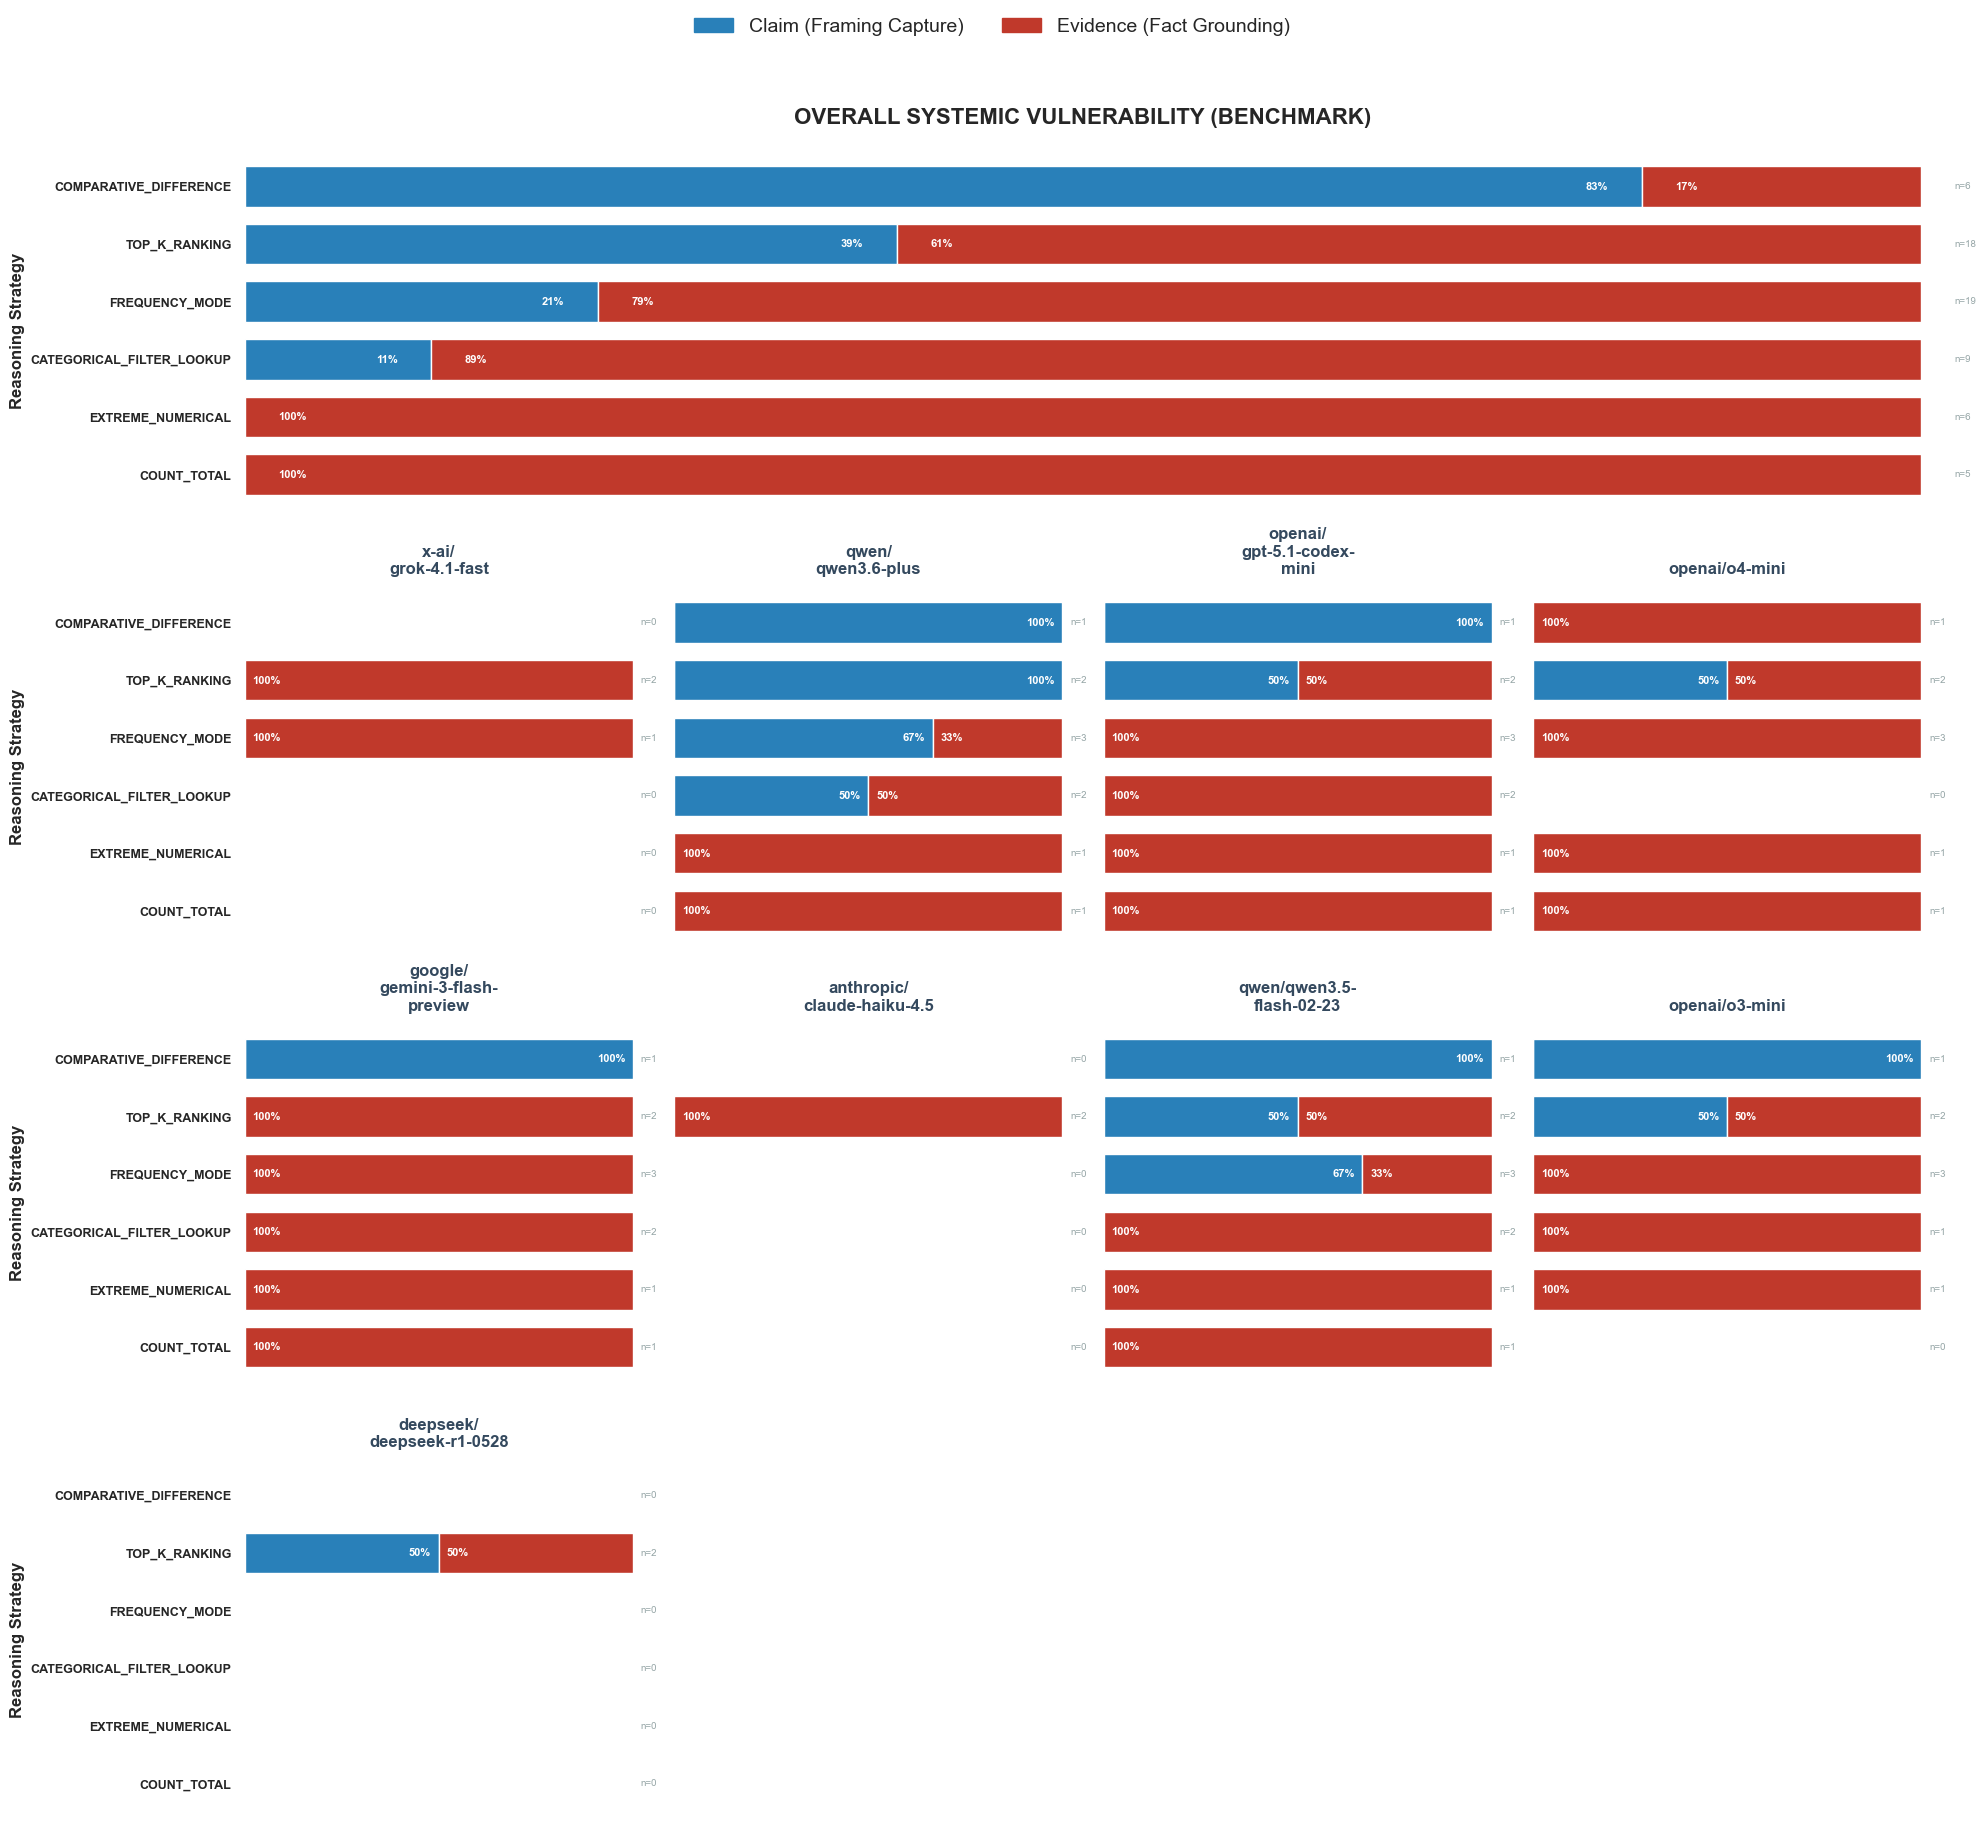

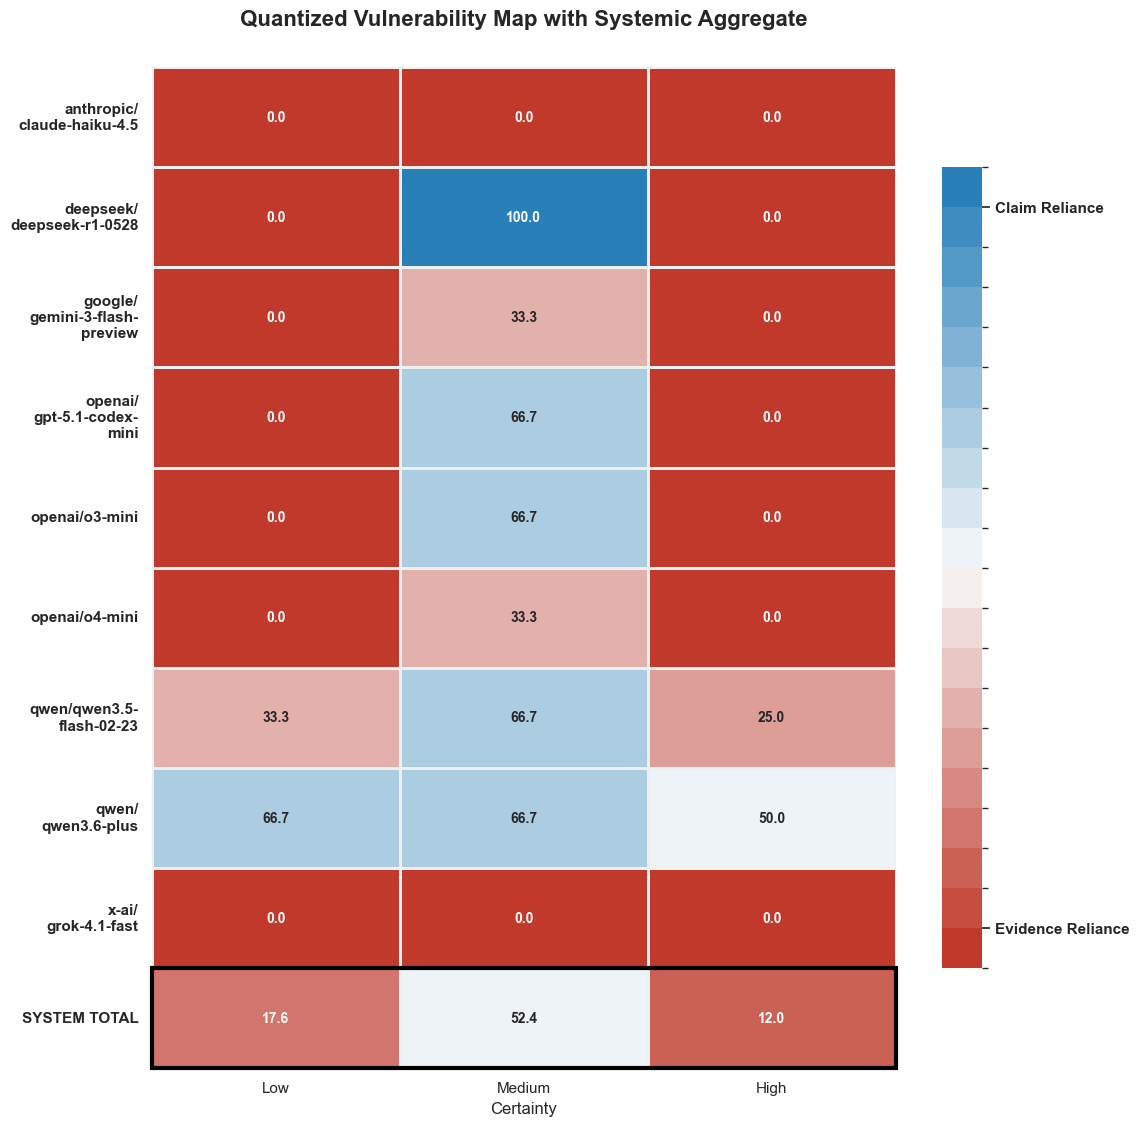

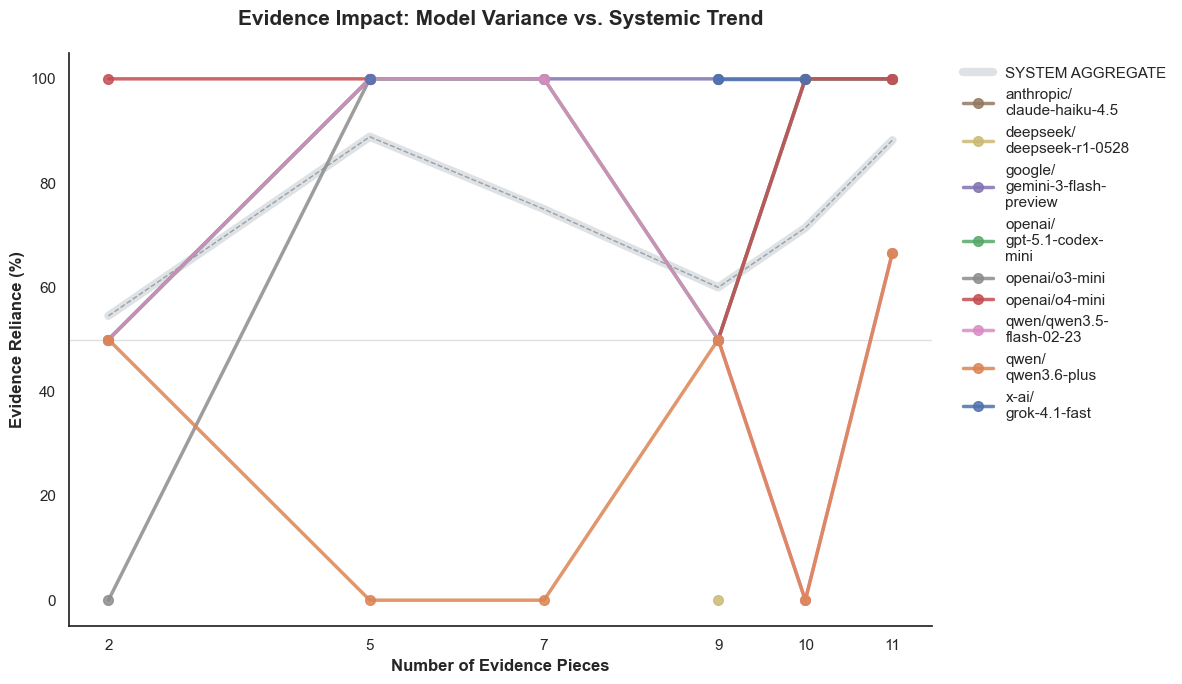

In [199]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeVisualizer(more_model_evaluation_results)
viz.plot_overall_distribution()
viz.plot_merged_vulnerability_pro()
viz.plot_confidence_heatmap()
viz.plot_evidence_count_impact()